# Import

import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import pickle

In [4]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import pickle

# Load data

In [5]:
train = pd.read_csv("D:/Trung/Python/Lab4/data/train.csv")
test = pd.read_csv("D:/Trung/Python/Lab4/data/test.csv")

print("Train:", train.shape)
print("Test :", test.shape)

Train: (1460, 81)
Test : (1459, 80)


# Xác định tính chất

## Tổng quan

In [6]:
train.head()
train.info()
train.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


## Numerical / Categorical

In [7]:
num_cols = train.select_dtypes(include=np.number).columns
cat_cols = train.select_dtypes(exclude=np.number).columns

print("Số biến numerical:", len(num_cols))
print("Số biến categorical:", len(cat_cols))

print("\nNumerical:")
print(num_cols.tolist())

print("\nCategorical:")
print(cat_cols.tolist())

Số biến numerical: 38
Số biến categorical: 43

Numerical:
['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold', 'SalePrice']

Categorical:
['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'Kitche

## Phân loại biến

In [8]:
continuous_vars = [
    "LotFrontage", "LotArea", "MasVnrArea",
    "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF",
    "TotalBsmtSF", "1stFlrSF", "2ndFlrSF",
    "LowQualFinSF", "GrLivArea", "GarageArea",
    "WoodDeckSF", "OpenPorchSF", "EnclosedPorch",
    "3SsnPorch", "ScreenPorch", "PoolArea", "MiscVal",
    "SalePrice"
]

discrete_vars = [
    "BsmtFullBath", "BsmtHalfBath",
    "FullBath", "HalfBath",
    "BedroomAbvGr", "KitchenAbvGr",
    "TotRmsAbvGrd", "Fireplaces",
    "GarageCars", "GarageYrBlt",
    "YearBuilt", "YearRemodAdd",
    "MoSold", "YrSold"
]

nominal_vars = [
    "MSSubClass", "MSZoning", "Street", "Alley",
    "LandContour", "LotConfig", "Neighborhood",
    "Condition1", "Condition2", "BldgType",
    "HouseStyle", "RoofStyle", "RoofMatl",
    "Exterior1st", "Exterior2nd", "MasVnrType",
    "Foundation", "Heating", "CentralAir",
    "GarageType", "MiscFeature", "SaleType",
    "SaleCondition"
]

ordinal_vars = [
    "LotShape", "Utilities", "LandSlope",
    "OverallQual", "OverallCond",
    "ExterQual", "ExterCond",
    "BsmtQual", "BsmtCond", "BsmtExposure",
    "BsmtFinType1", "BsmtFinType2",
    "HeatingQC", "KitchenQual", "Functional",
    "FireplaceQu", "GarageFinish",
    "GarageQual", "GarageCond",
    "PavedDrive", "PoolQC", "Fence", "Electrical"
]

In [9]:
print("=== CONTINUOUS VARIABLES ===")
print(continuous_vars)

print("\n=== DISCRETE VARIABLES ===")
print(discrete_vars)

print("\n=== NOMINAL VARIABLES ===")
print(nominal_vars)

print("\n=== ORDINAL VARIABLES ===")
print(ordinal_vars)

=== CONTINUOUS VARIABLES ===
['LotFrontage', 'LotArea', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'SalePrice']

=== DISCRETE VARIABLES ===
['BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'GarageYrBlt', 'YearBuilt', 'YearRemodAdd', 'MoSold', 'YrSold']

=== NOMINAL VARIABLES ===
['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir', 'GarageType', 'MiscFeature', 'SaleType', 'SaleCondition']

=== ORDINAL VARIABLES ===
['LotShape', 'Utilities', 'LandSlope', 'OverallQual', 'OverallCond', 'ExterQual', 'ExterCond', 'BsmtQual', '

# Phân tích đơn biến

## Target Variable

In [10]:
train["SalePrice"].describe()

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64

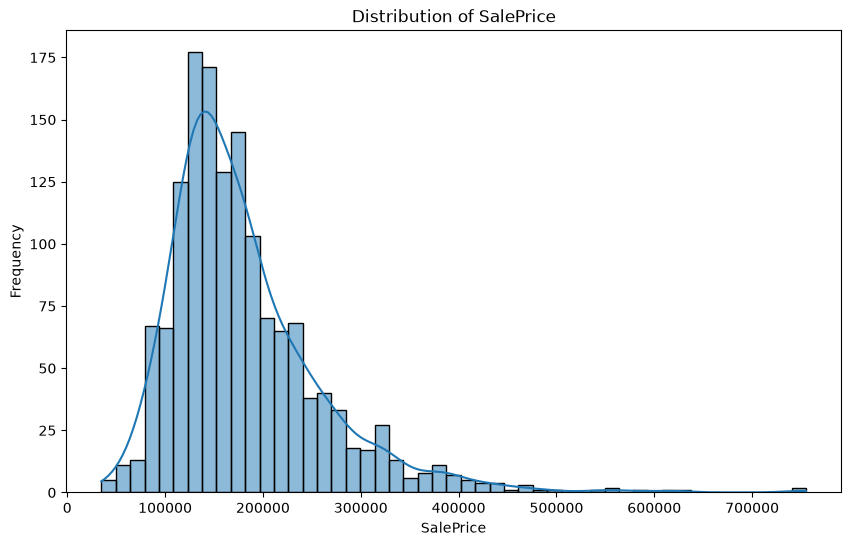

In [11]:
plt.figure(figsize=(10, 6))

sns.histplot(train["SalePrice"], kde=True)

plt.title("Distribution of SalePrice")
plt.xlabel("SalePrice")
plt.ylabel("Frequency")

plt.savefig("saleprice_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

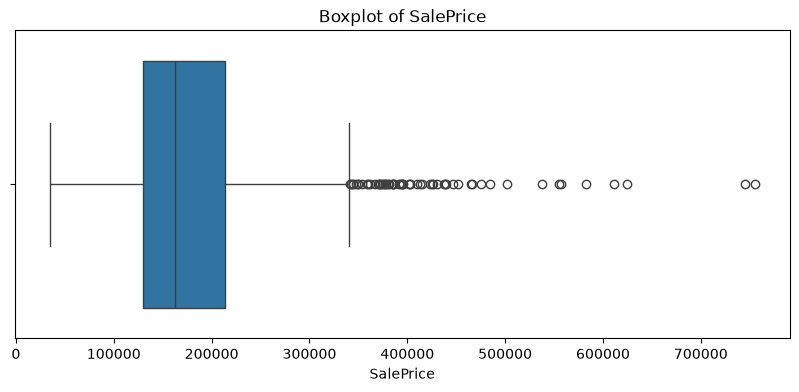

In [12]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=train["SalePrice"])

plt.title("Boxplot of SalePrice")
plt.xlabel("SalePrice")
plt.savefig("saleprice_boxplot.png", dpi=300, bbox_inches='tight')
plt.show()

## Continuos Variable

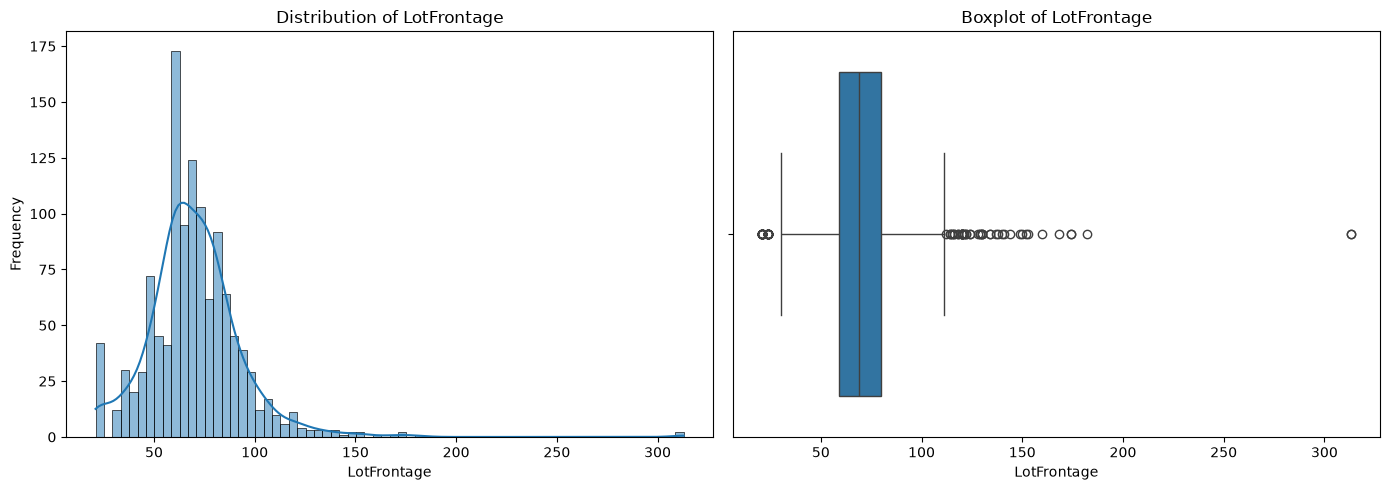

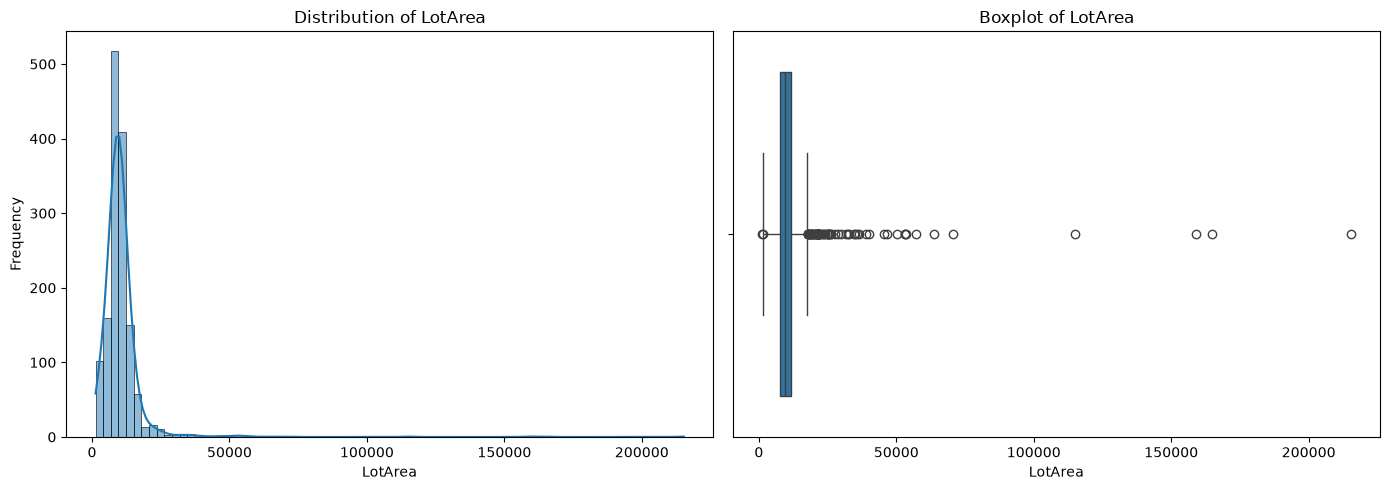

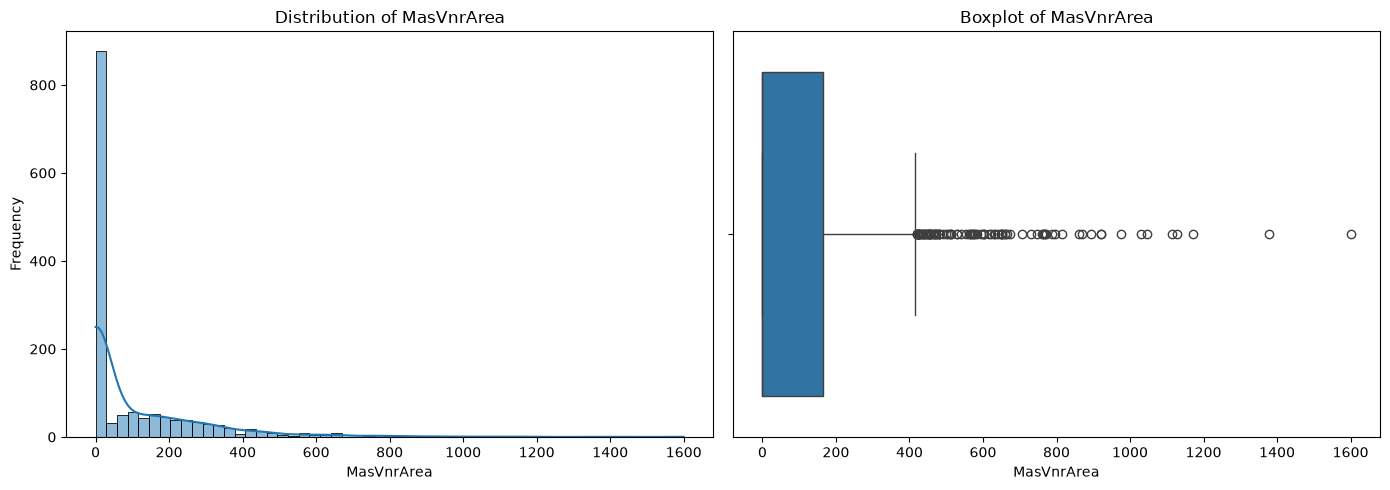

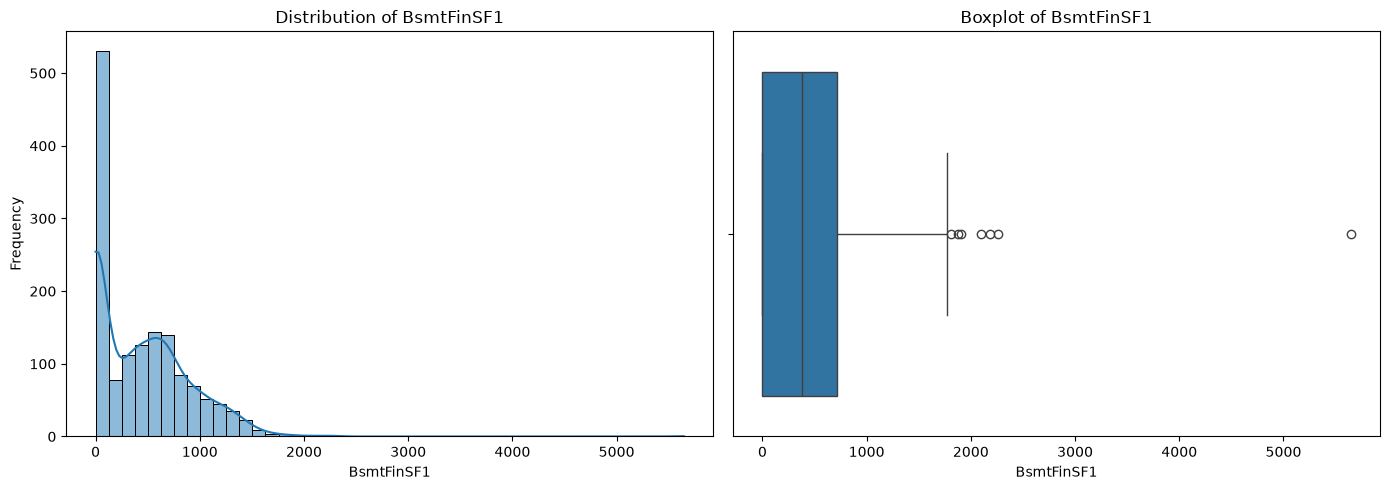

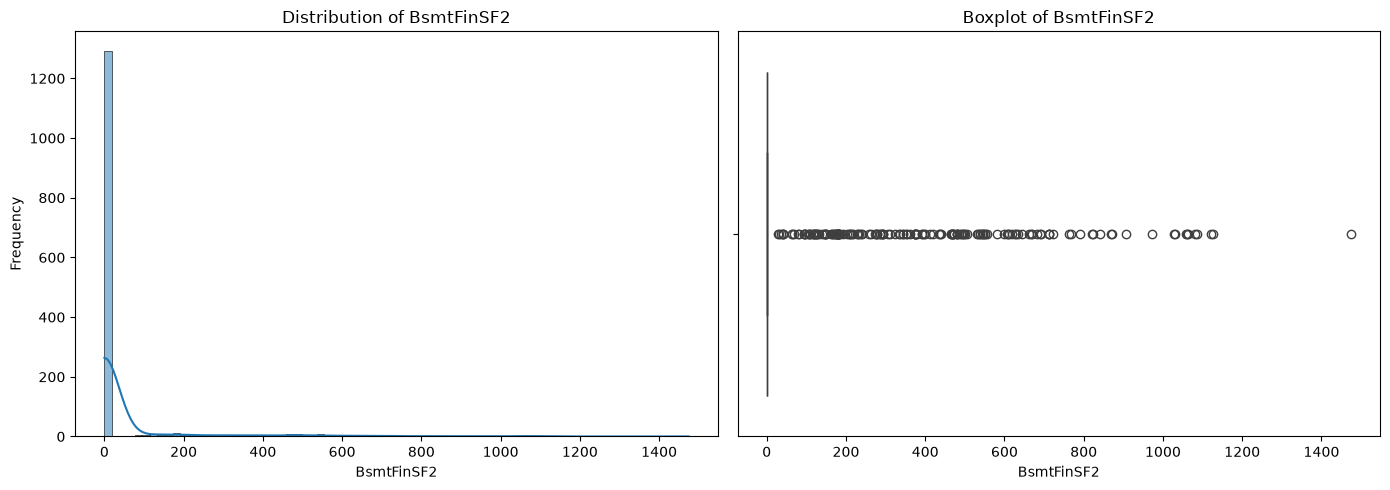

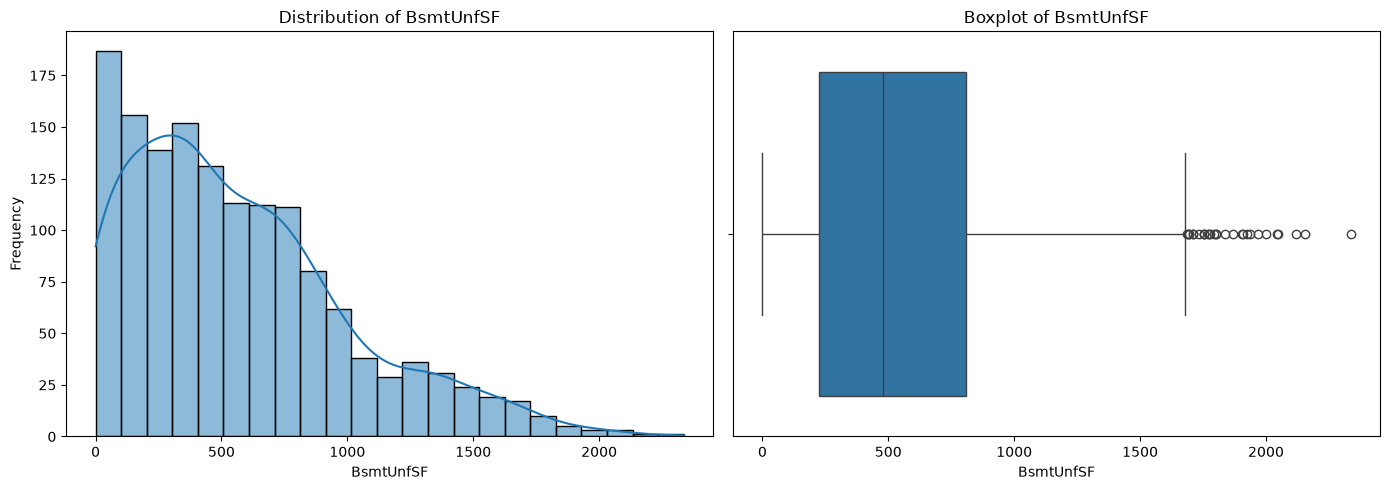

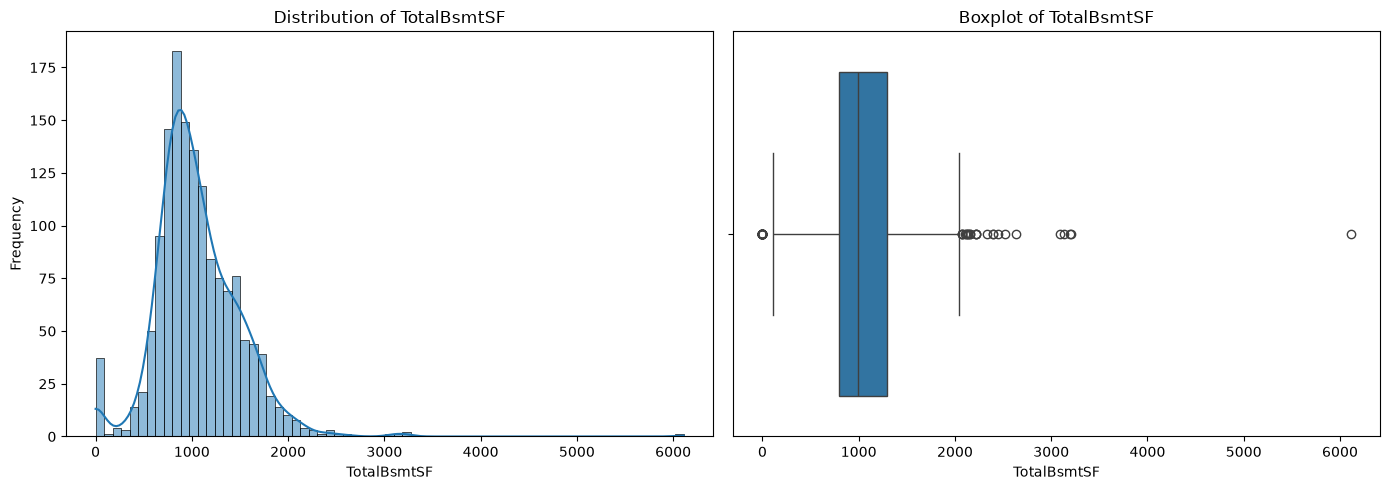

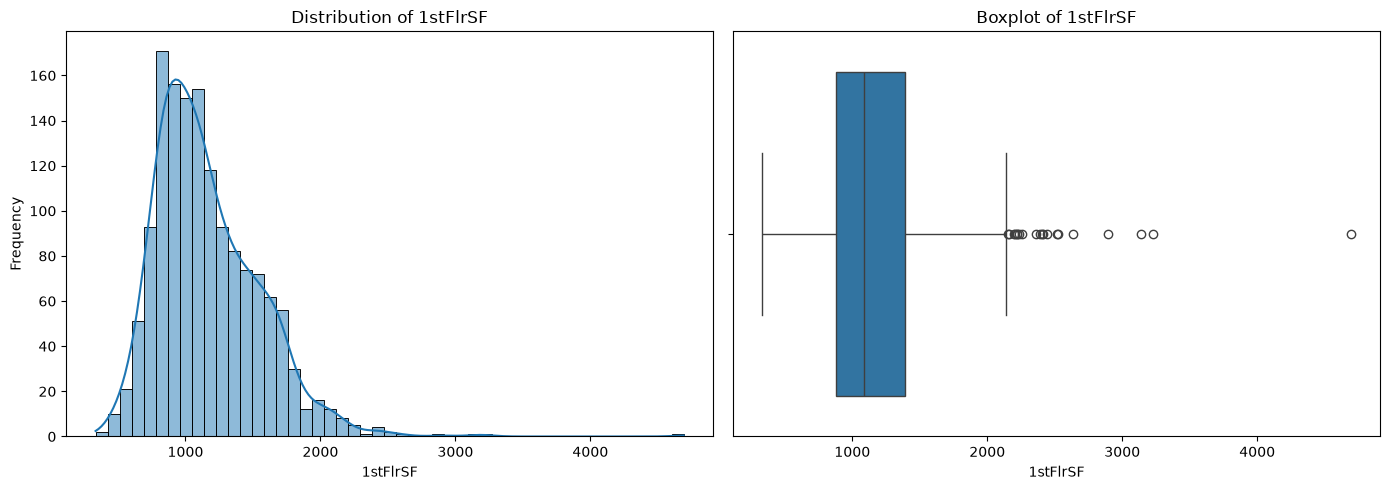

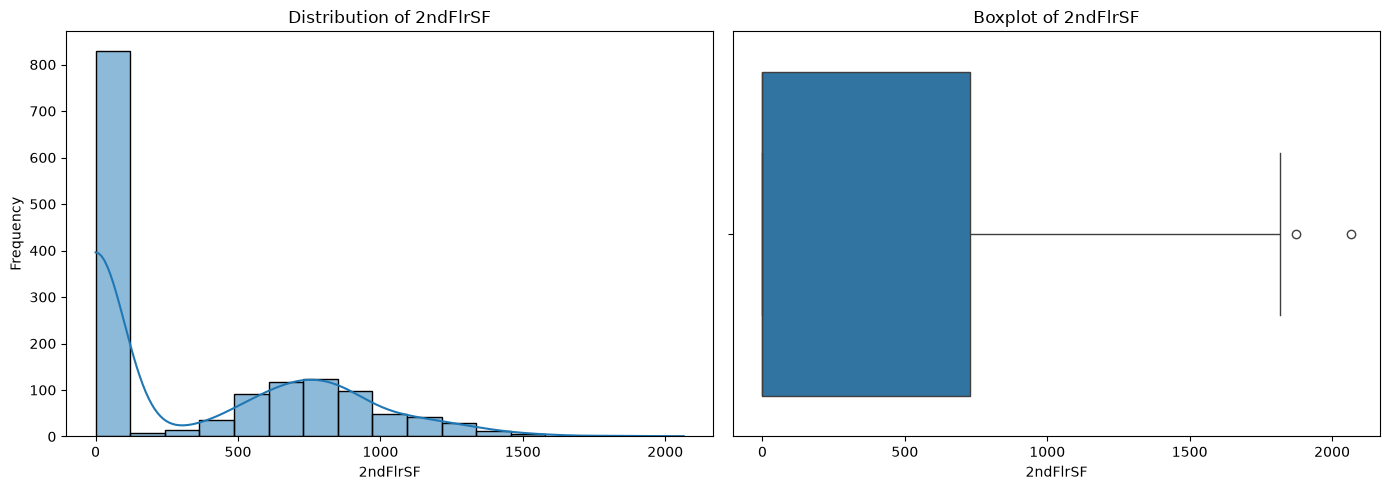

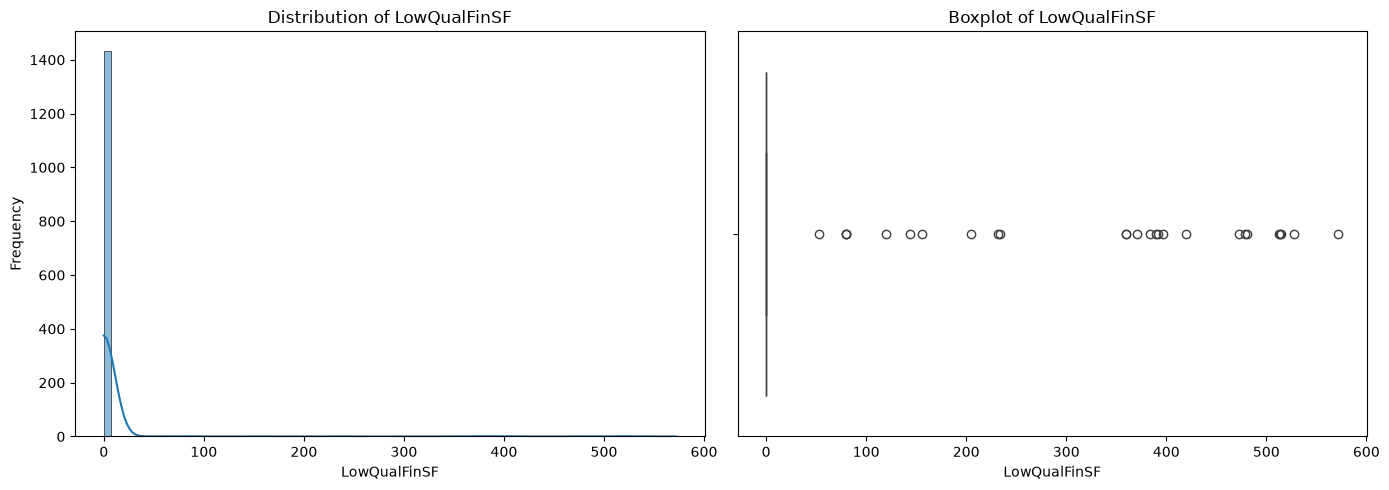

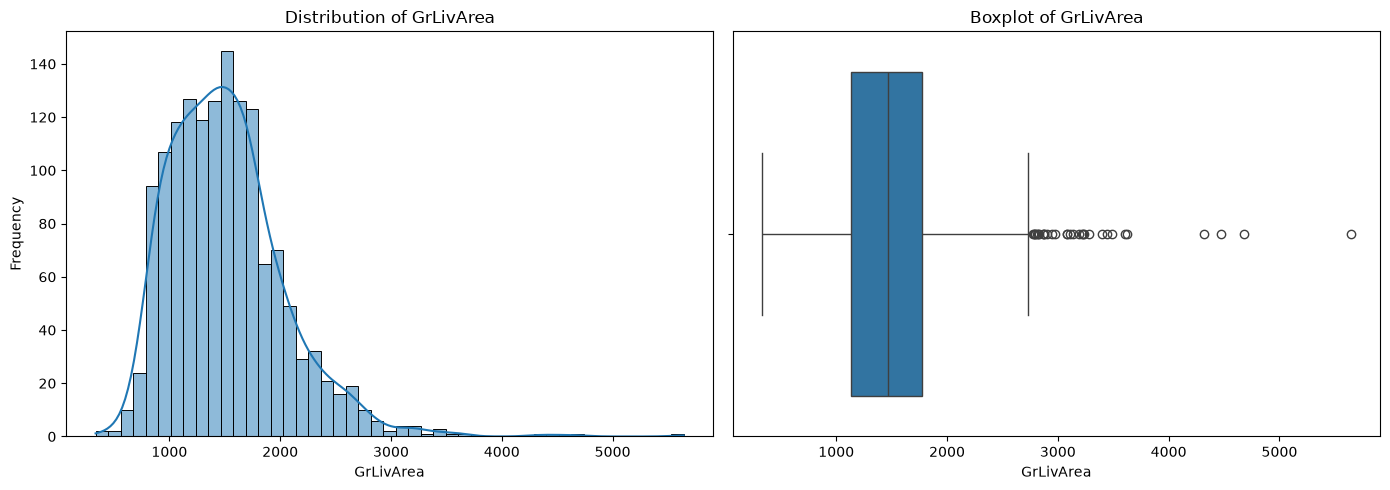

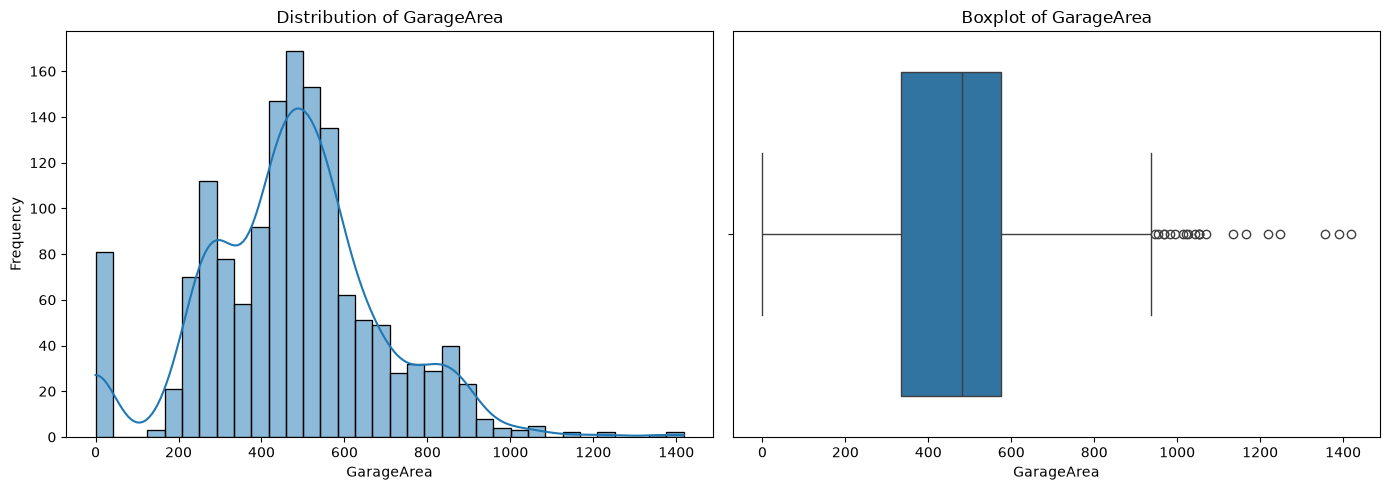

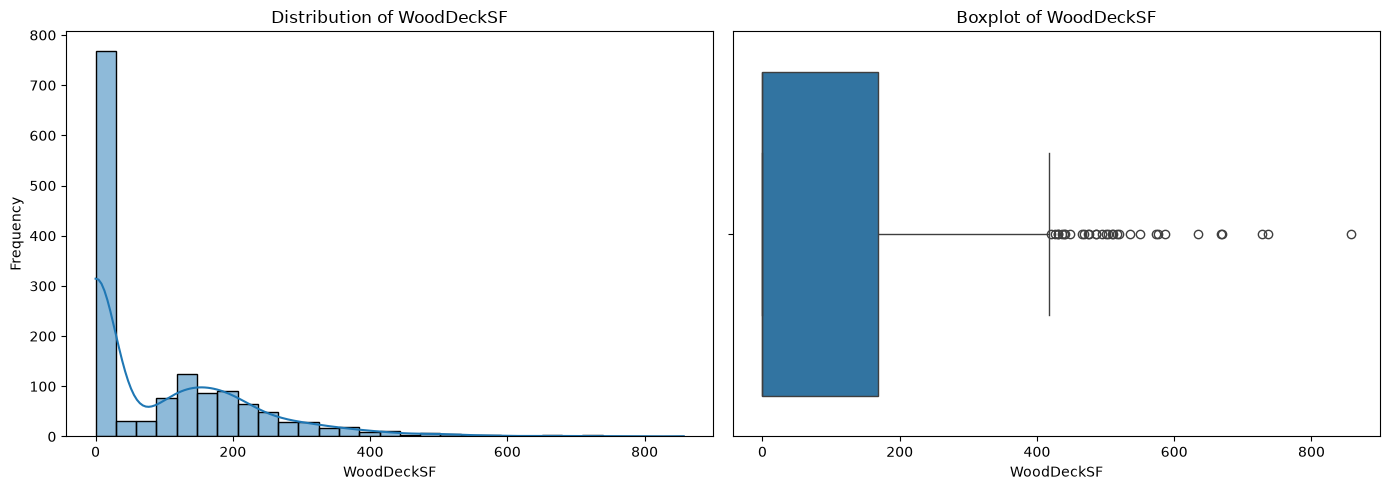

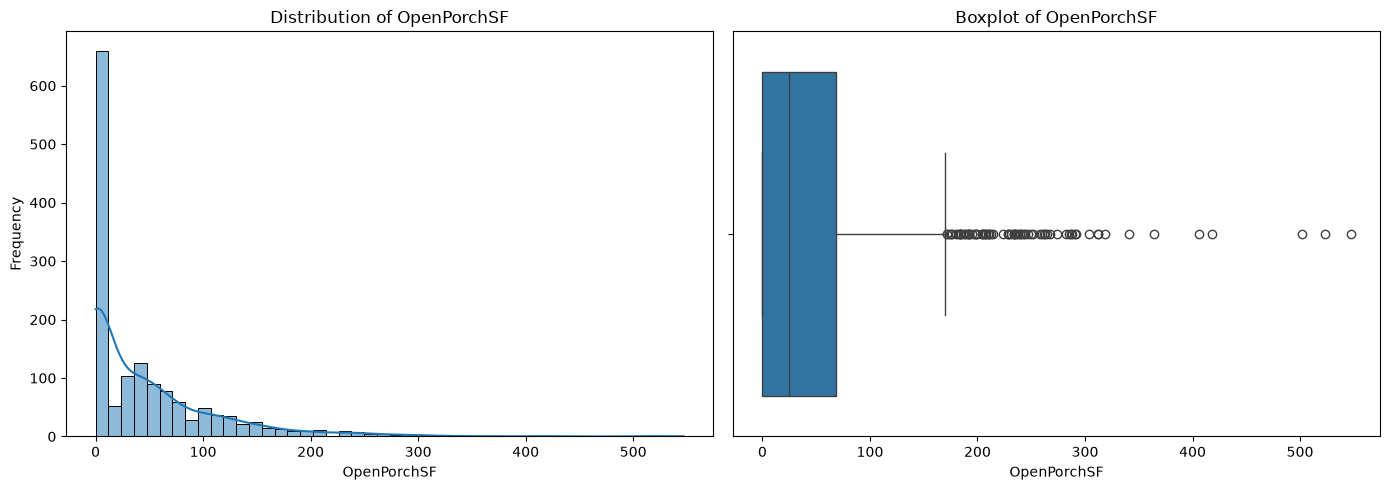

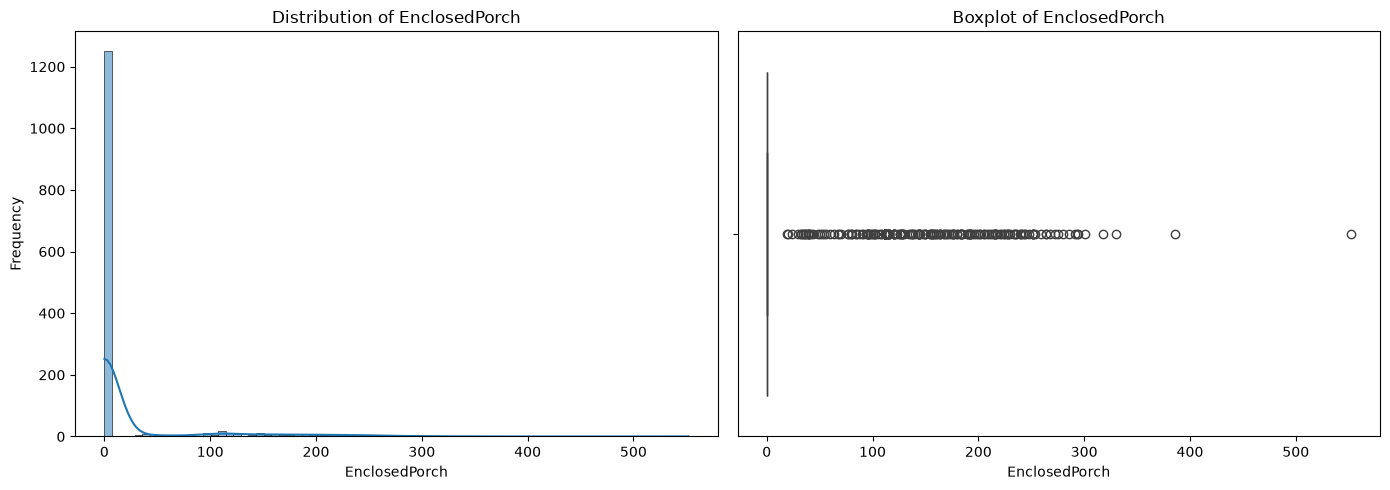

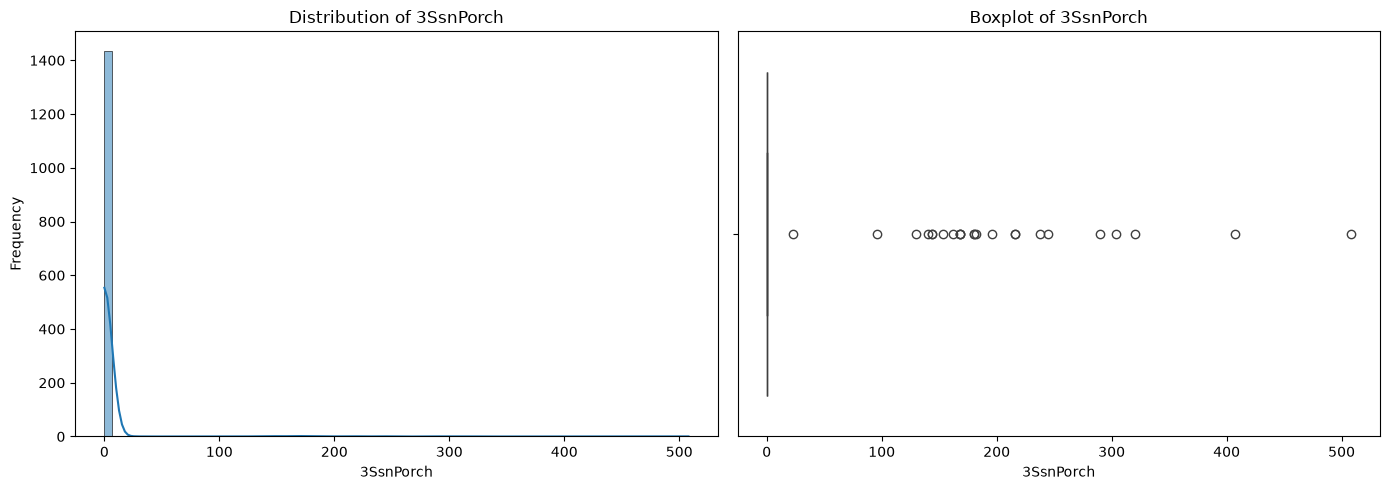

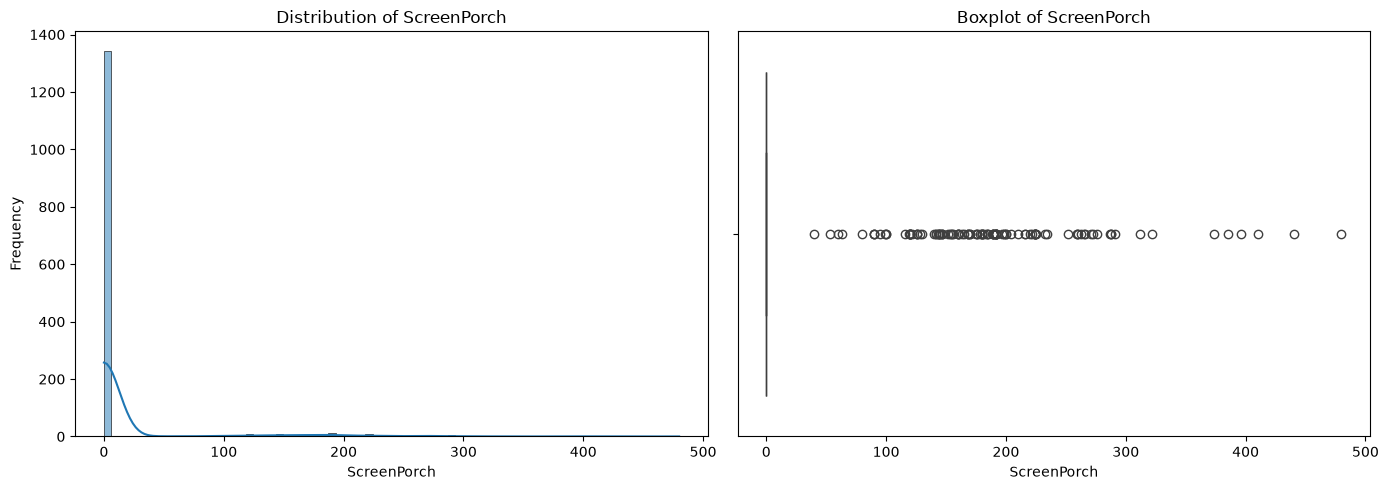

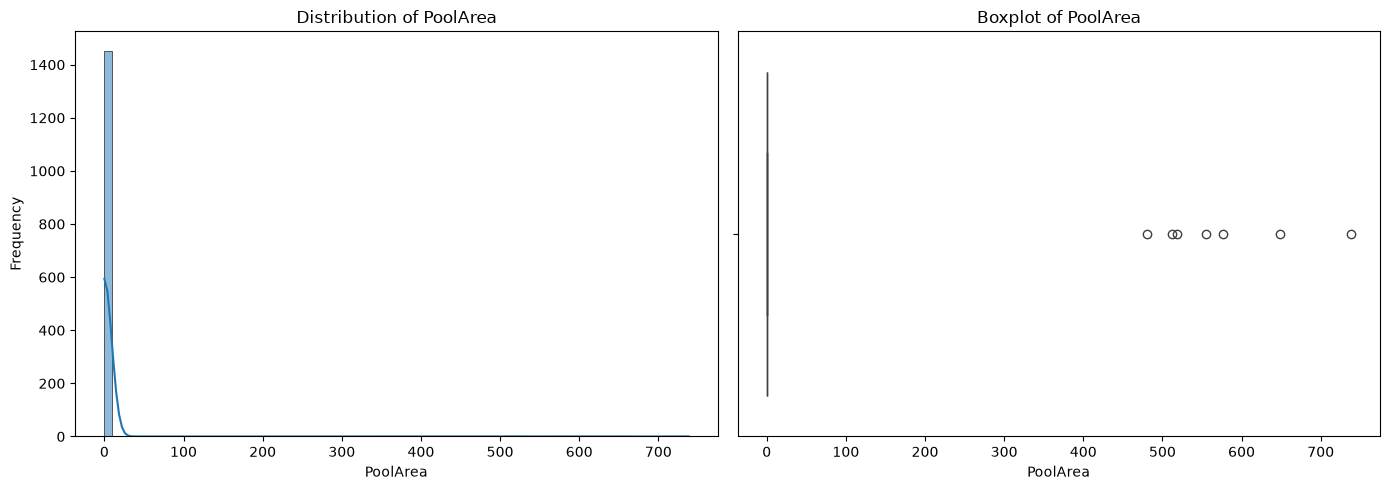

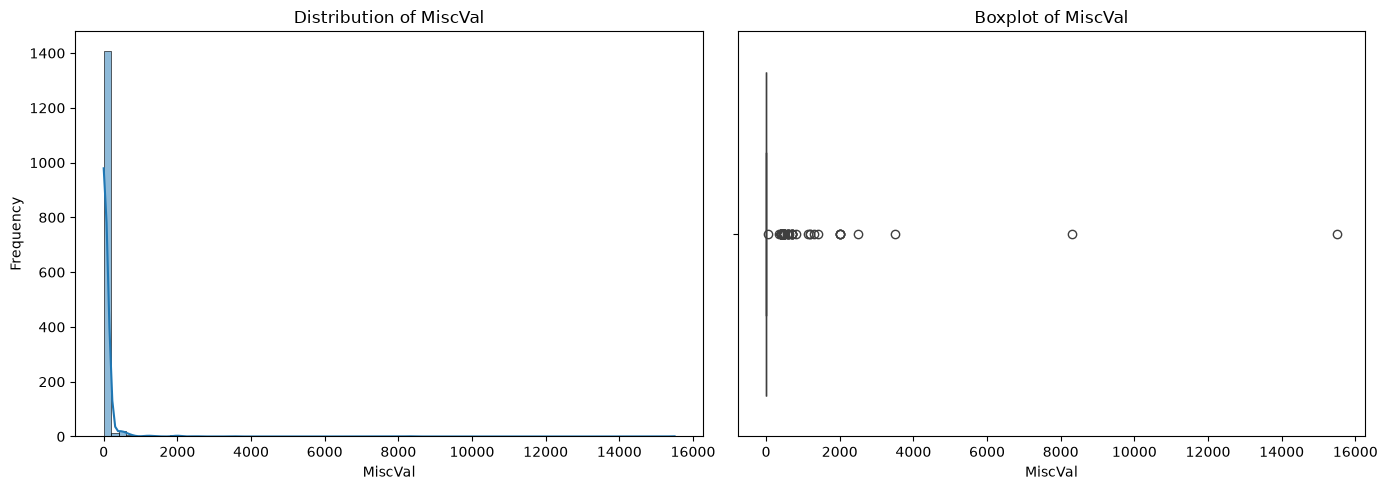

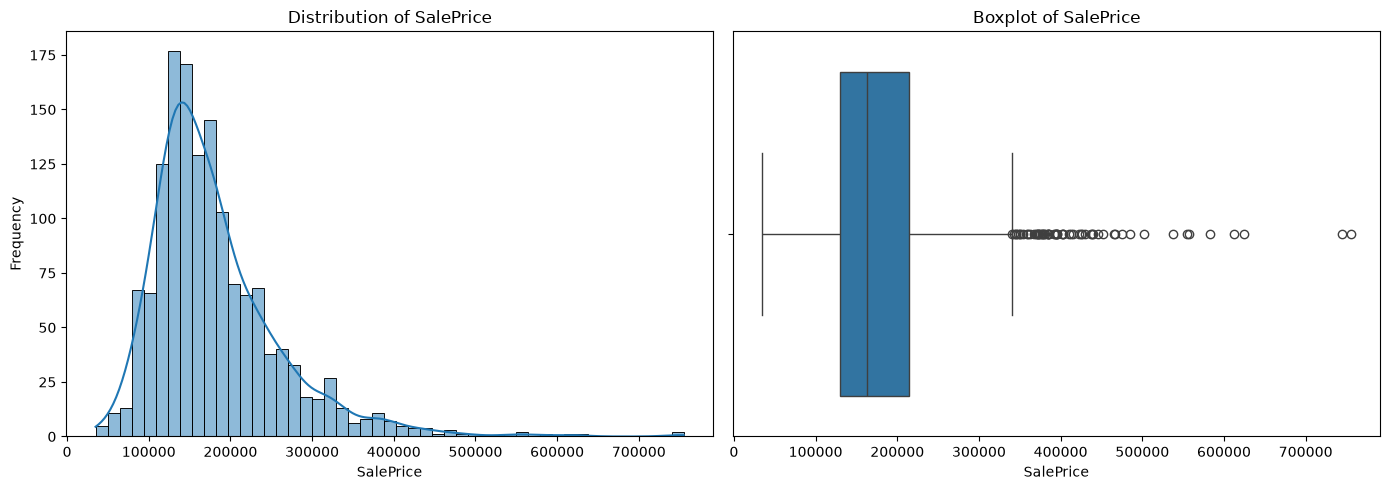

In [13]:
for col in continuous_vars:

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Histogram
    sns.histplot(
        data=train,
        x=col,
        kde=True,
        ax=axes[0]
    )

    axes[0].set_title(f"Distribution of {col}")
    axes[0].set_xlabel(col)
    axes[0].set_ylabel("Frequency")

    # Boxplot
    sns.boxplot(
        data=train,
        x=col,
        ax=axes[1]
    )

    axes[1].set_title(f"Boxplot of {col}")
    axes[1].set_xlabel(col)
    plt.tight_layout()
    plt.show()

In [14]:
train[continuous_vars].describe().T

,count,mean,std,min,25%,50%,75%,max
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0
BsmtFinSF2,1460.0,46.549315,161.319273,0.0,0.00,0.0,0.00,1474.0
BsmtUnfSF,1460.0,567.240411,441.866955,0.0,223.00,477.5,808.00,2336.0
TotalBsmtSF,1460.0,1057.429452,438.705324,0.0,795.75,991.5,1298.25,6110.0
1stFlrSF,1460.0,1162.626712,386.587738,334.0,882.00,1087.0,1391.25,4692.0
2ndFlrSF,1460.0,346.992466,436.528436,0.0,0.00,0.0,728.00,2065.0
LowQualFinSF,1460.0,5.844521,48.623081,0.0,0.00,0.0,0.00,572.0


## Discrete Variable

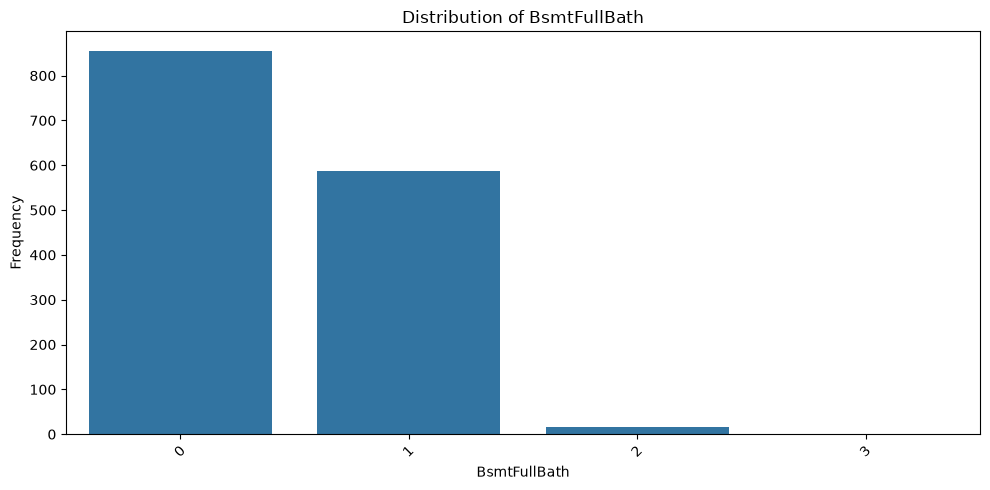

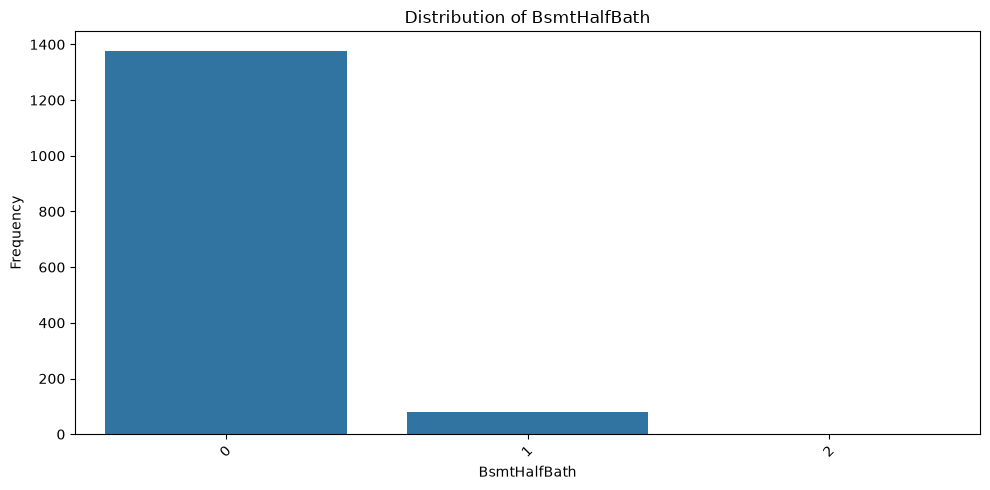

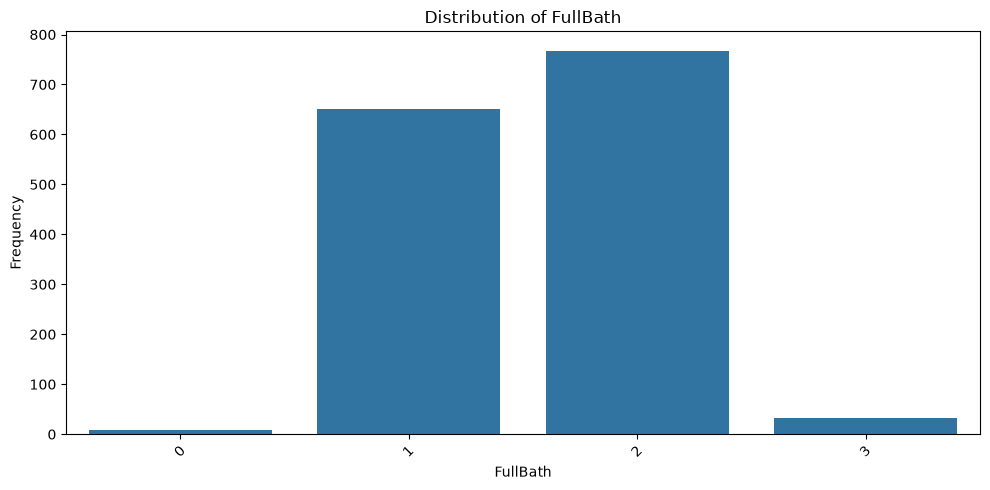

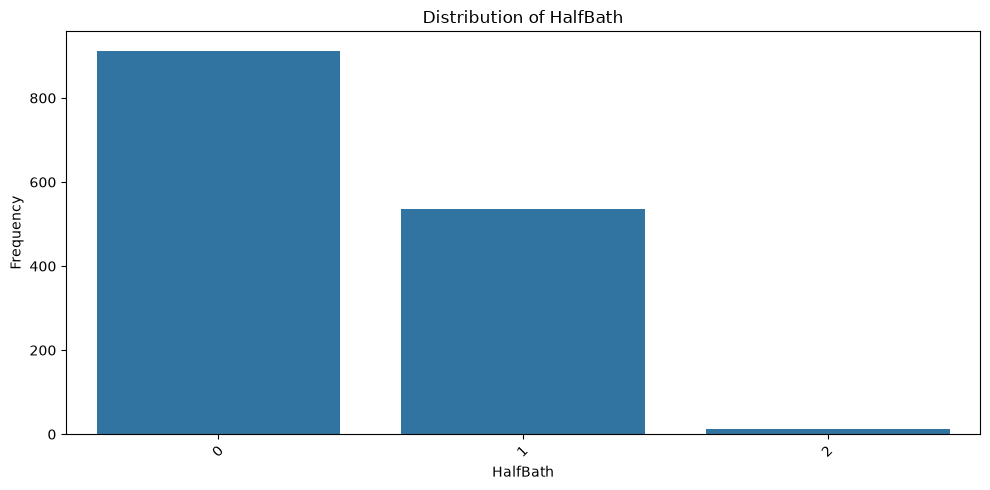

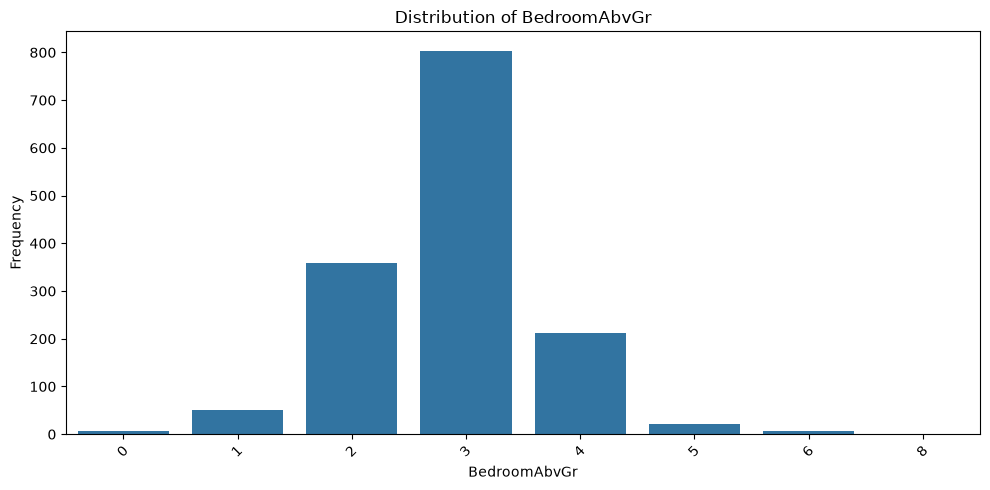

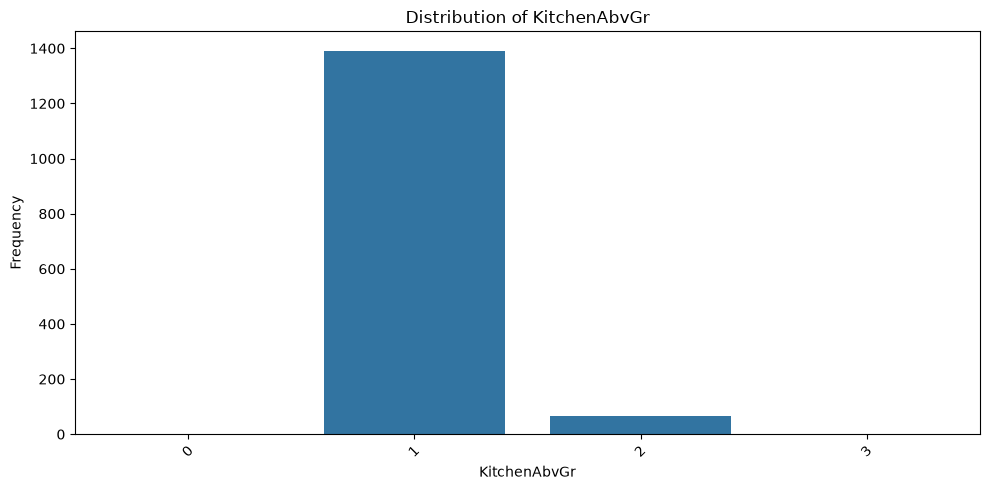

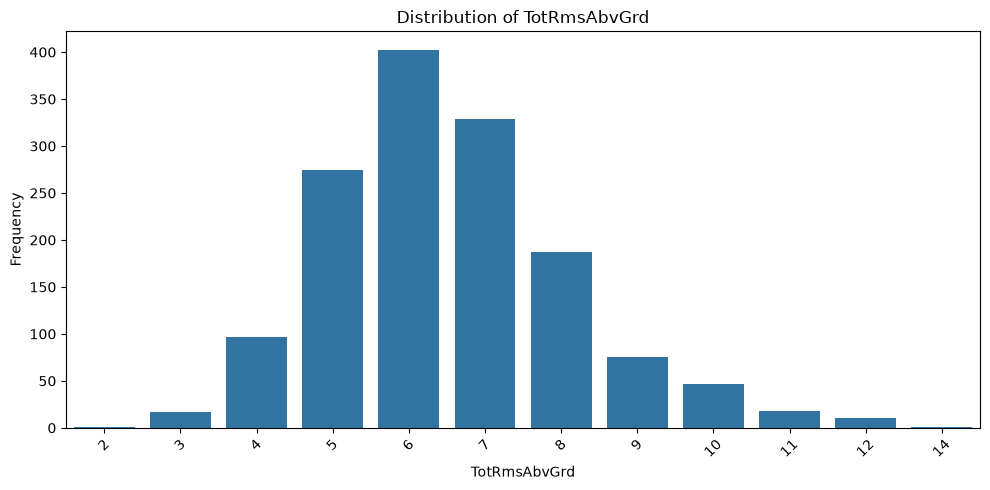

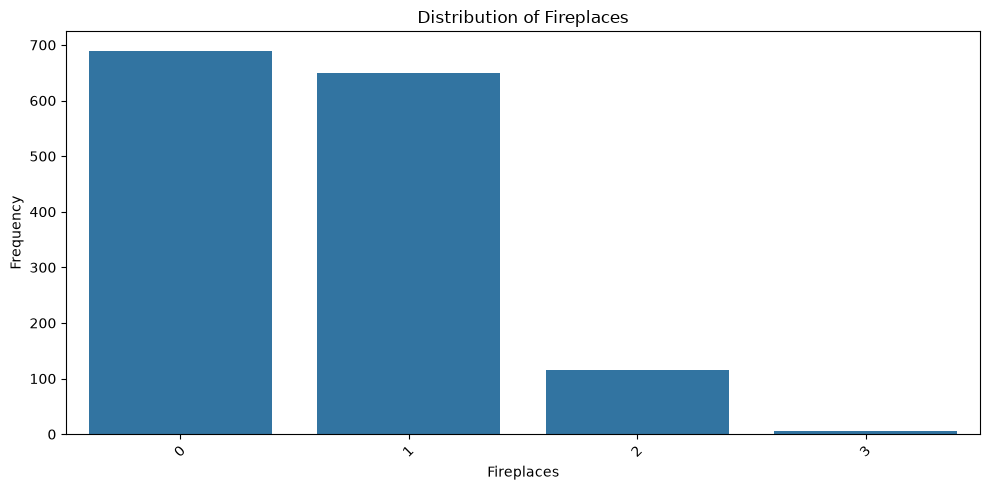

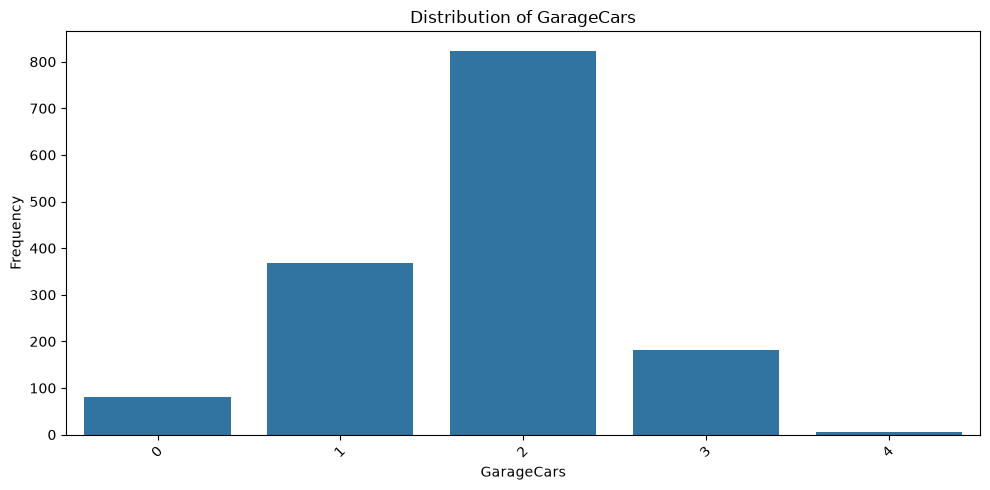

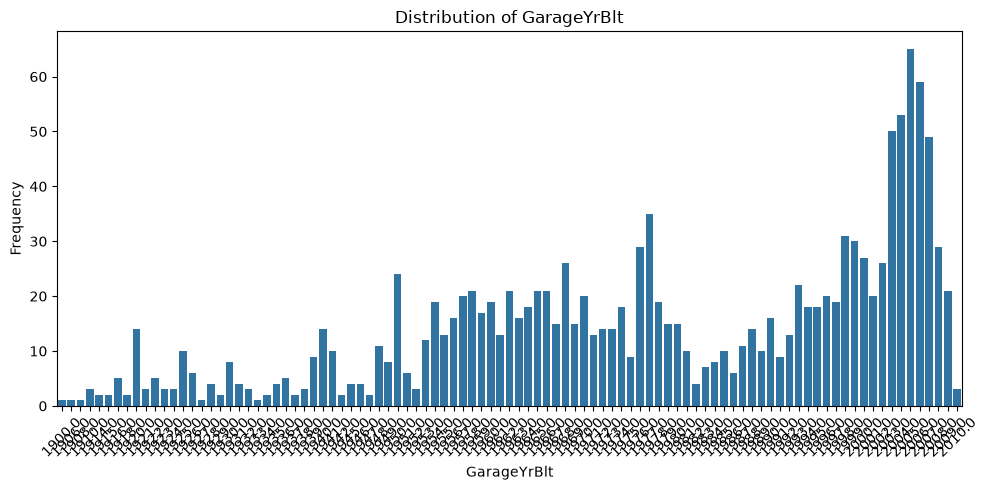

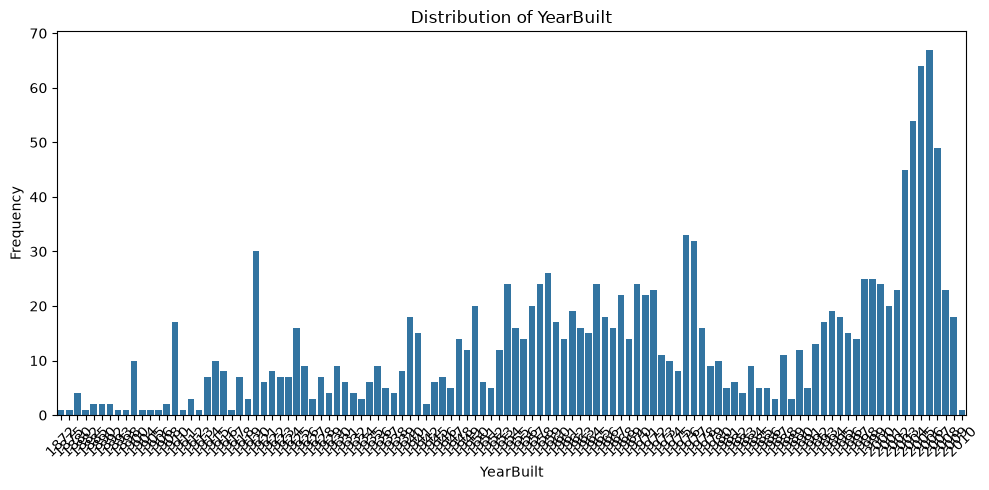

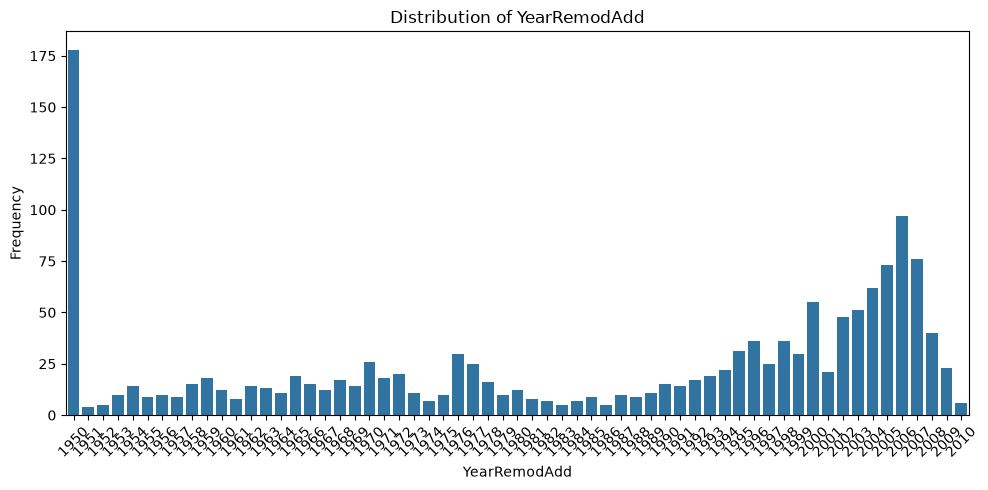

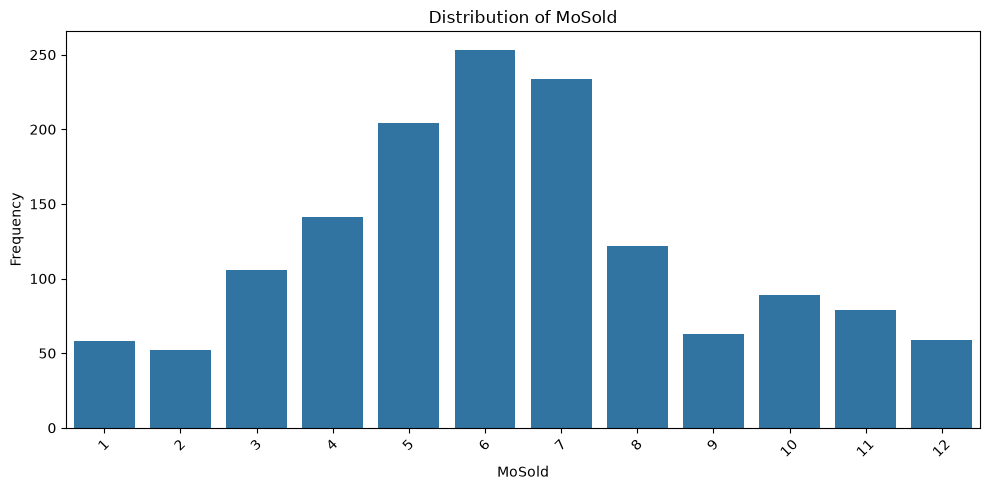

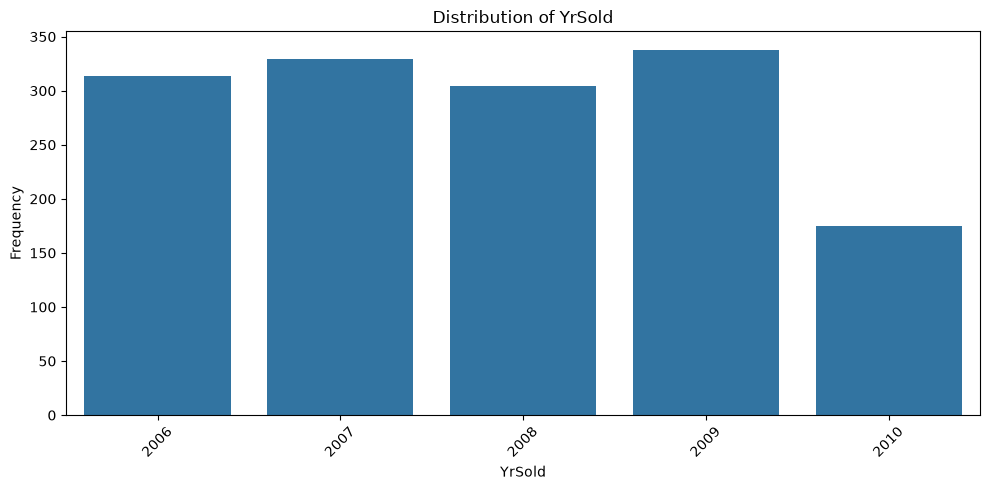

In [15]:
for col in discrete_vars:

    plt.figure(figsize=(10, 5))

    sns.countplot(
        data=train,
        x=col
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

## Ordinal Variable

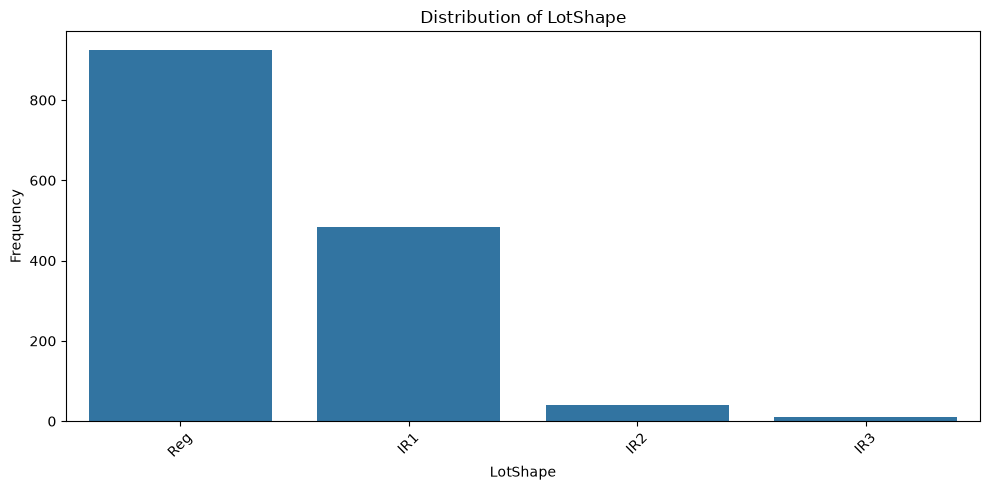

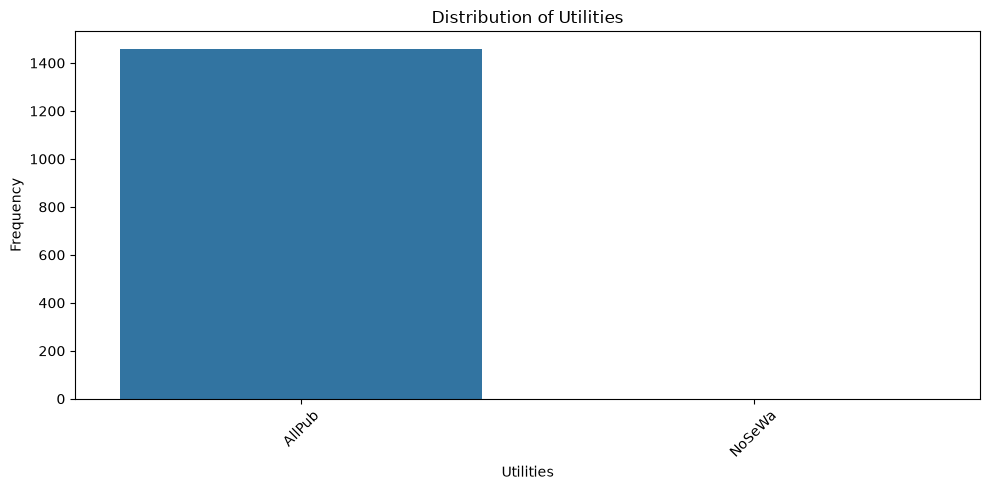

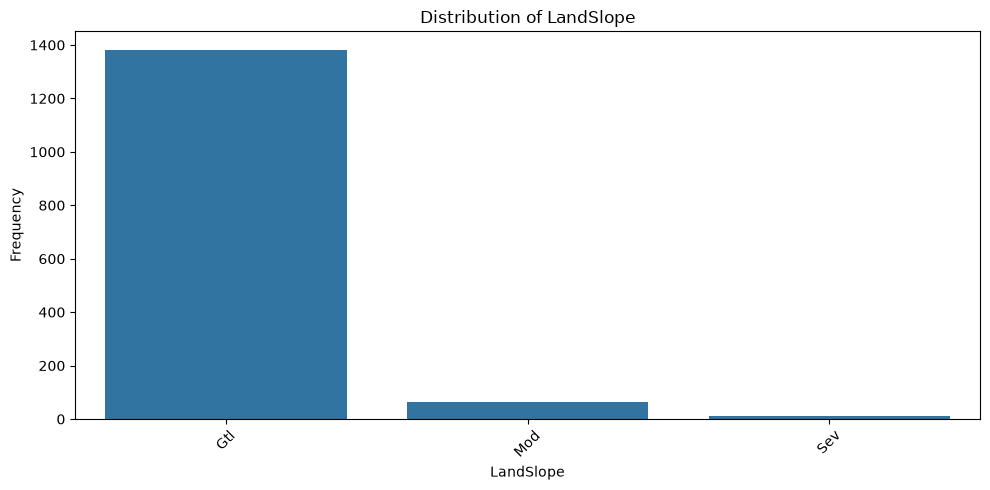

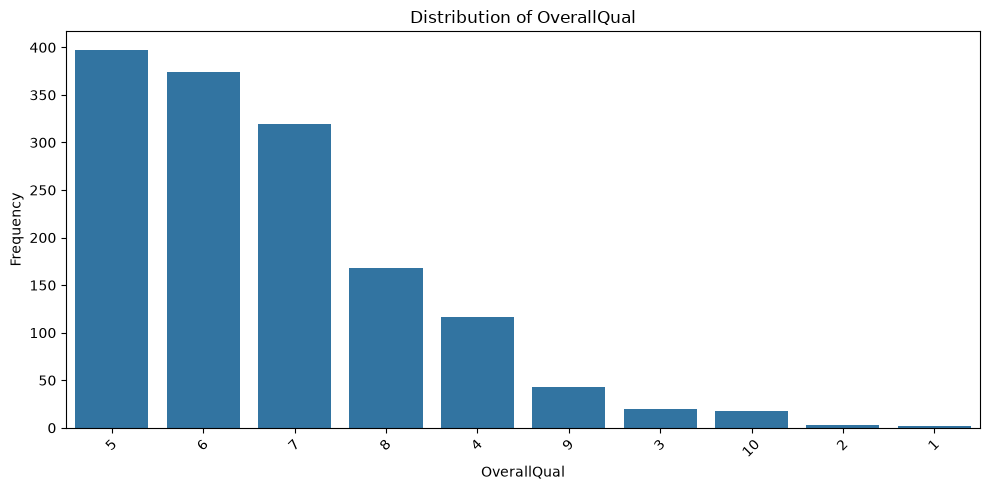

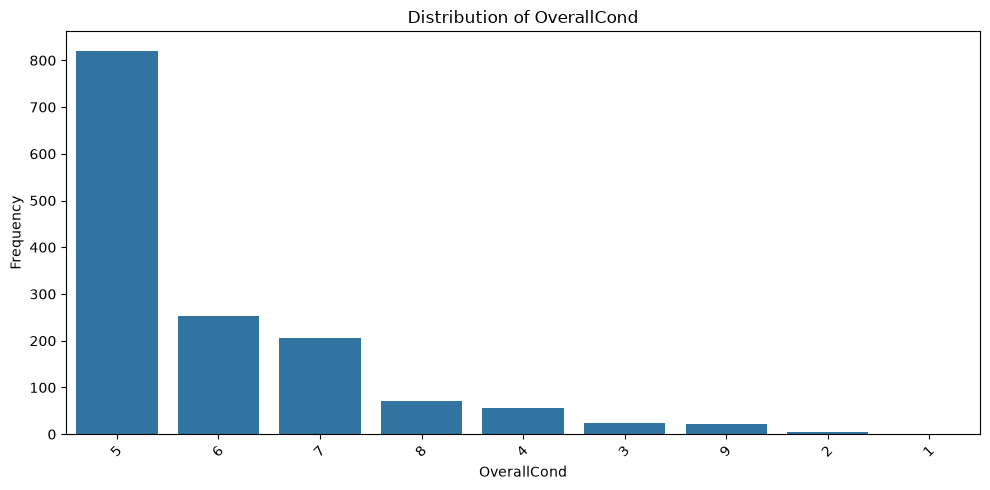

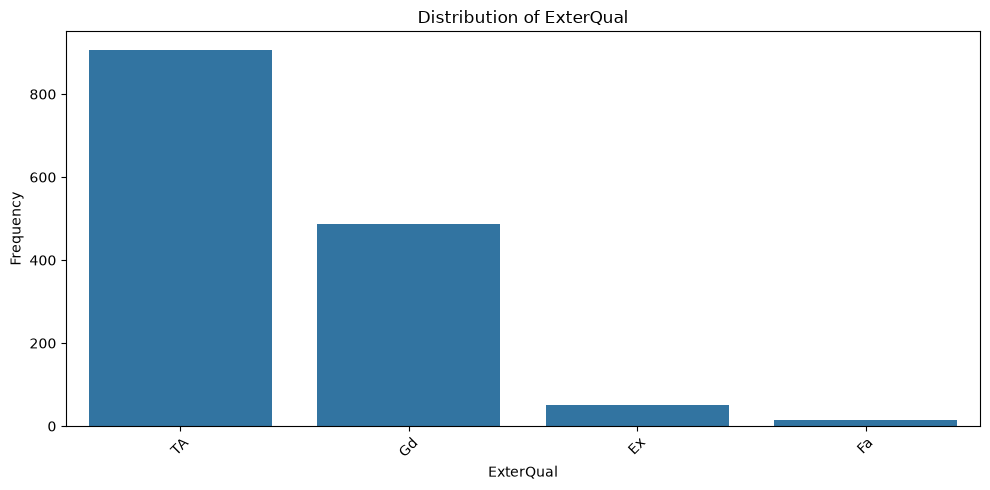

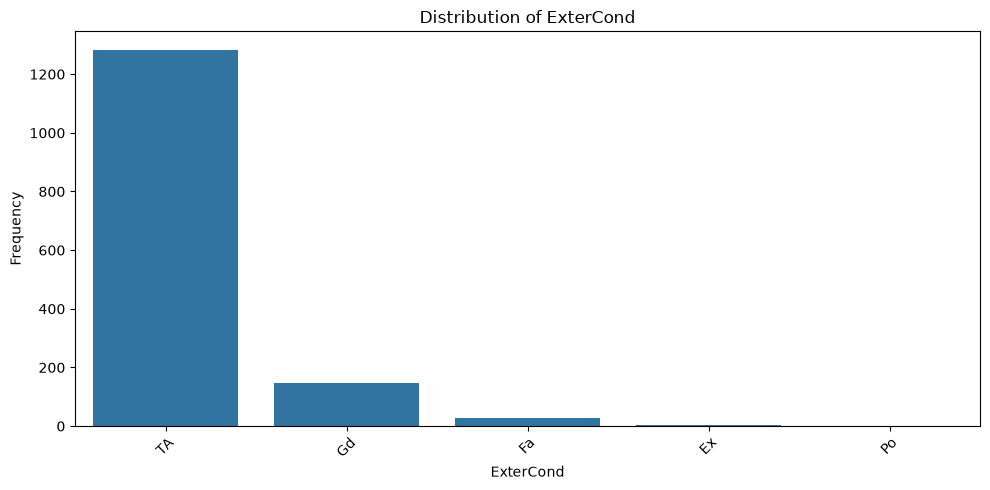

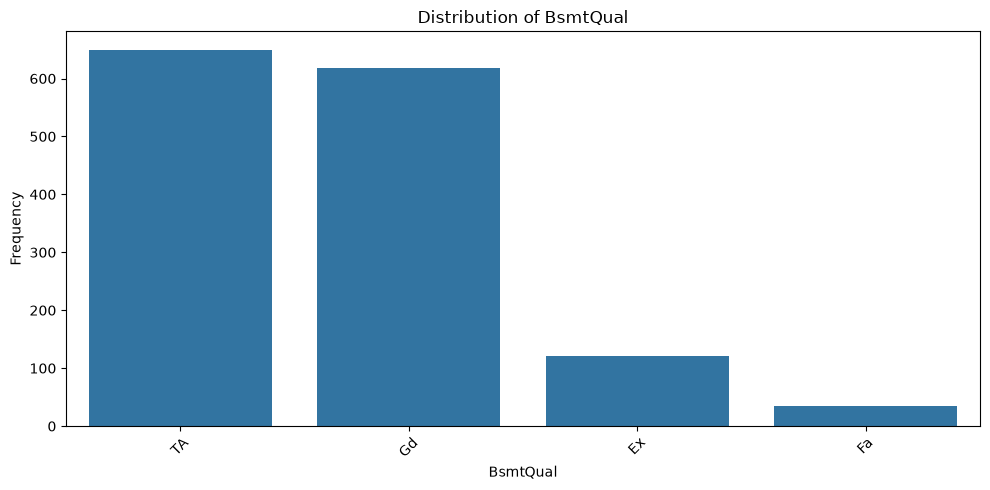

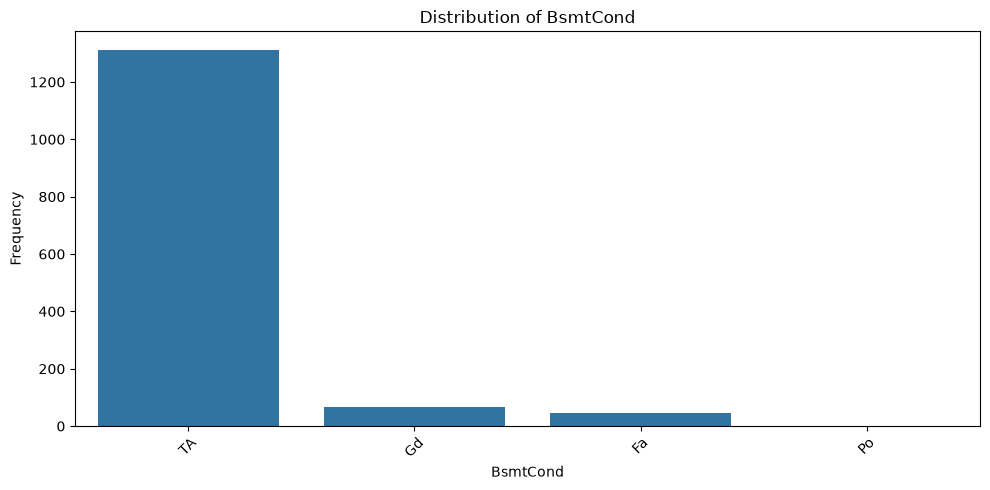

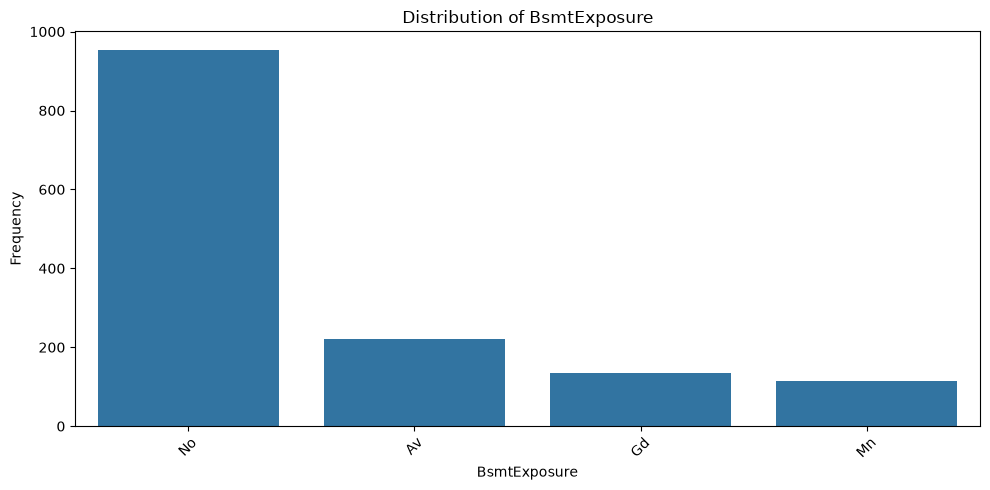

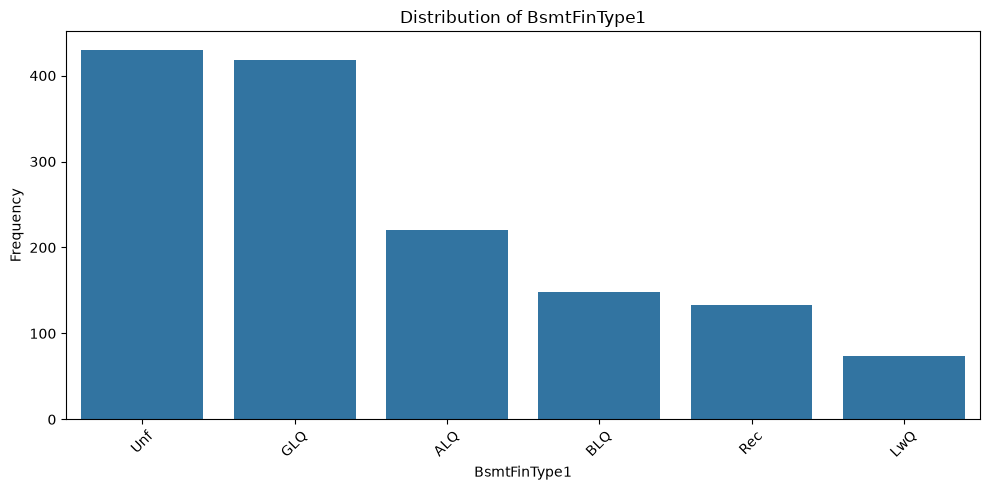

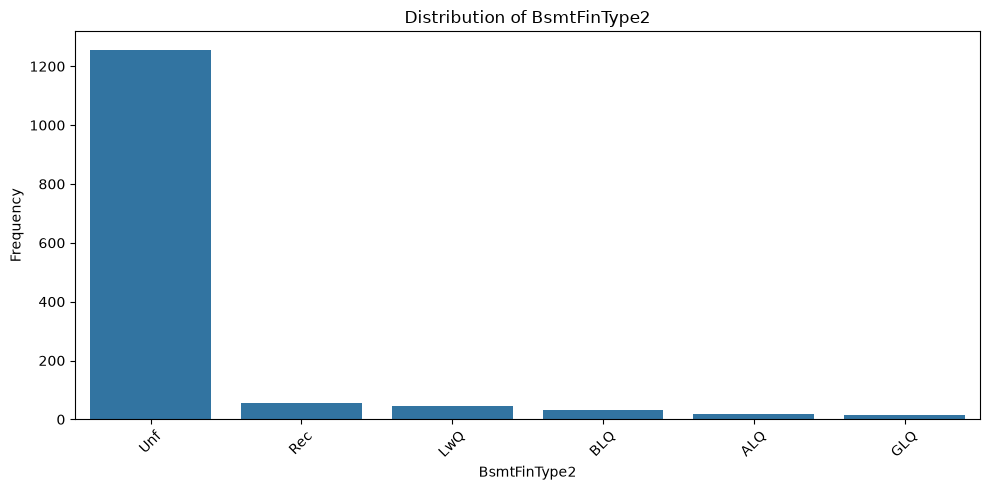

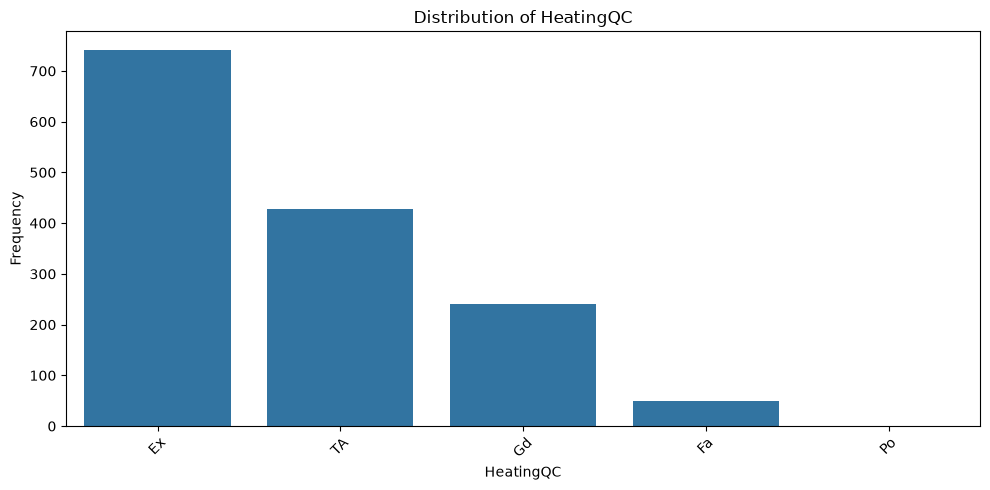

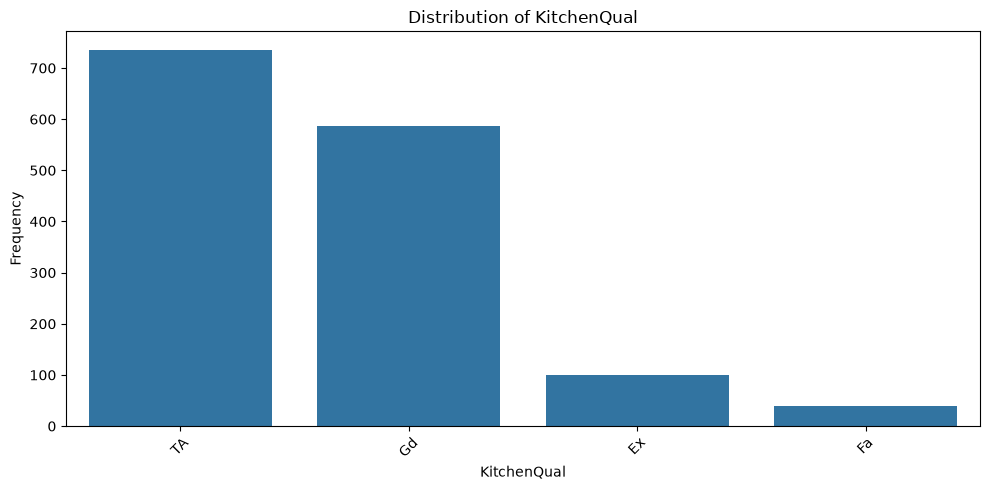

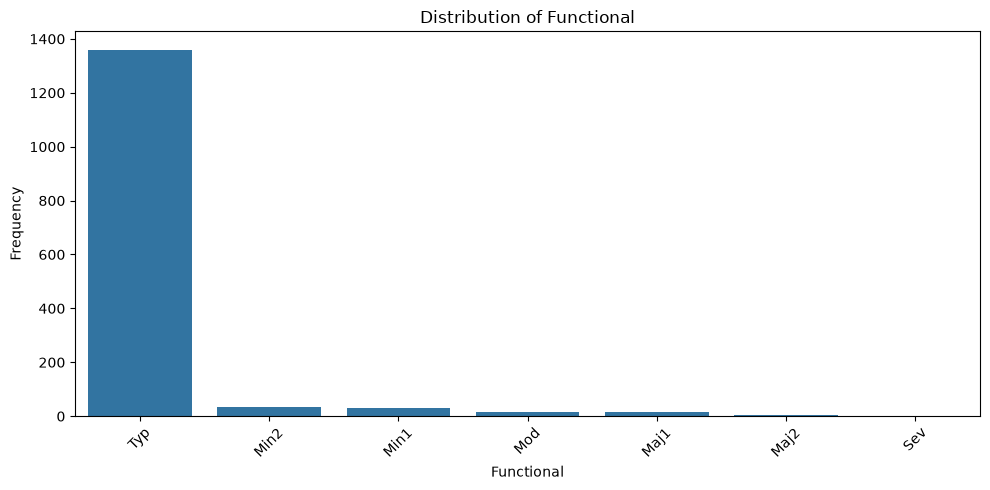

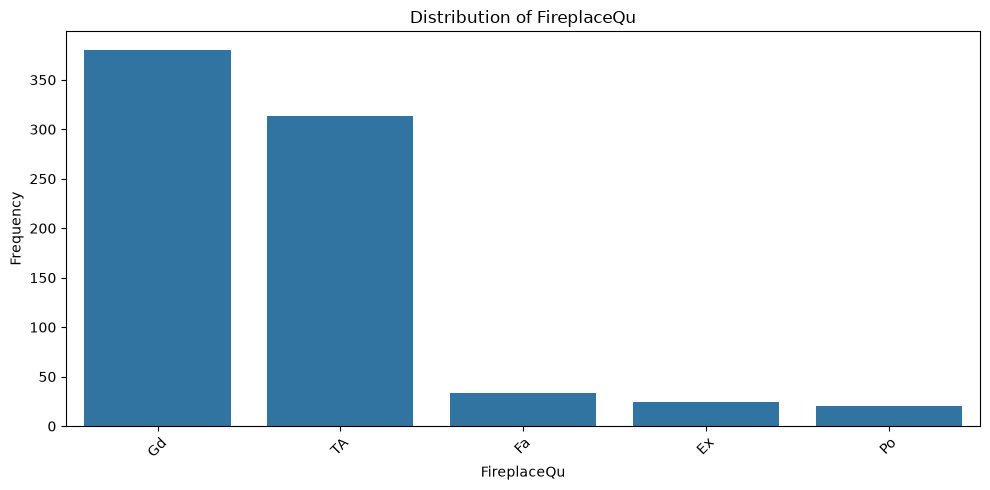

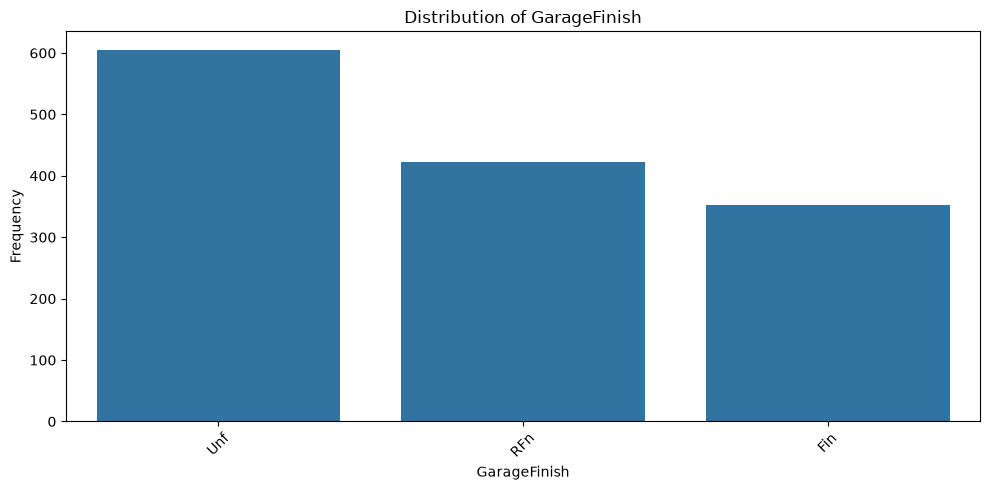

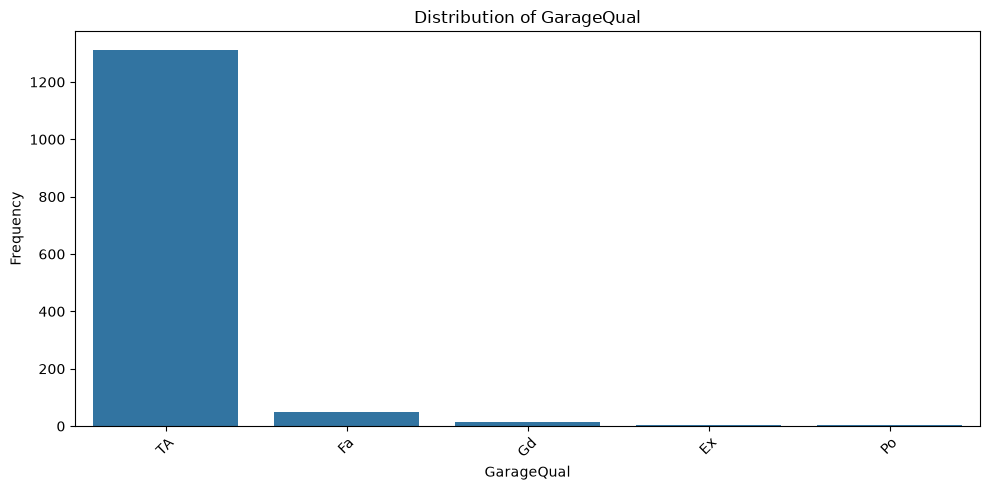

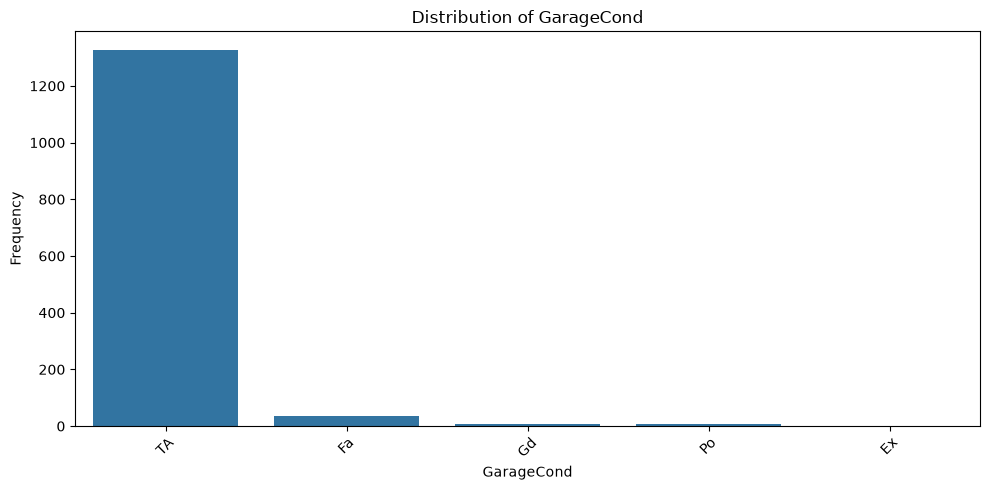

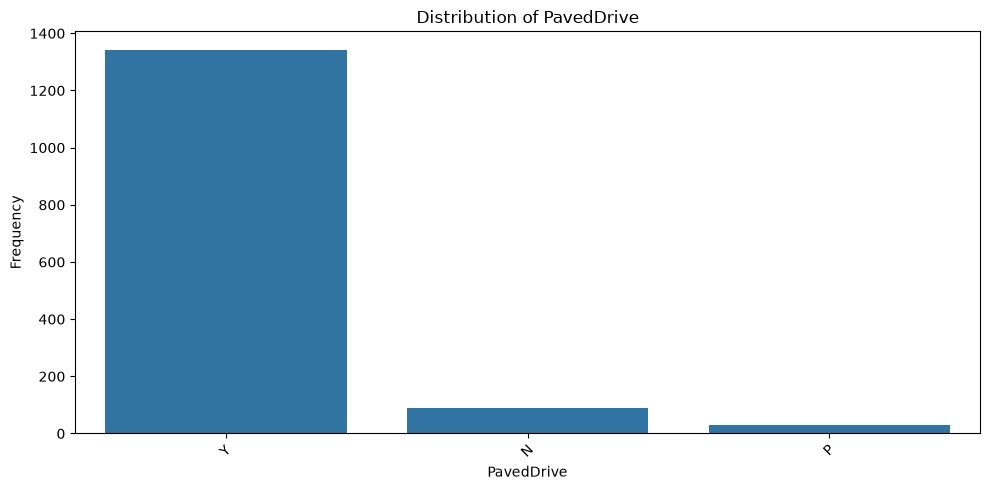

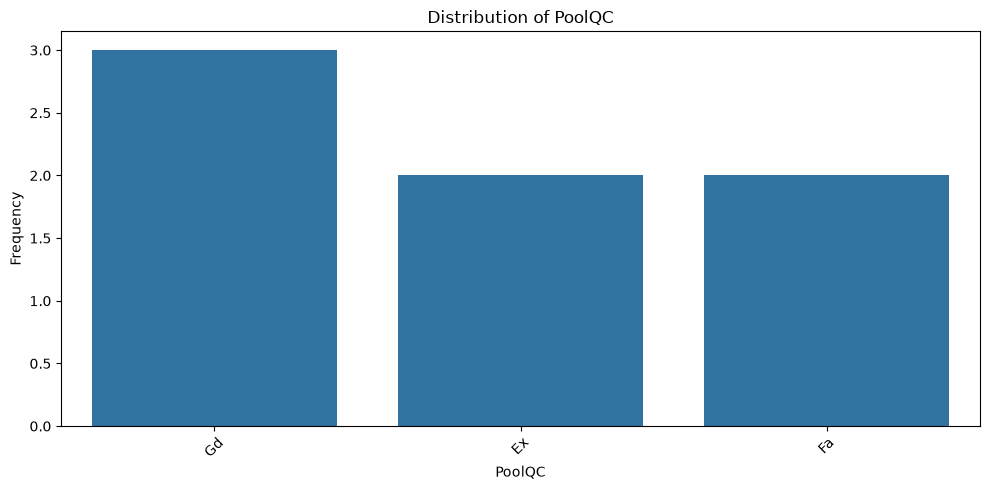

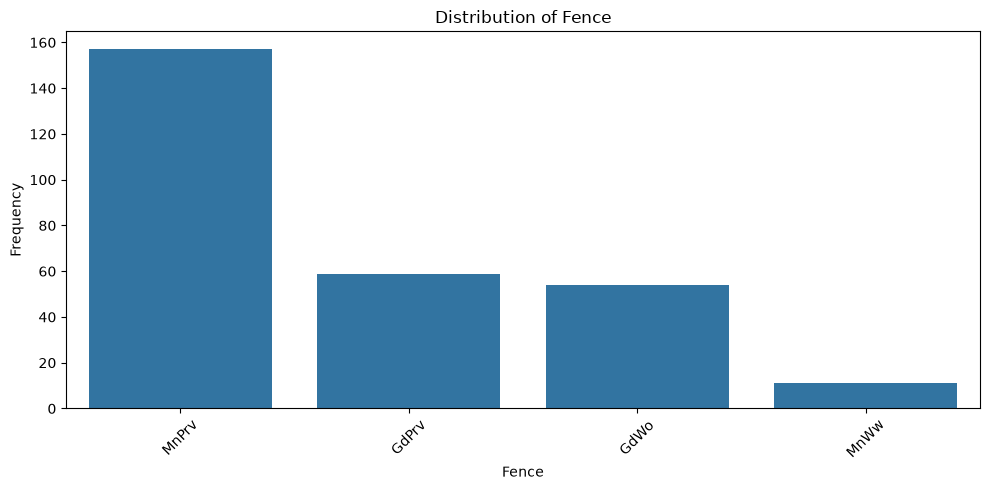

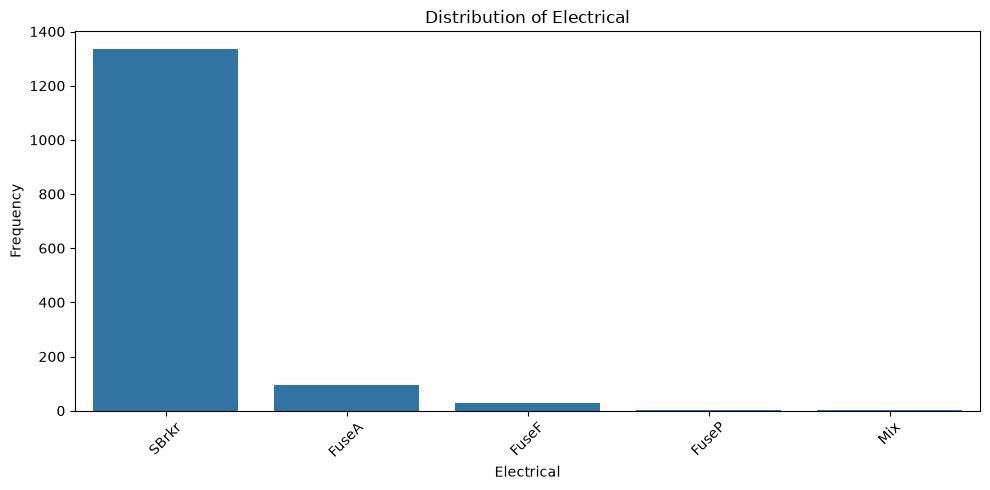

In [16]:
for col in ordinal_vars:

    plt.figure(figsize=(10, 5))

    order = train[col].value_counts().index

    sns.countplot(
        data=train,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

## Norminal Variable

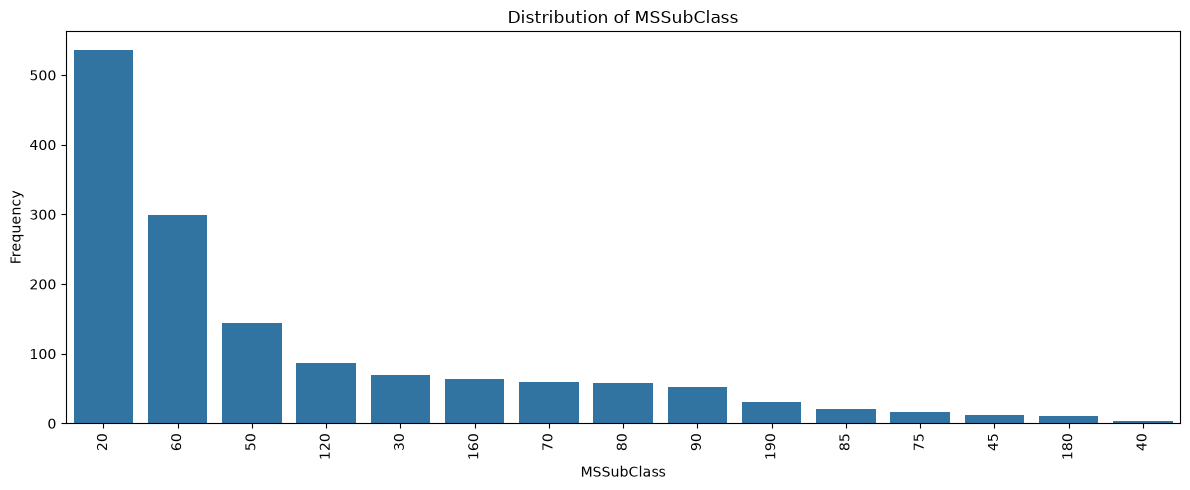

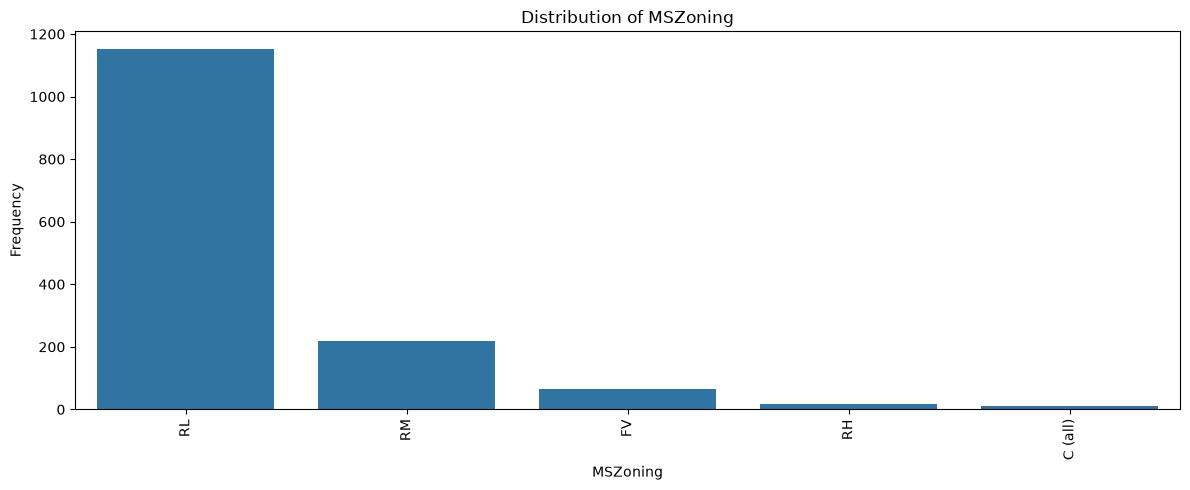

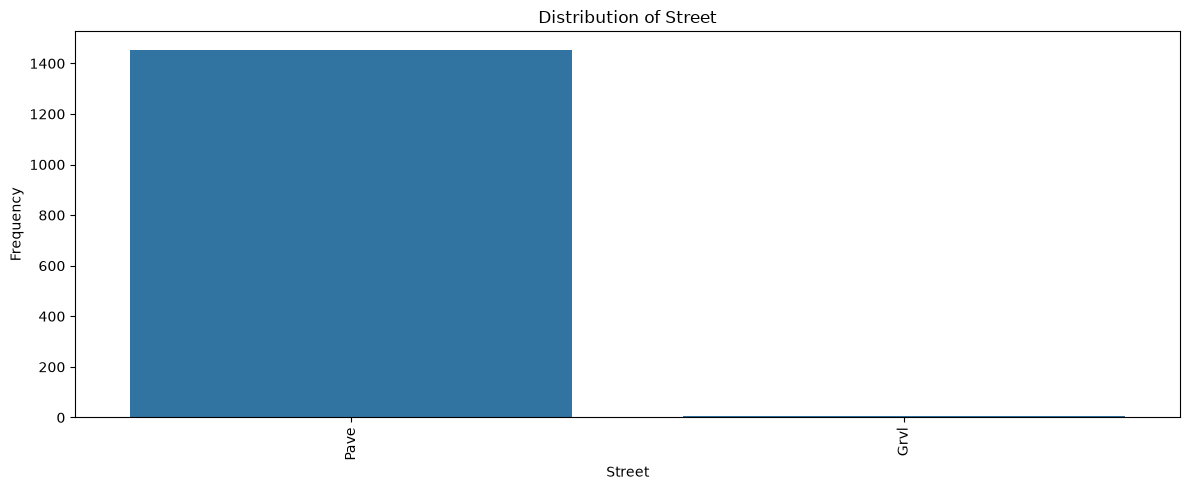

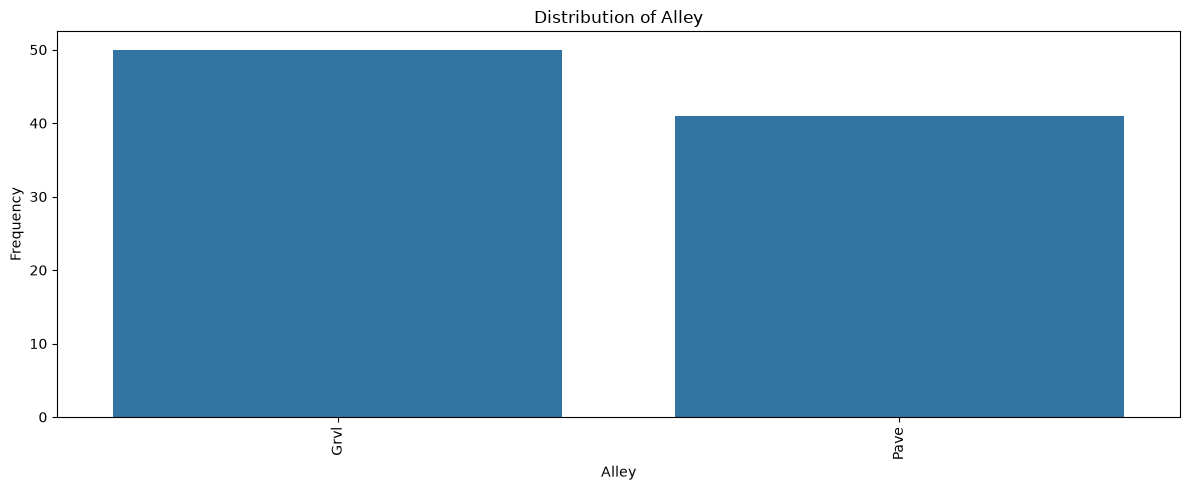

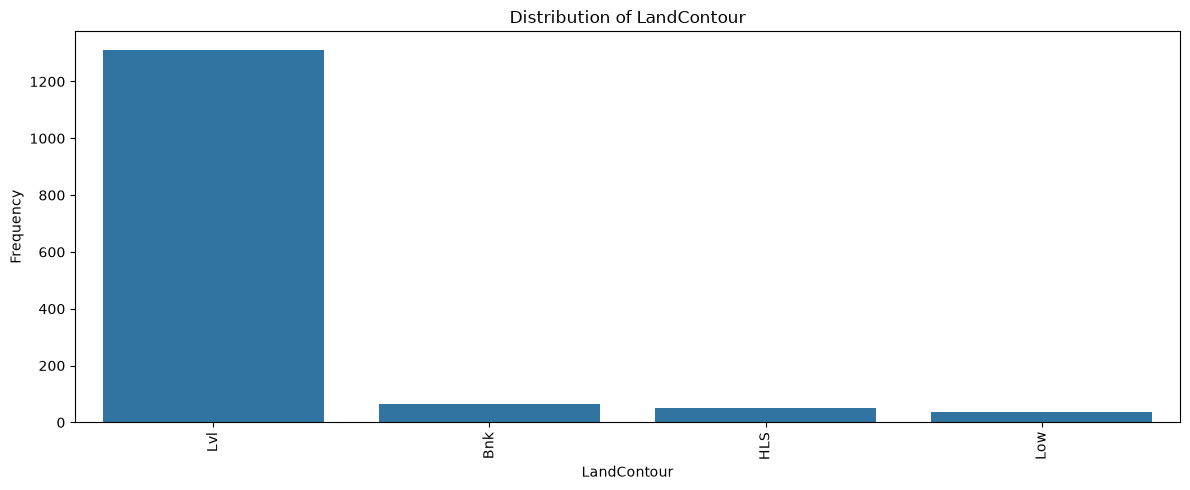

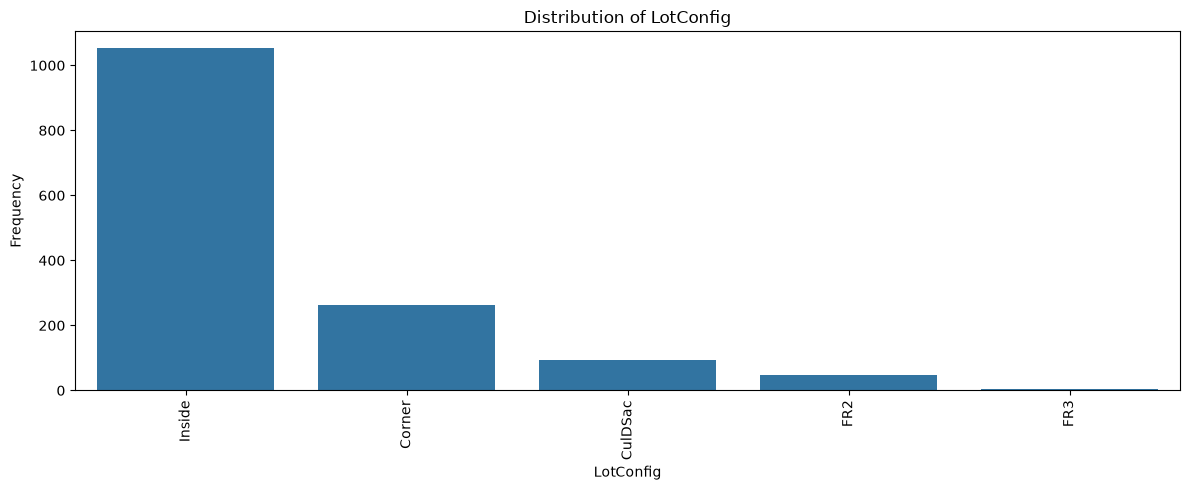

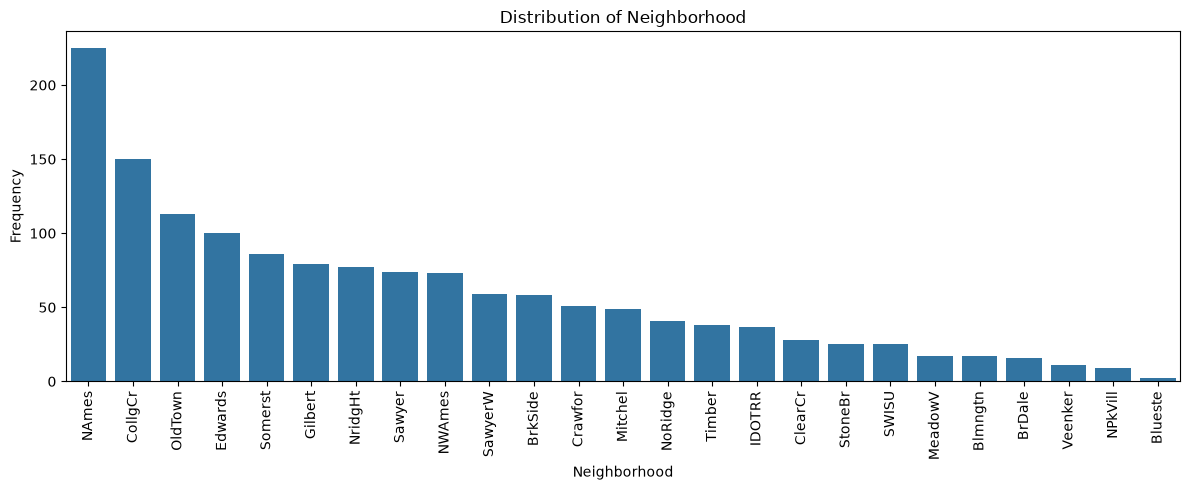

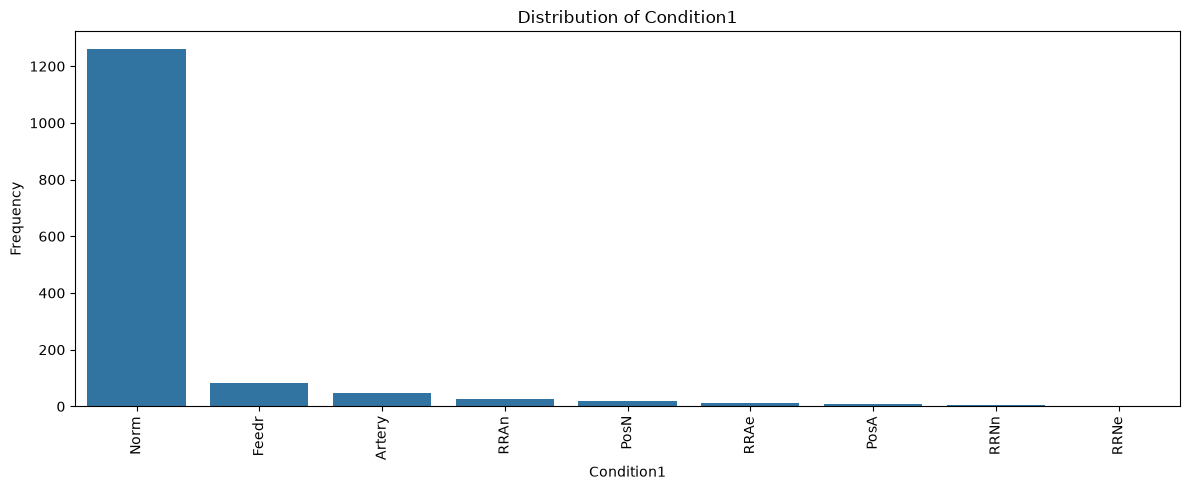

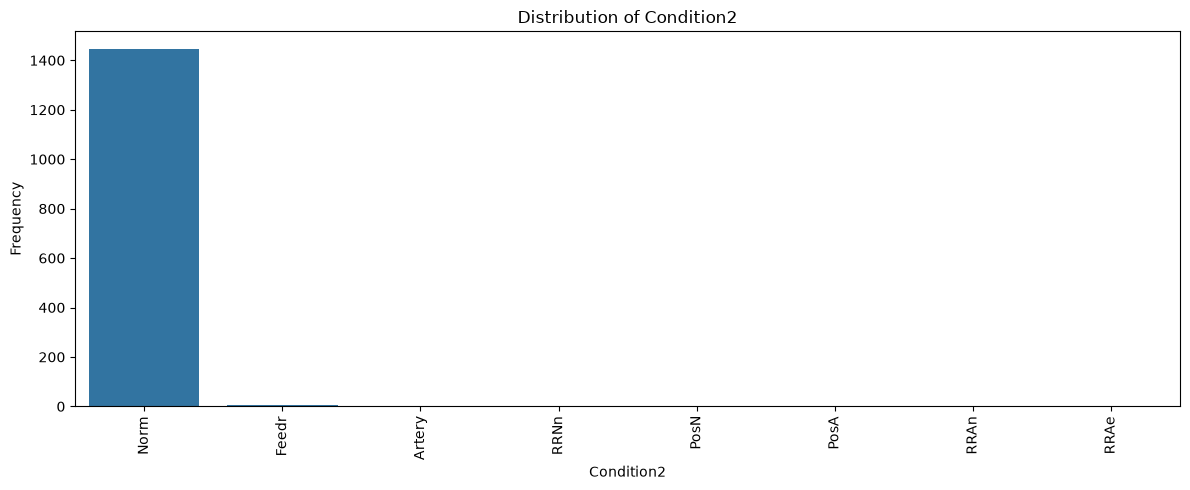

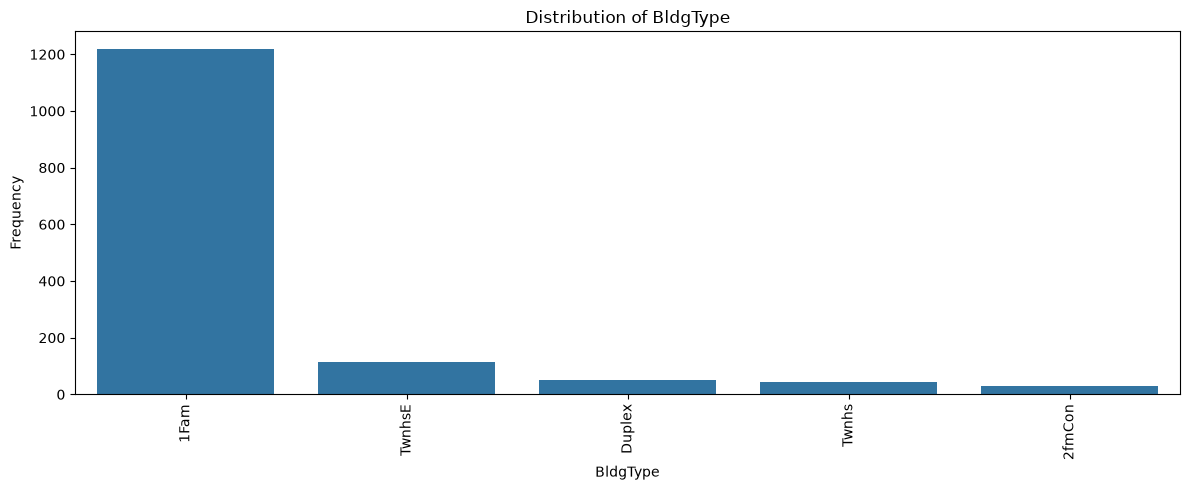

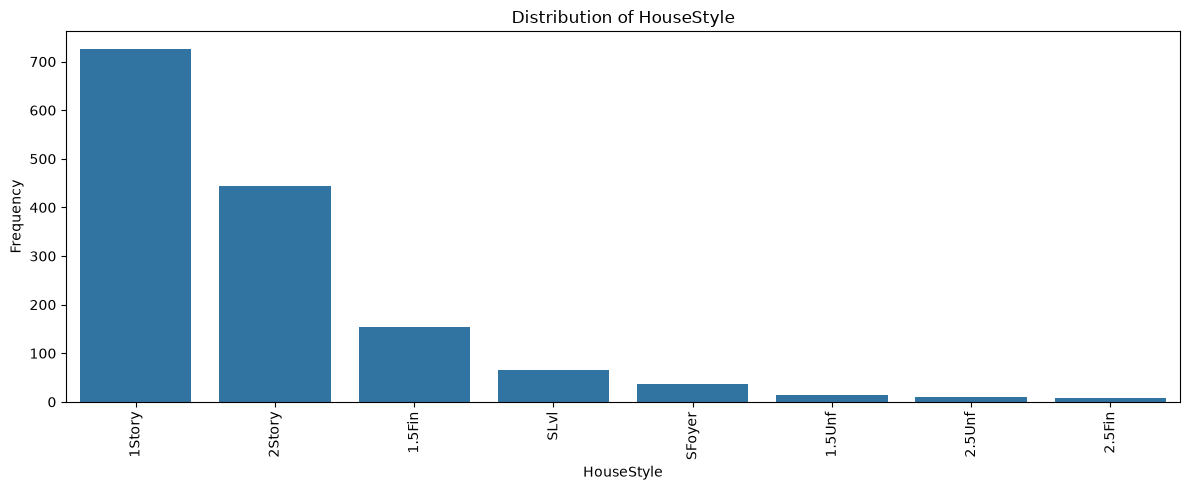

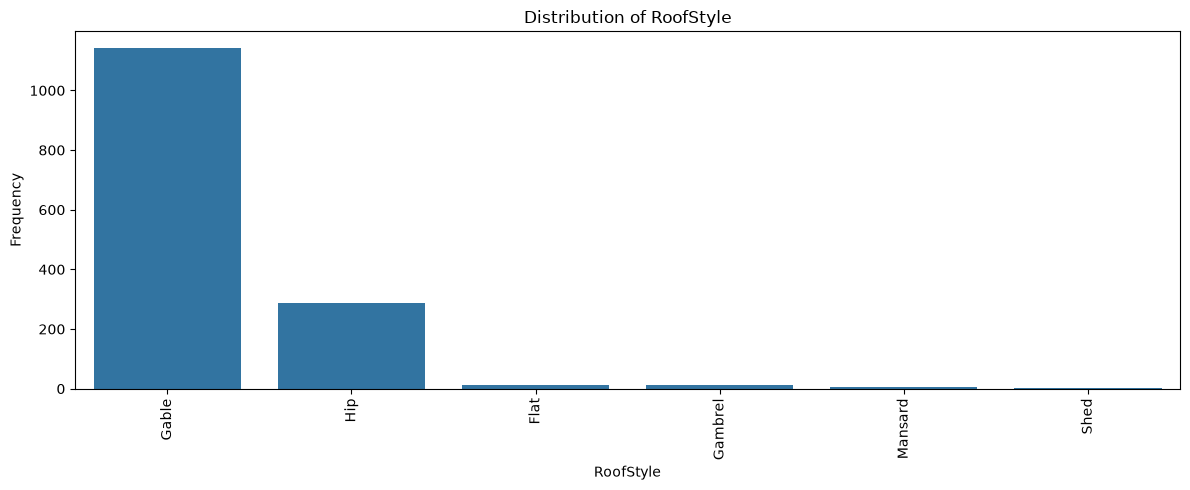

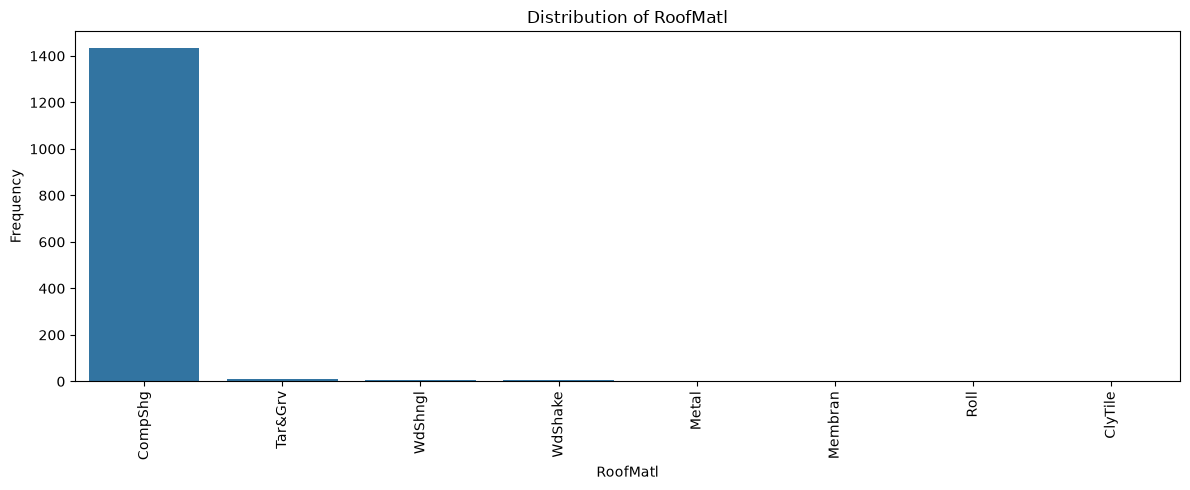

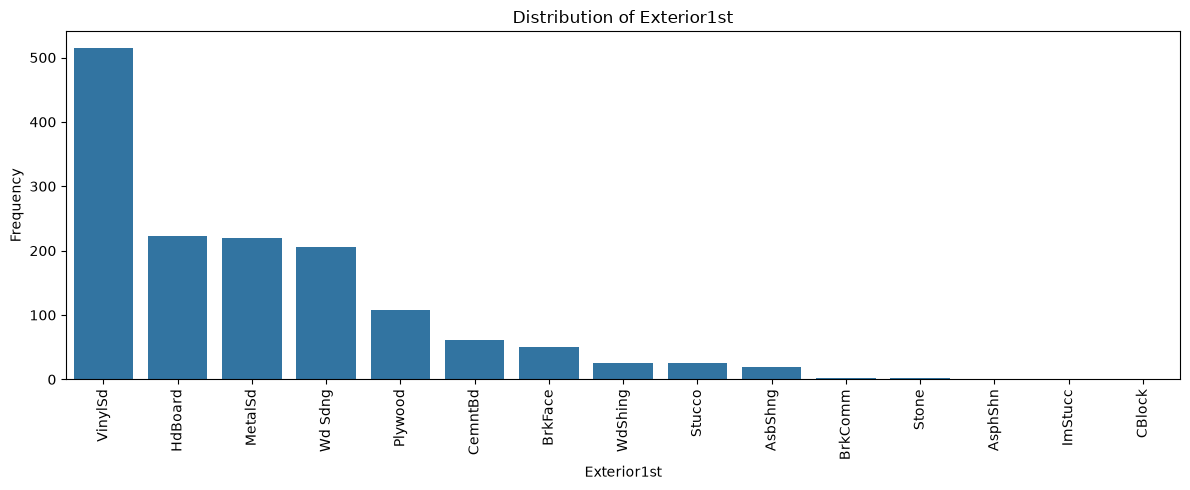

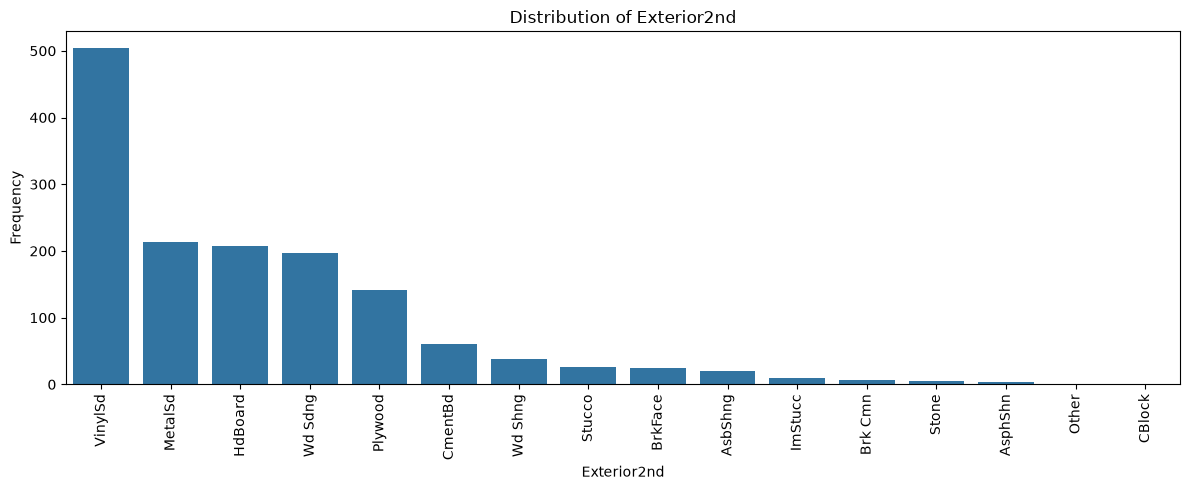

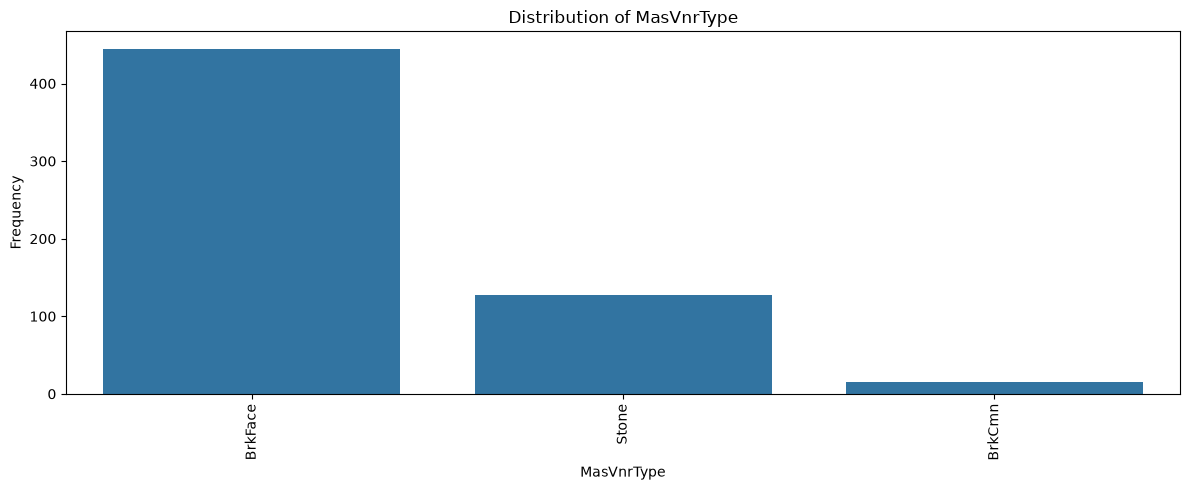

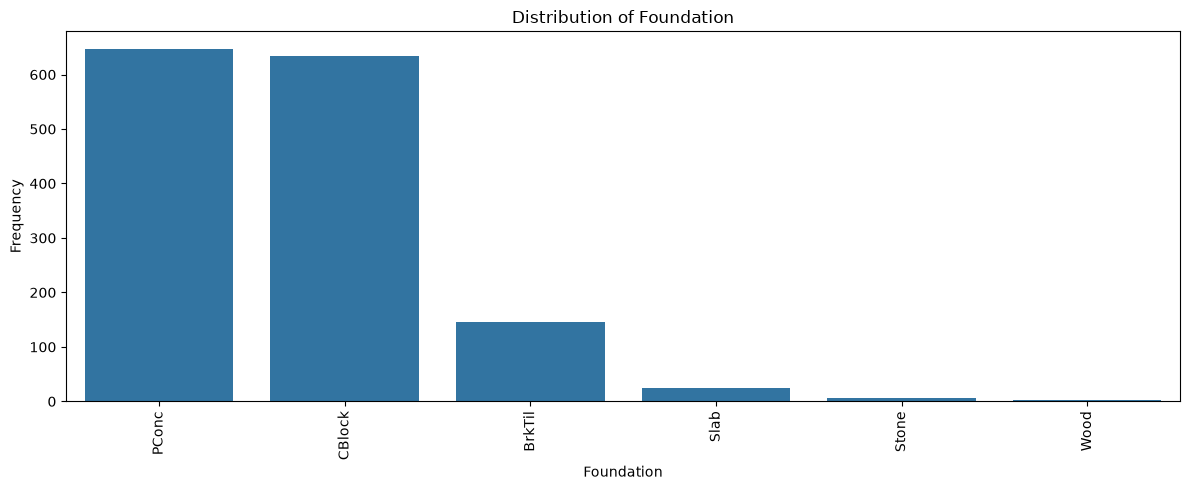

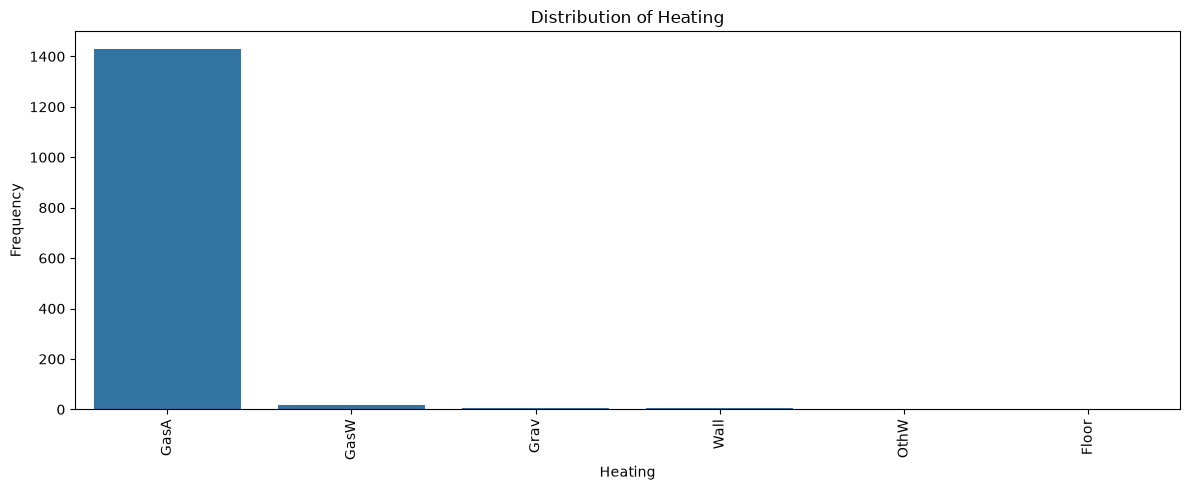

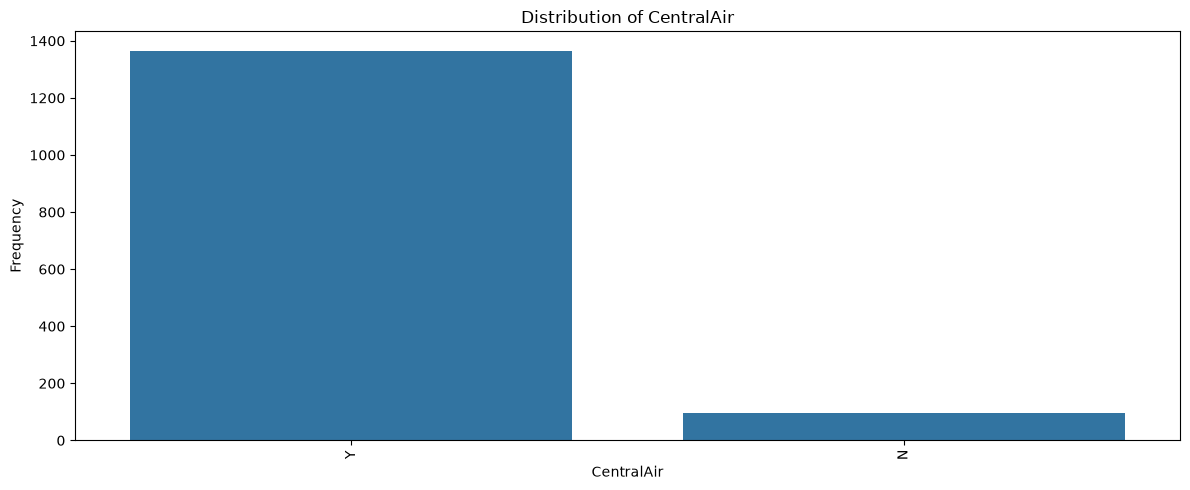

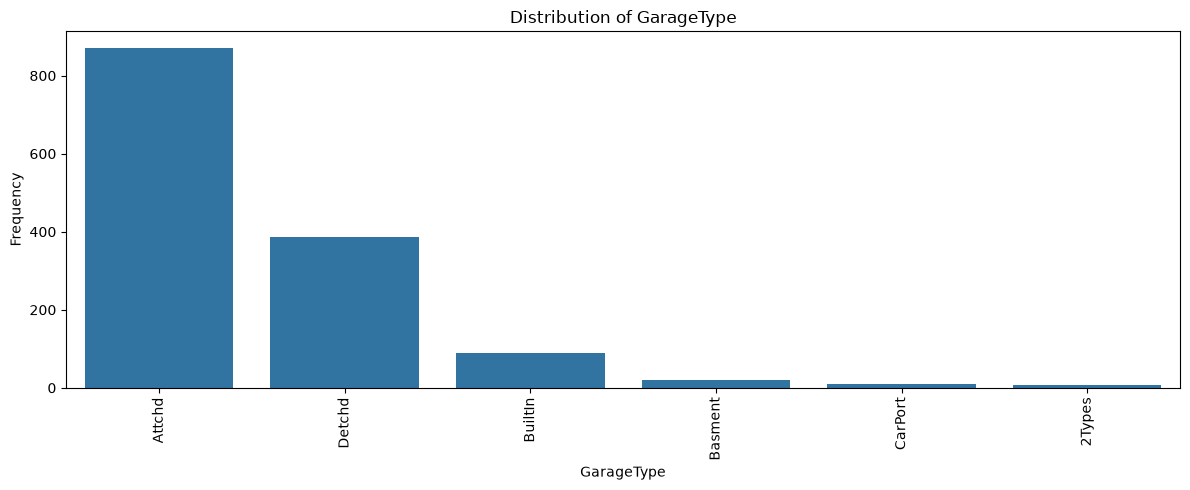

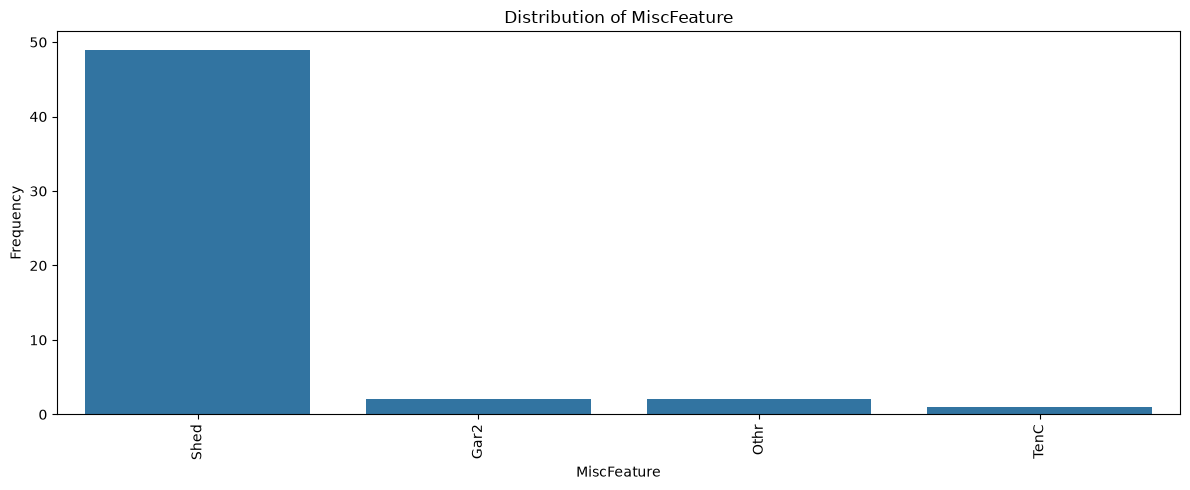

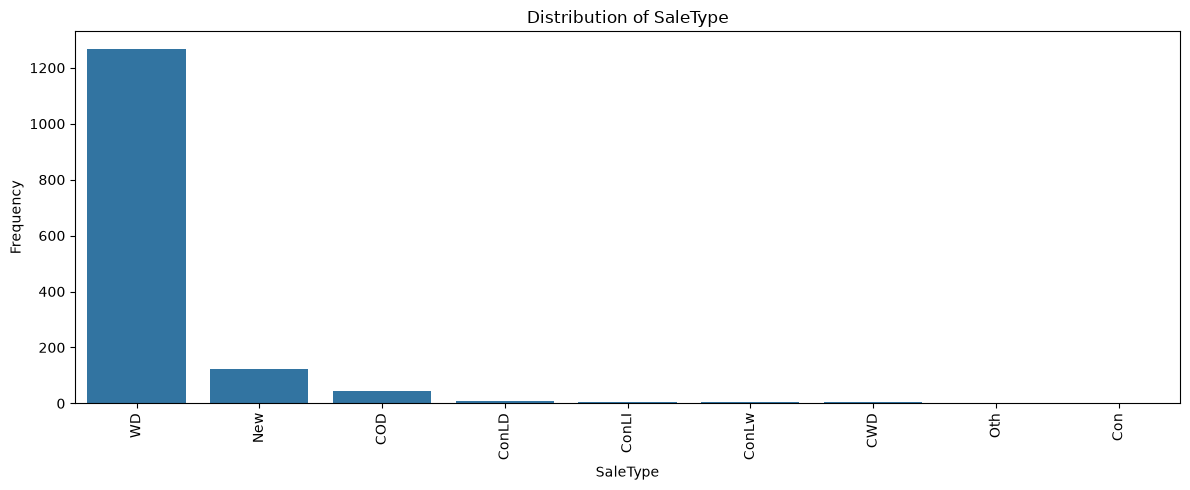

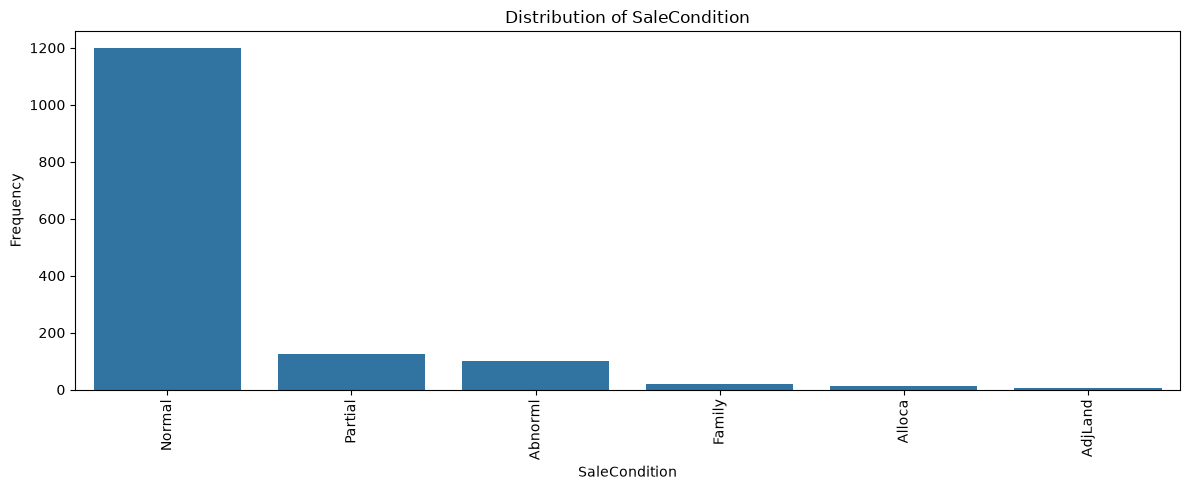

In [17]:
for col in nominal_vars:

    plt.figure(figsize=(12, 5))

    order = train[col].value_counts().index

    sns.countplot(
        data=train,
        x=col,
        order=order
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.xticks(rotation=90)

    plt.tight_layout()
    plt.show()

## Phân tích đa biến

## Continuos Variable

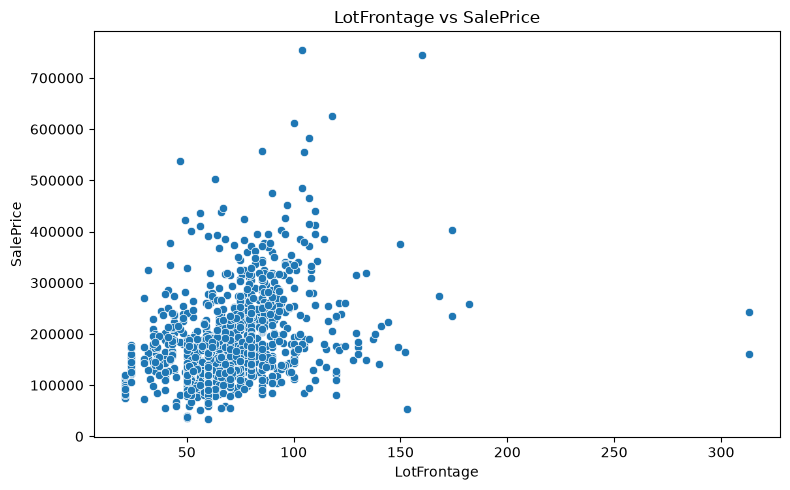

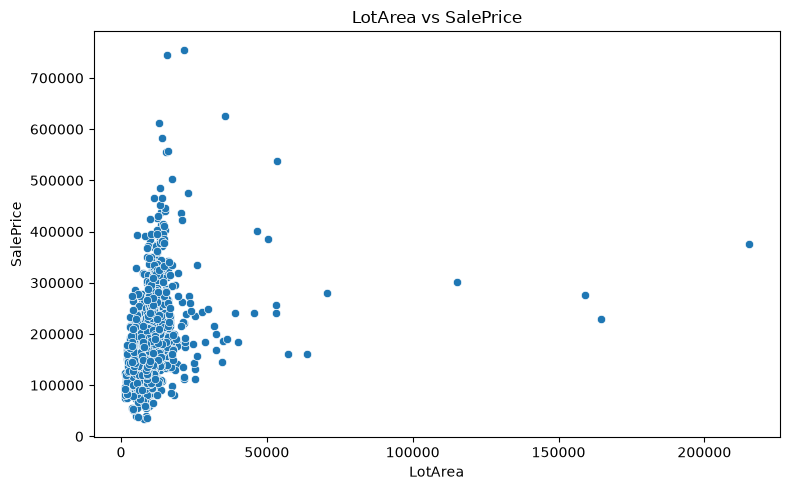

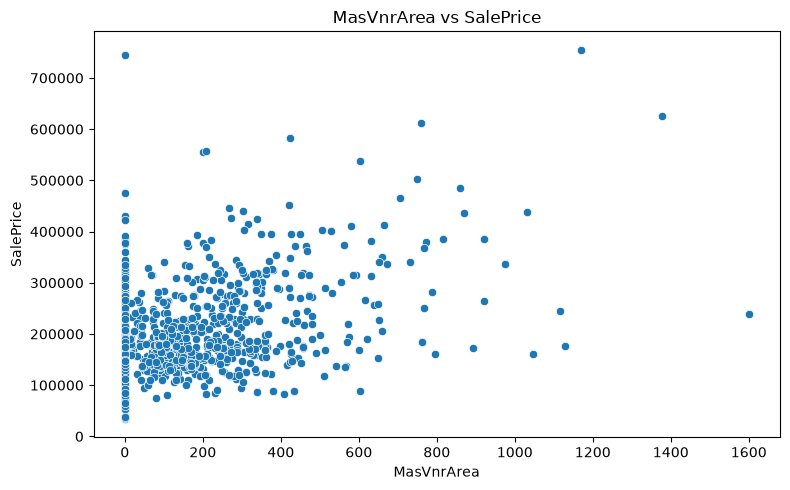

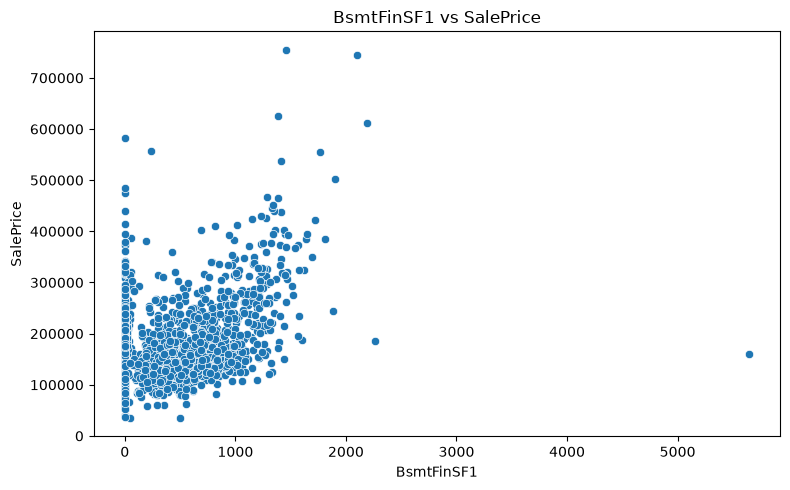

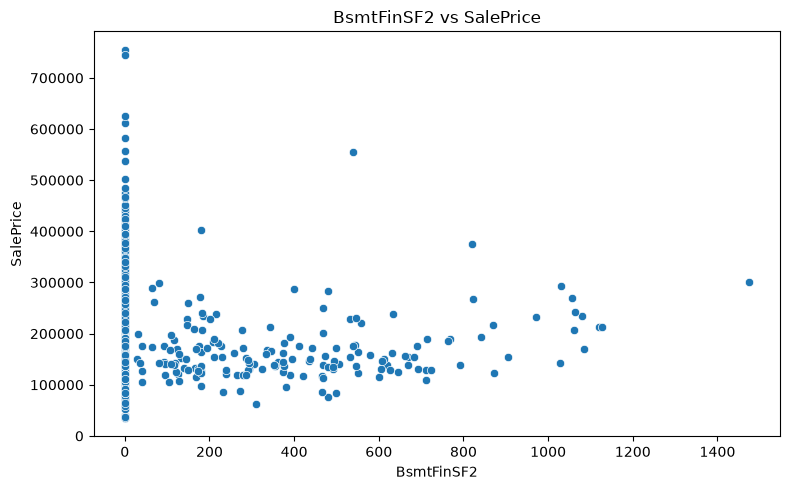

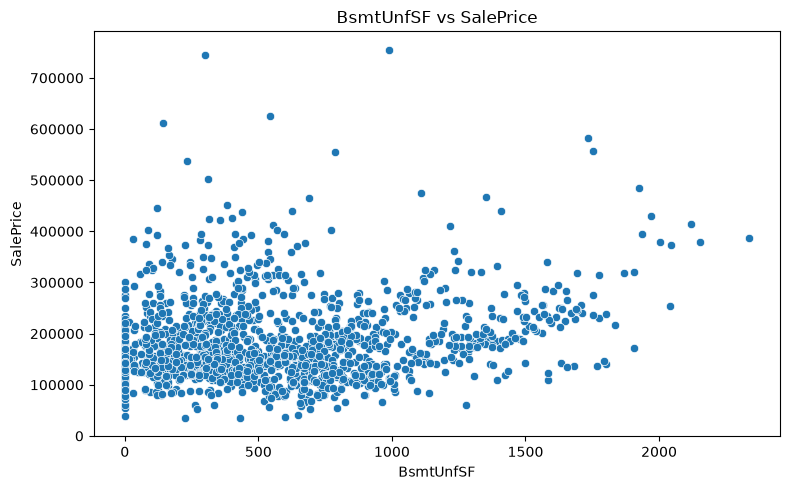

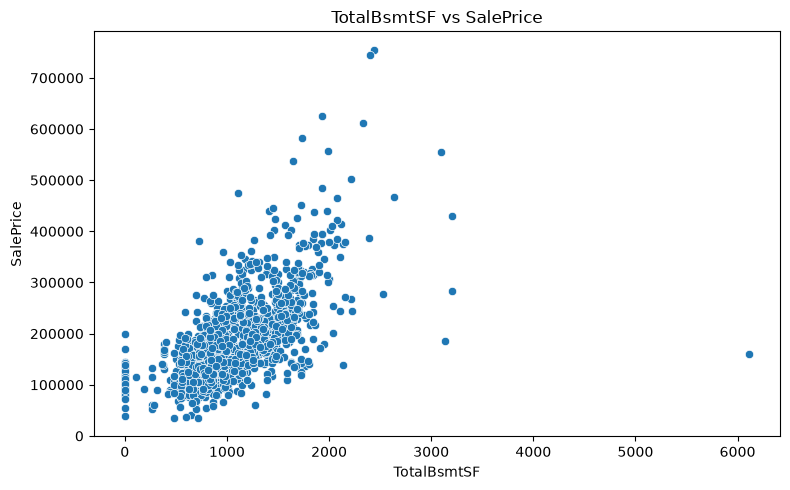

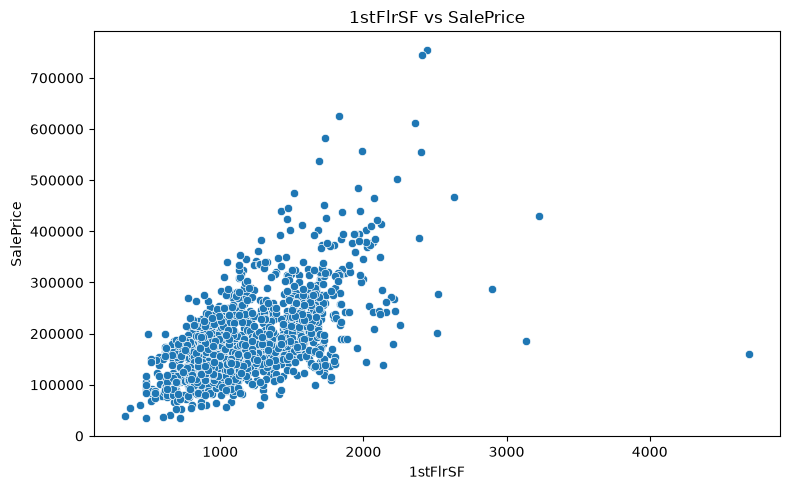

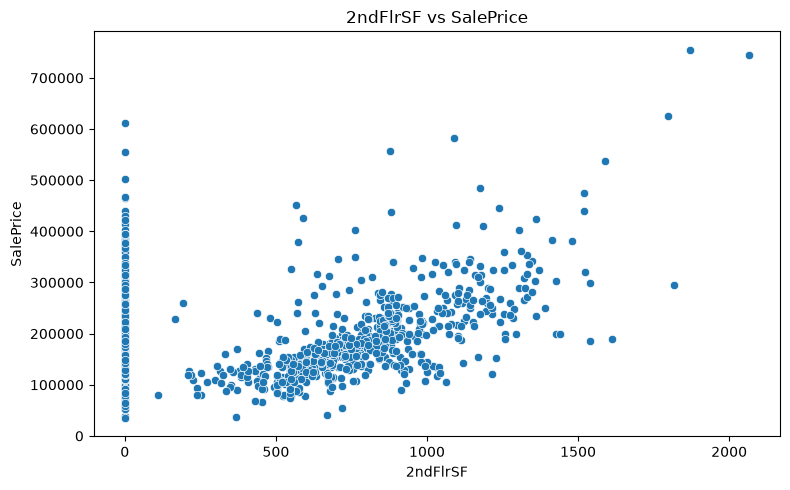

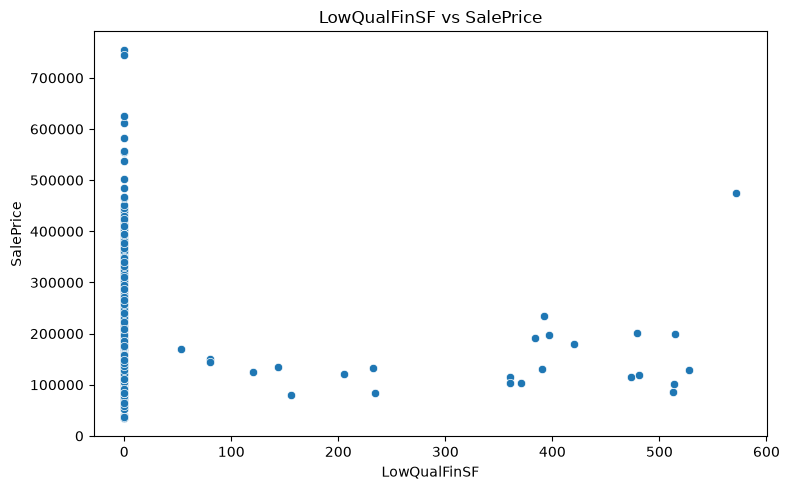

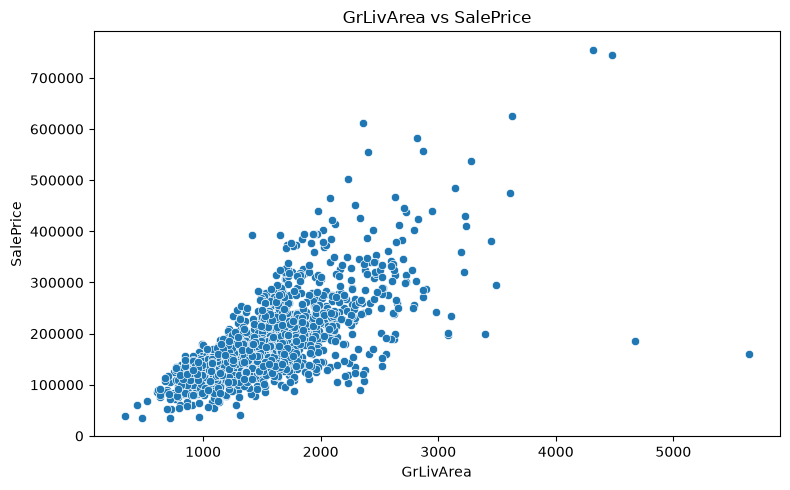

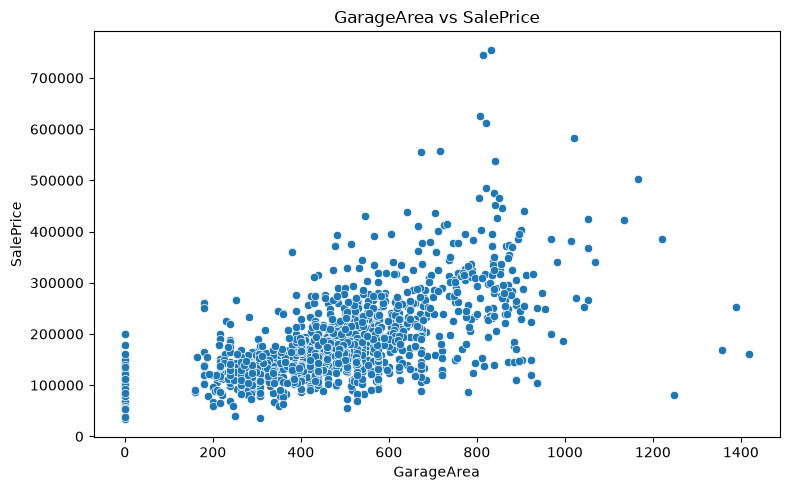

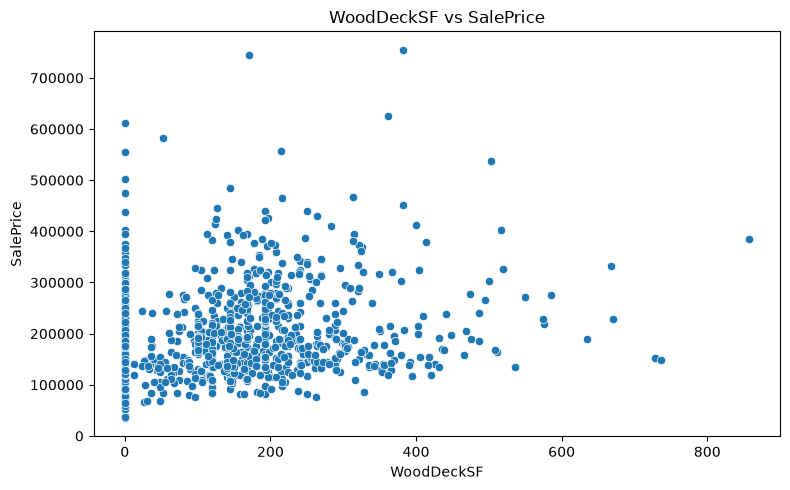

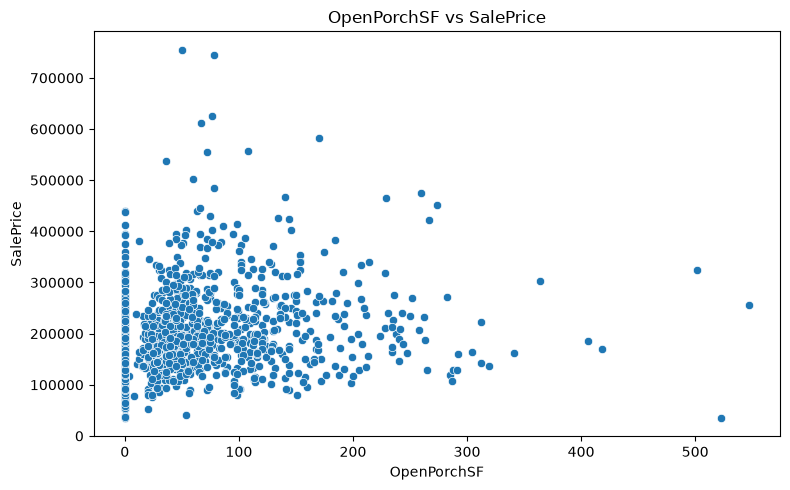

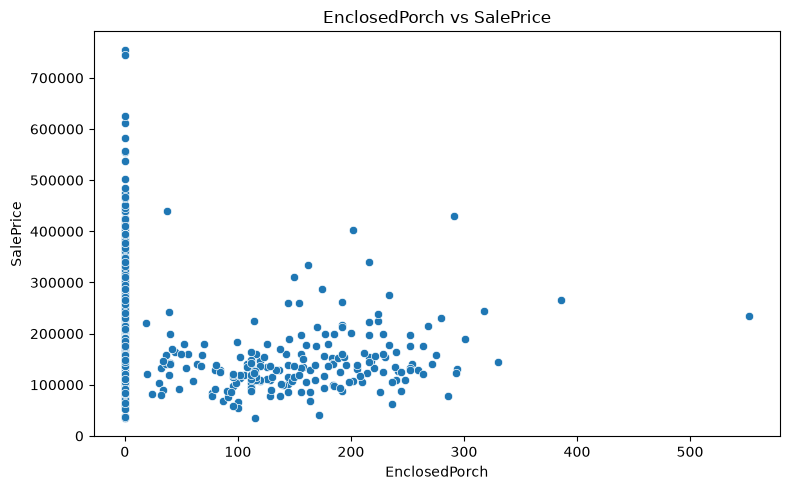

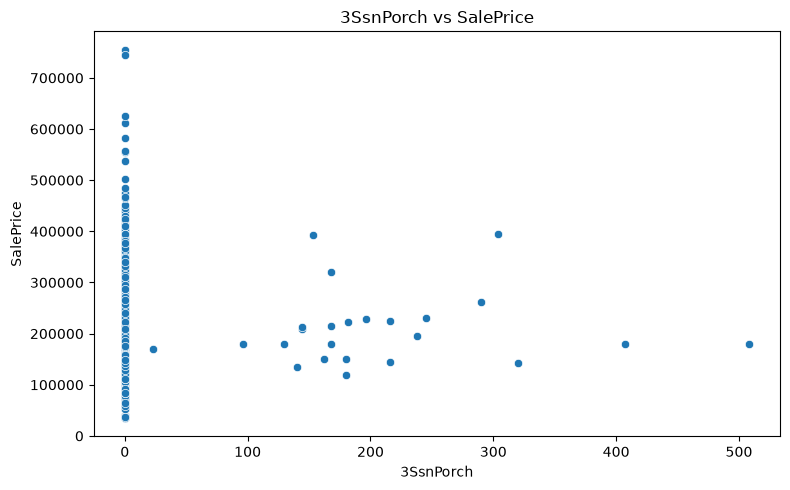

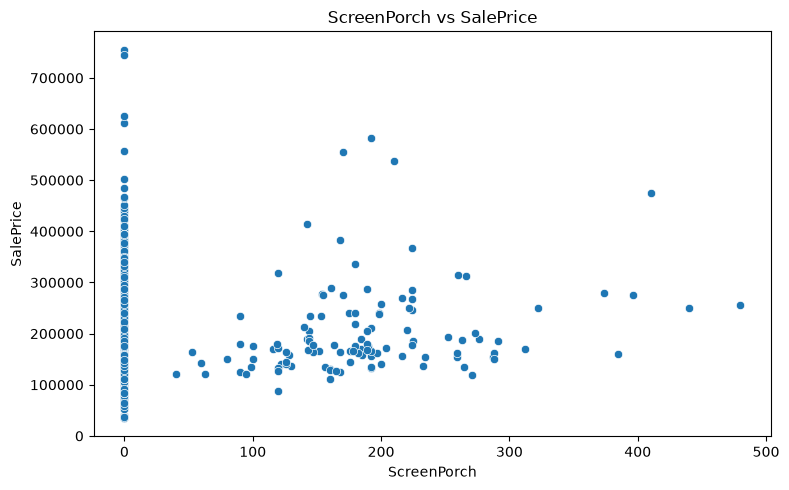

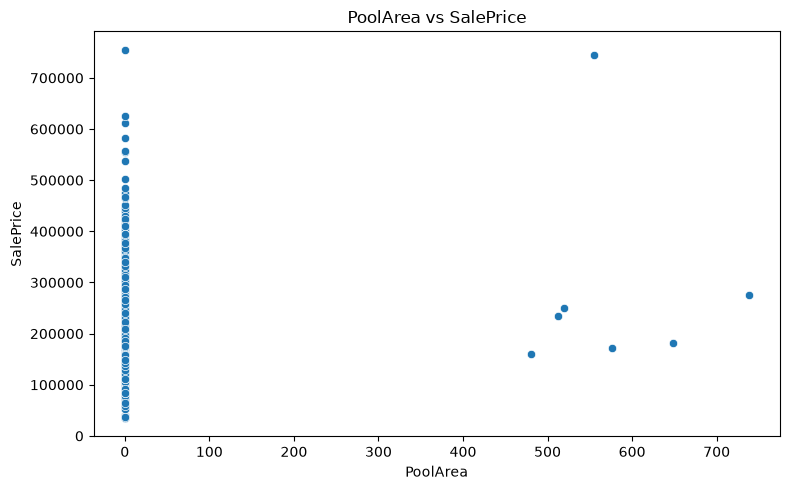

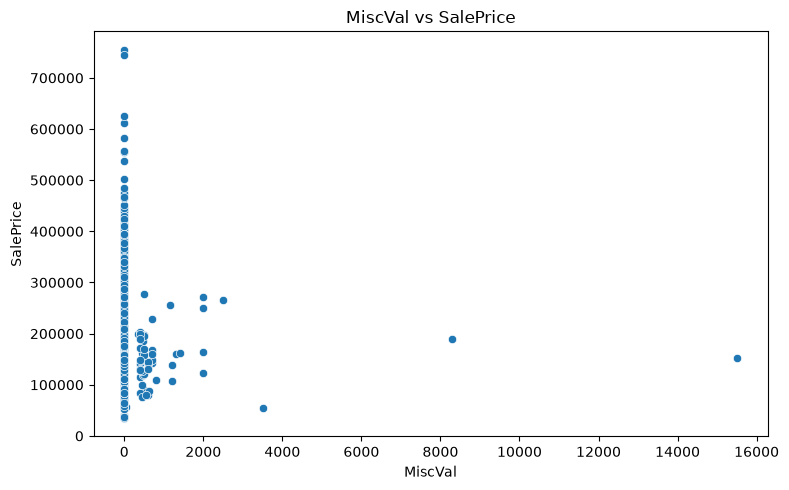

In [19]:
continuous_features = [
    col for col in continuous_vars
    if col != "SalePrice"
]

for col in continuous_features:

    plt.figure(figsize=(8, 5))

    sns.scatterplot(
        data=train,
        x=col,
        y="SalePrice",
    )

    plt.title(f"{col} vs SalePrice")
    plt.xlabel(col)
    plt.ylabel("SalePrice")

    plt.tight_layout()
    plt.show()

## Discrete Variable

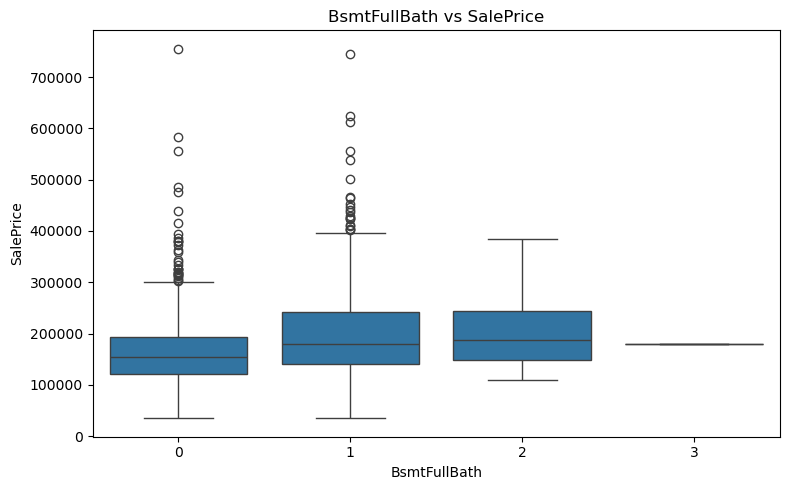

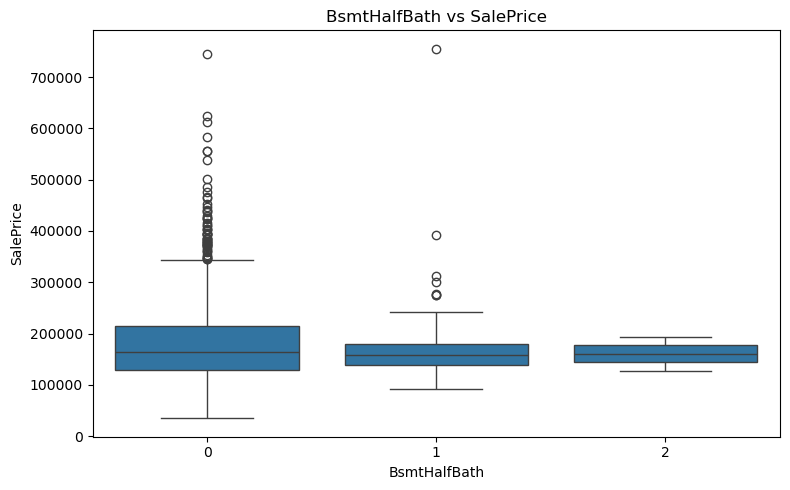

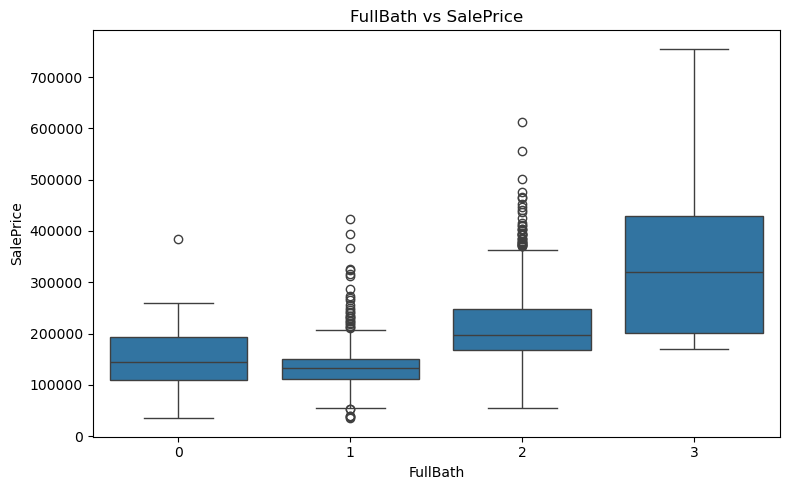

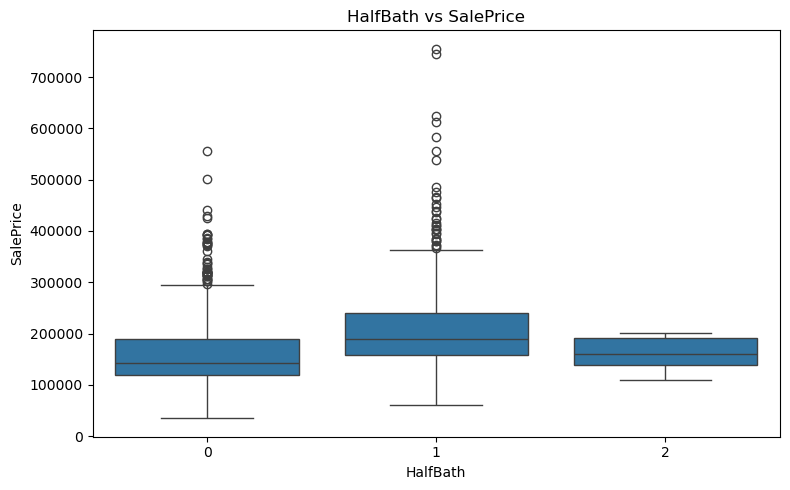

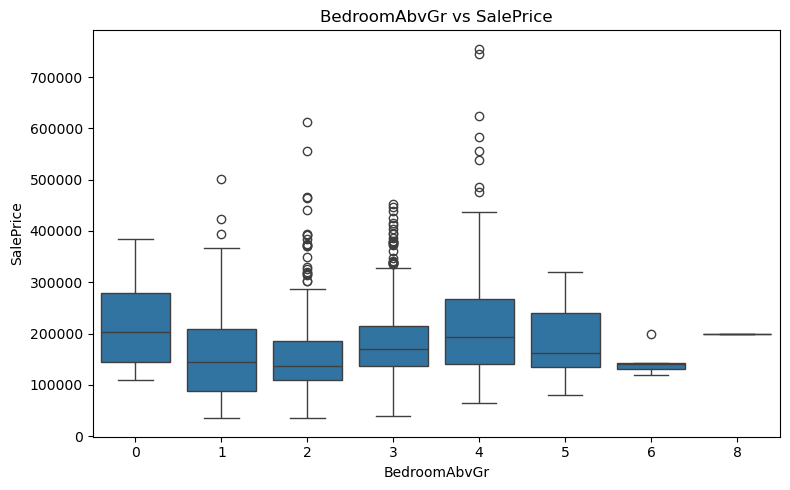

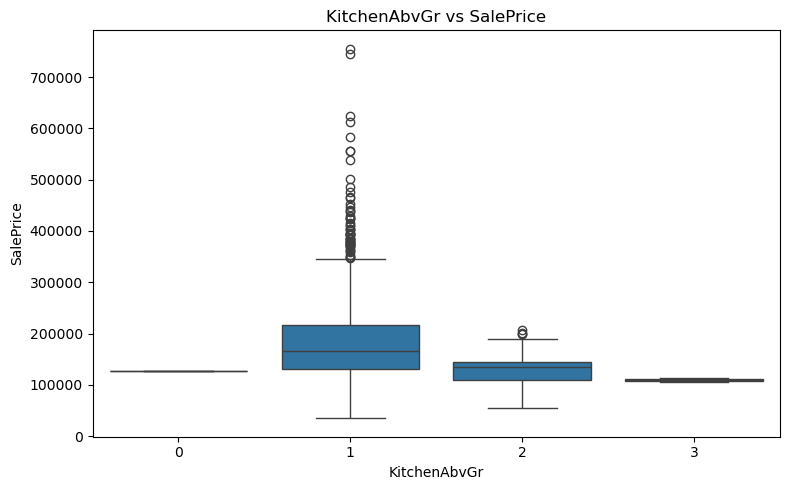

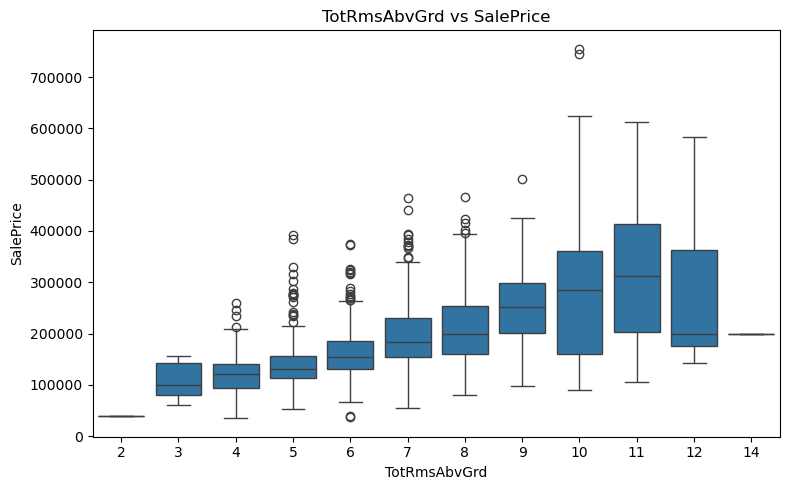

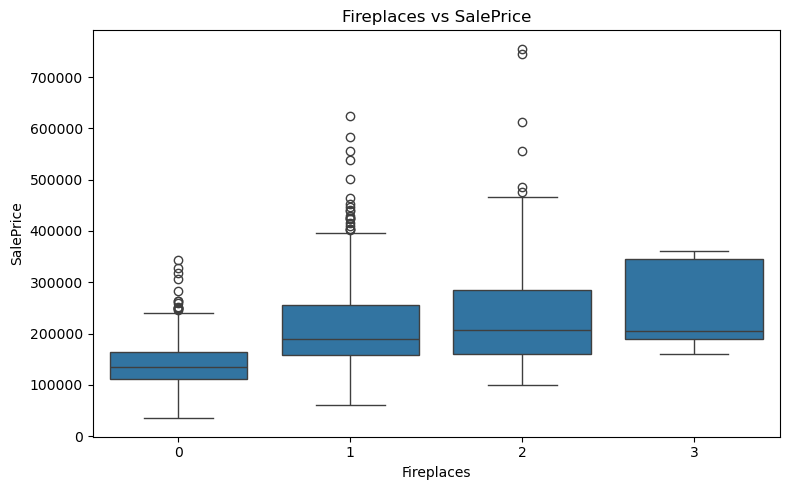

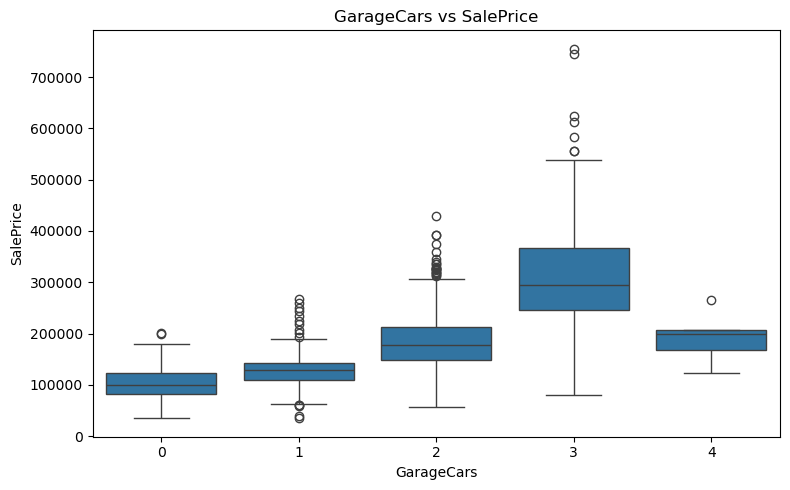

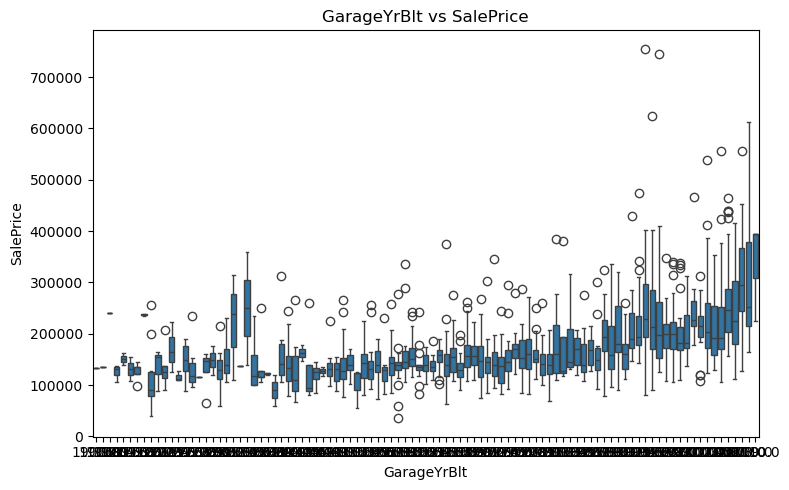

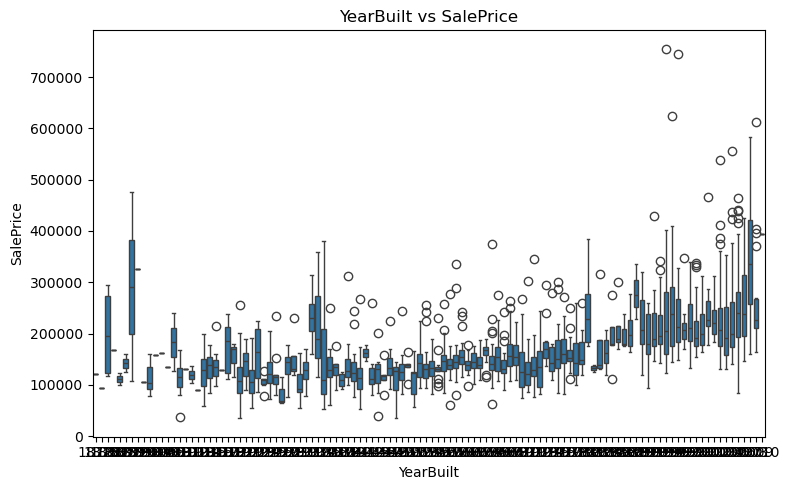

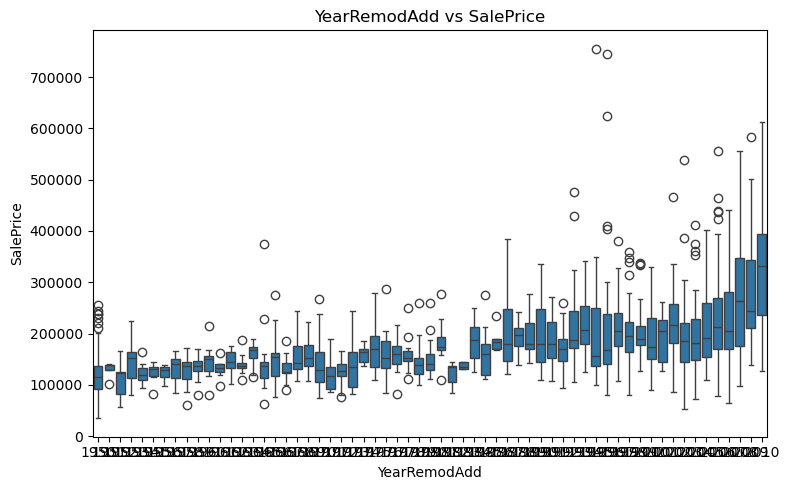

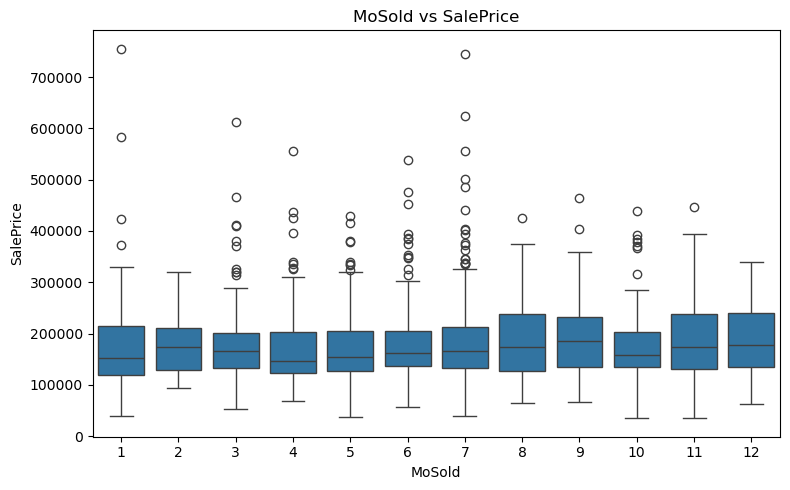

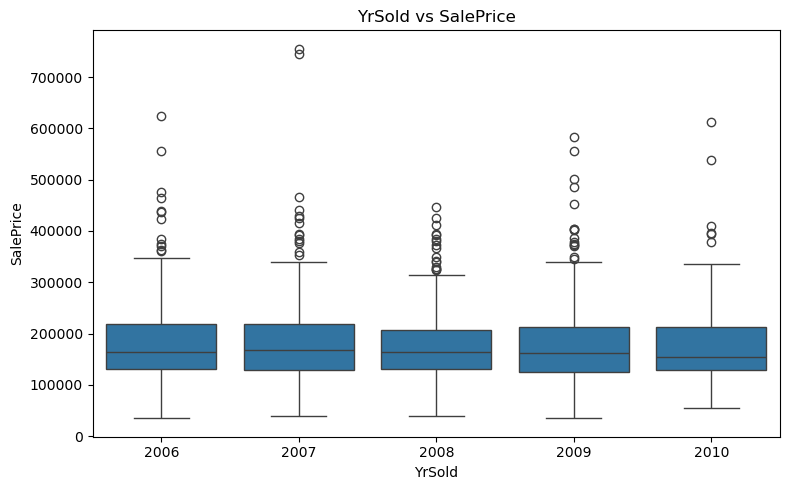

In [ ]:
for col in discrete_vars:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=train,
        x=col,
        y="SalePrice"
    )

    plt.title(f"{col} vs SalePrice")
    plt.xlabel(col)
    plt.ylabel("SalePrice")

    plt.tight_layout()
    plt.show()

## Ordinal Variable

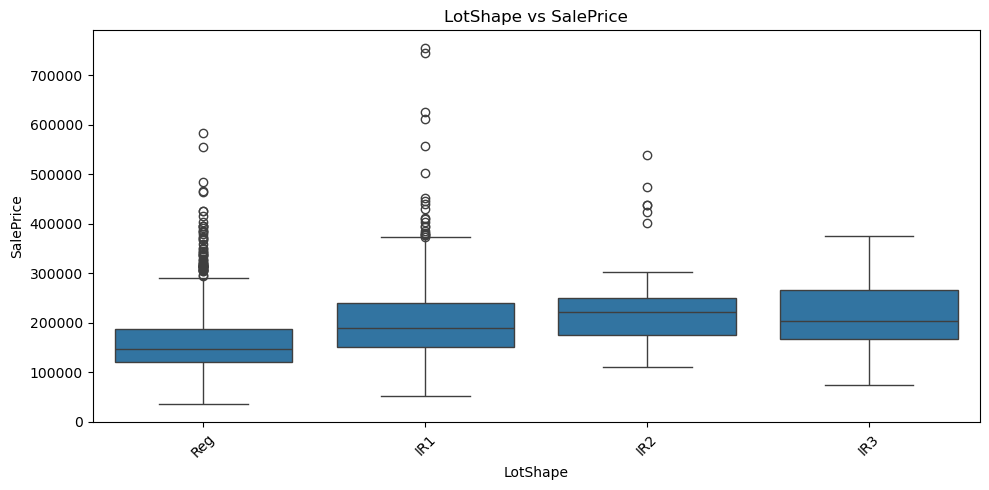

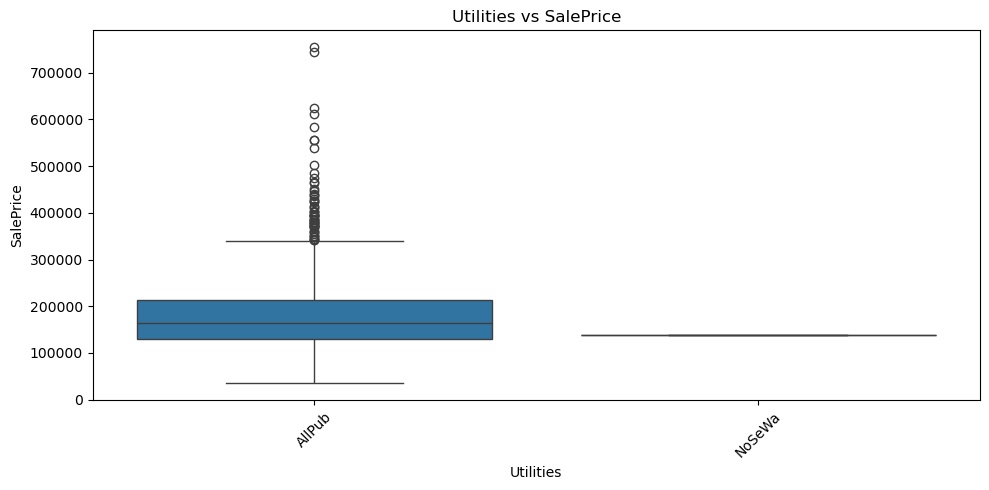

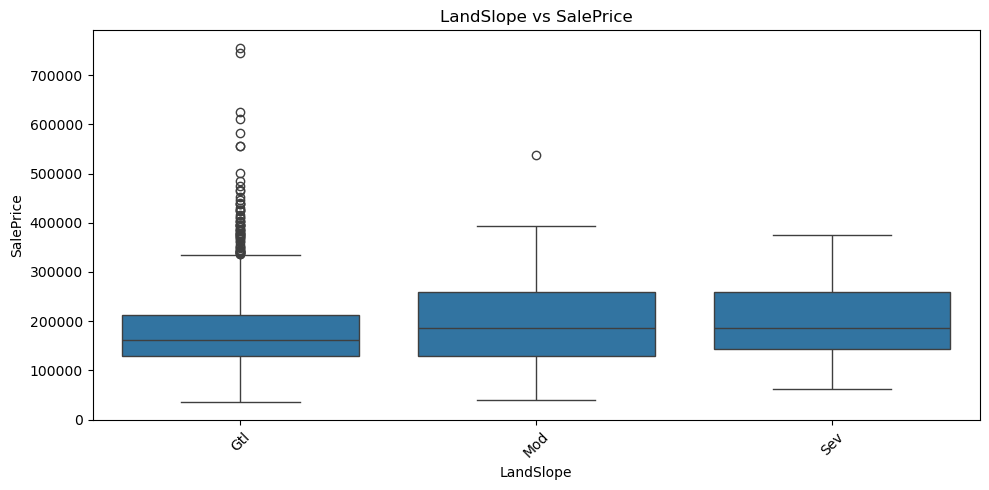

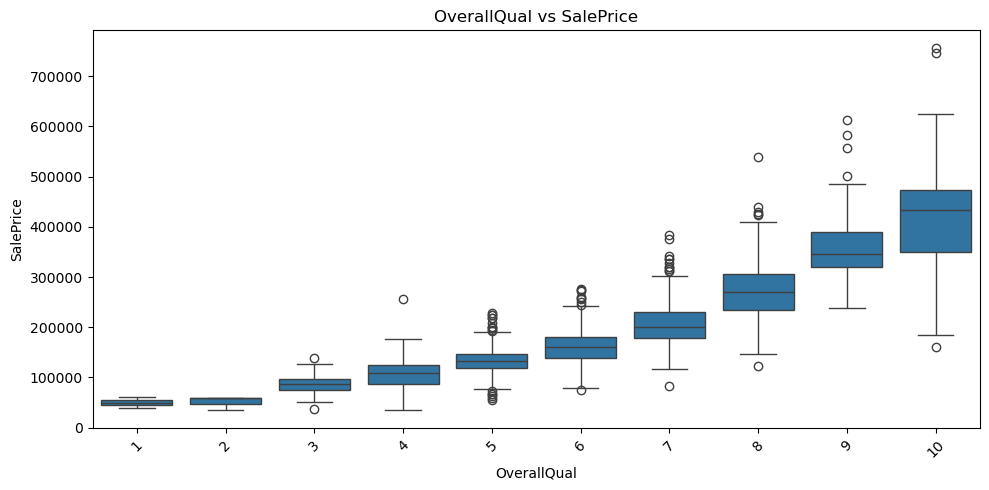

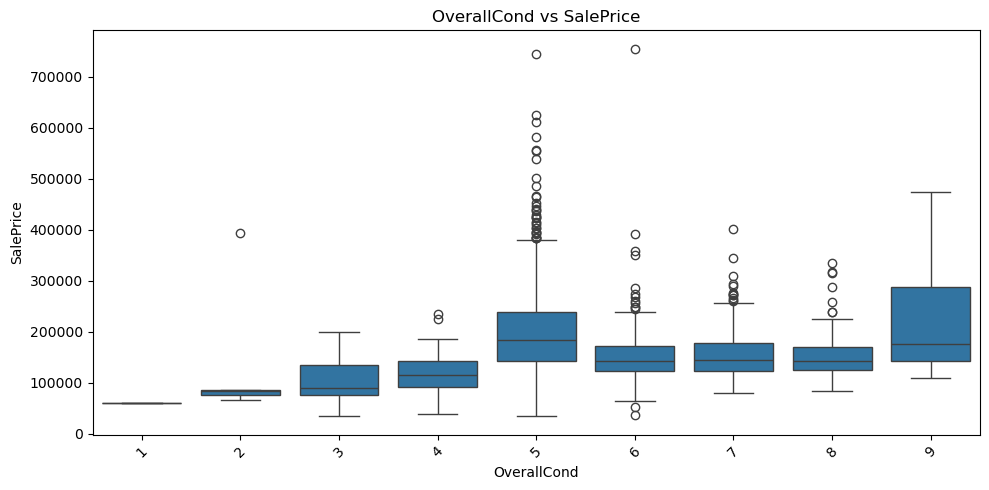

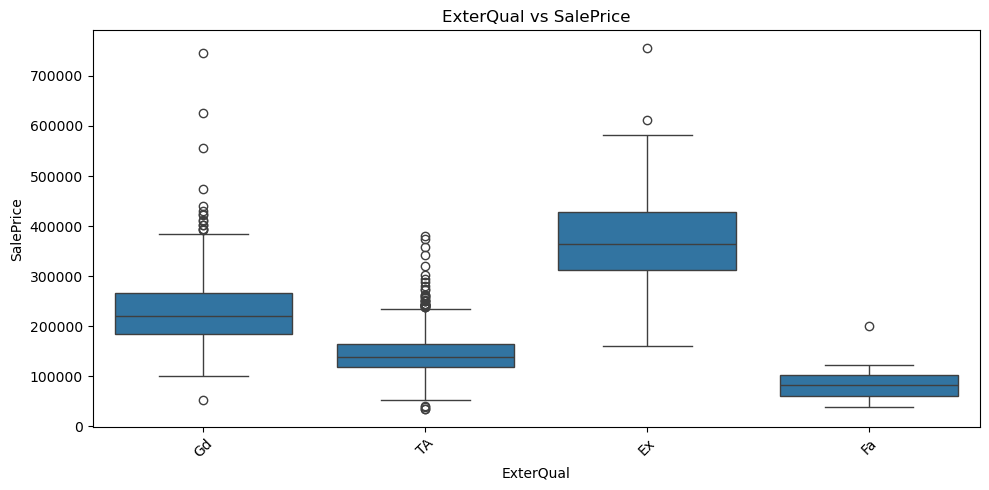

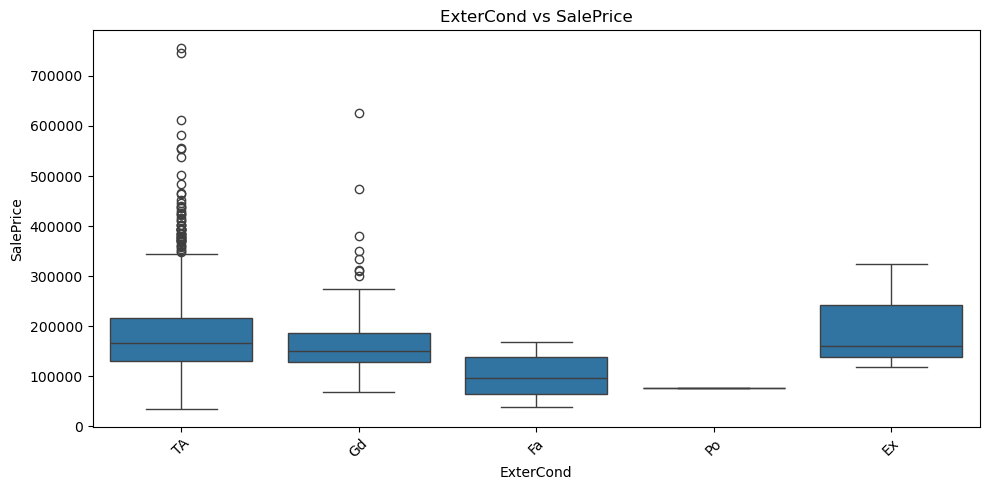

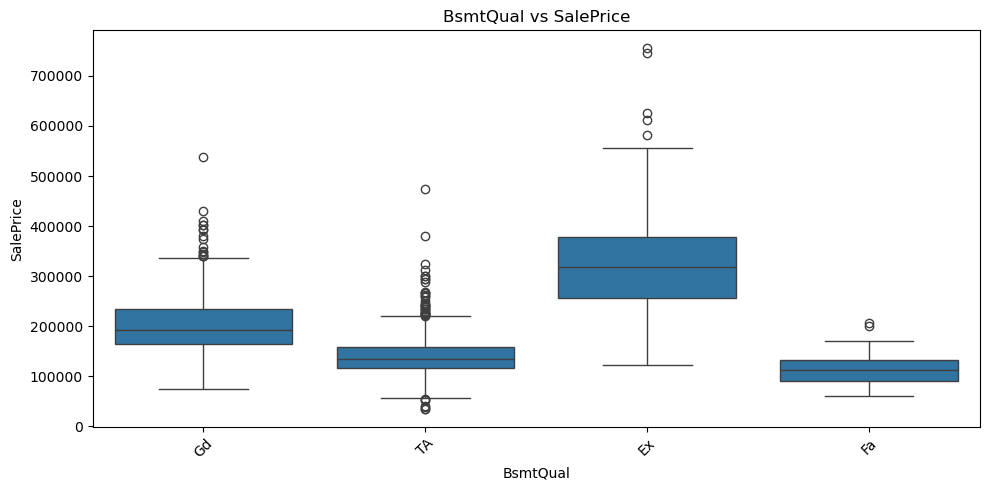

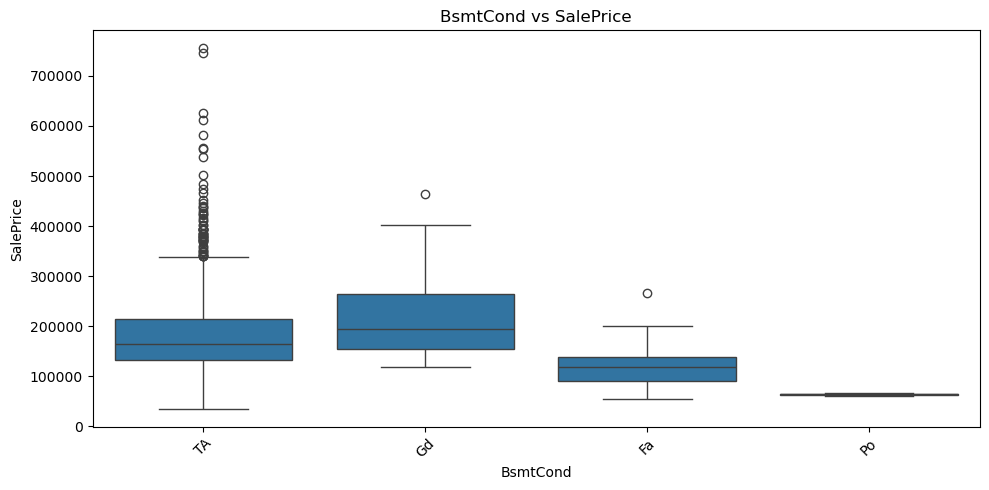

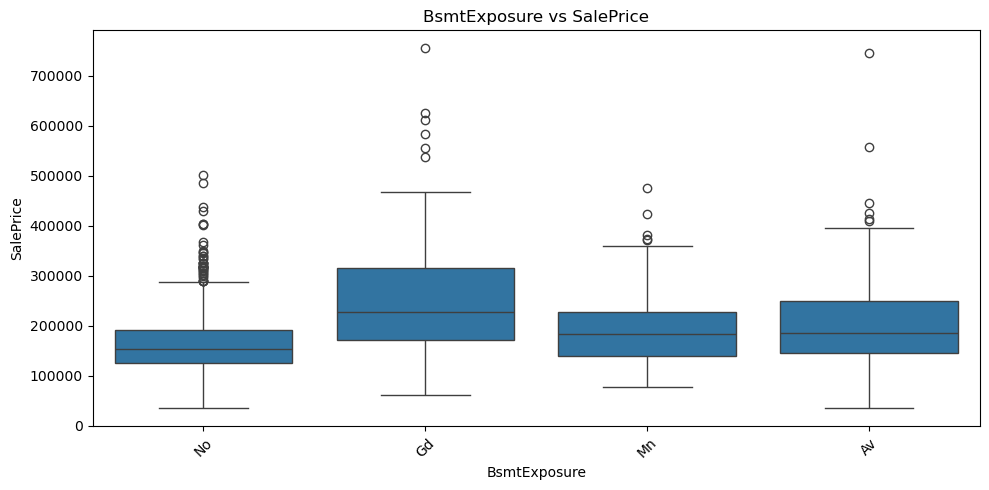

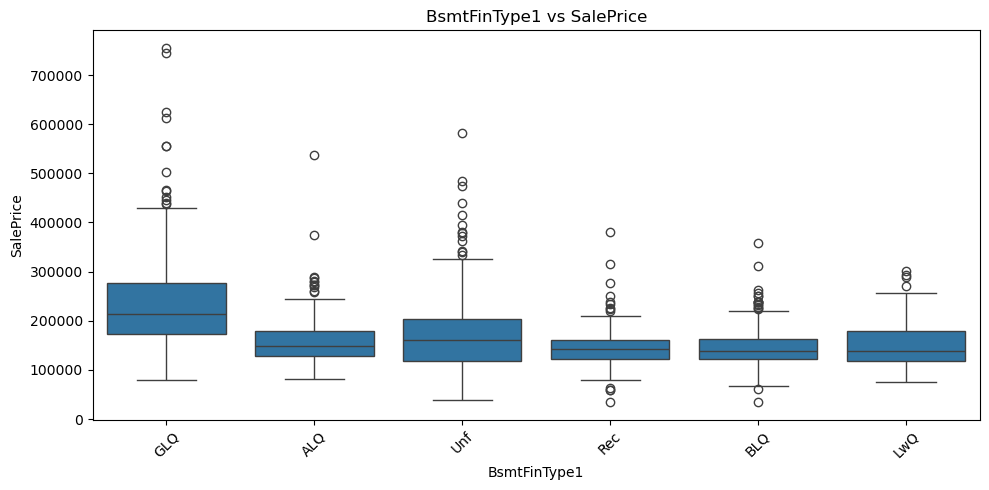

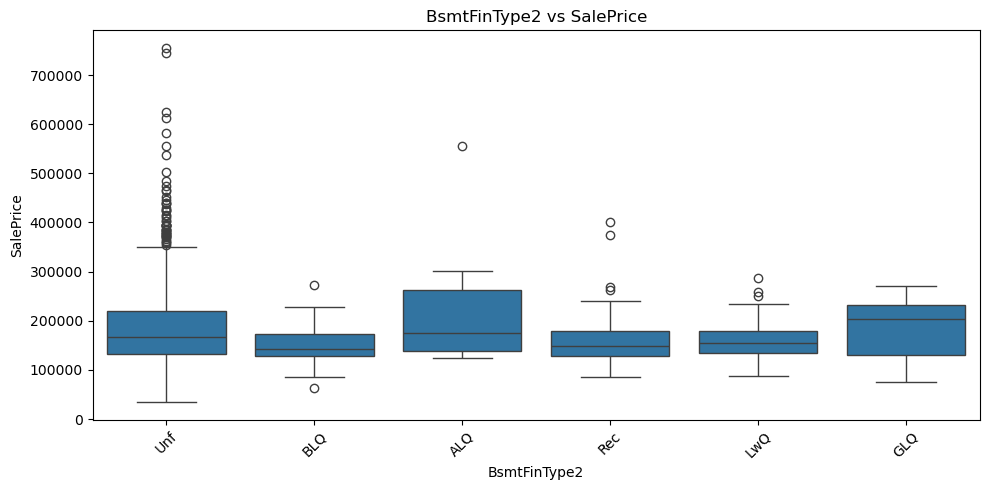

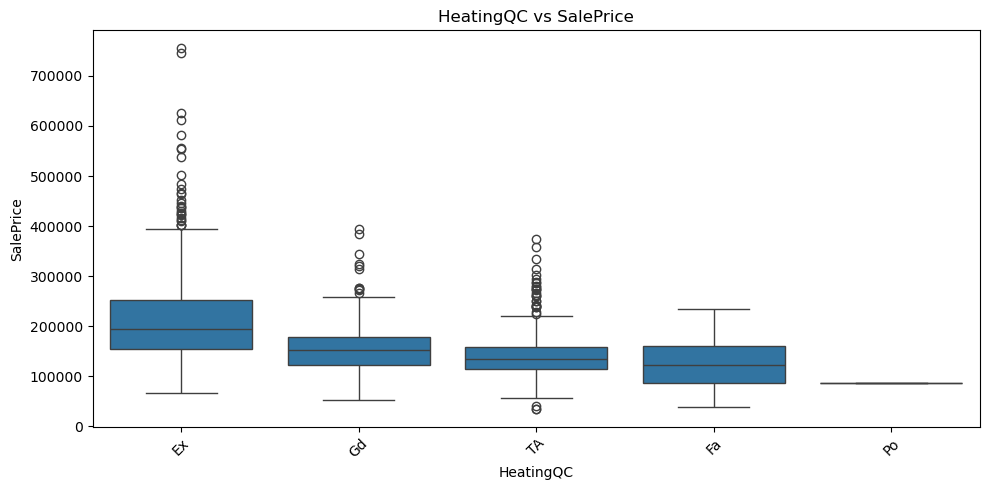

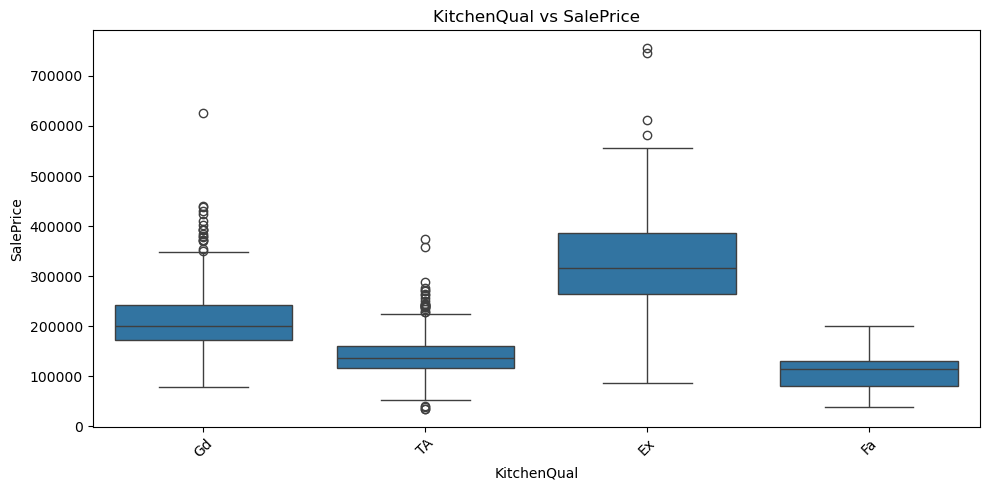

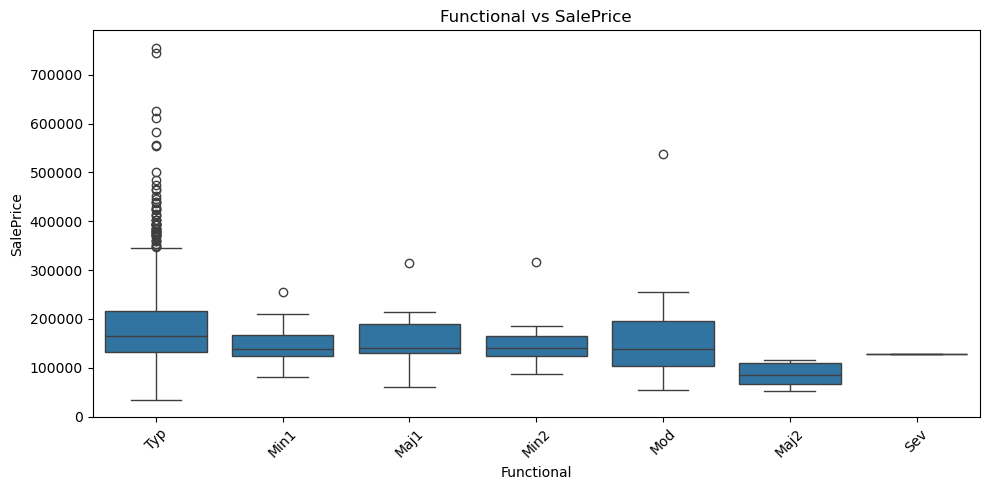

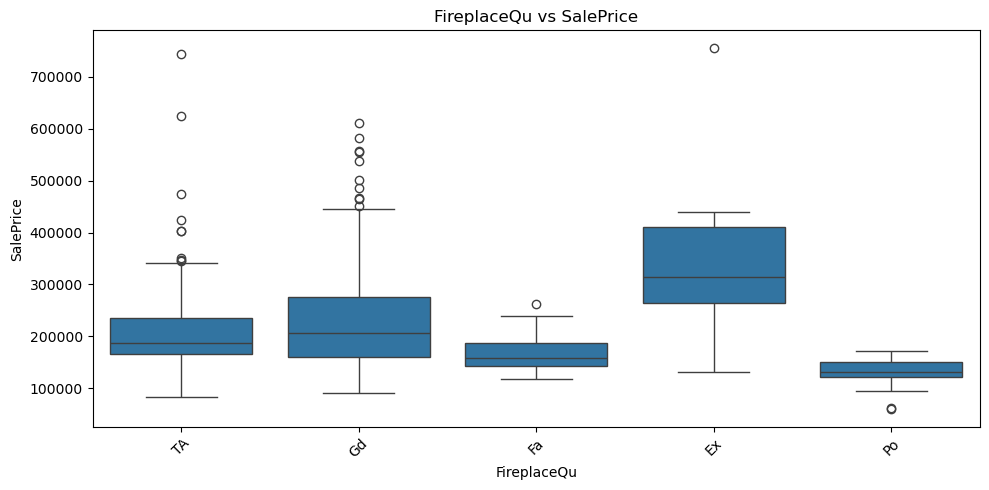

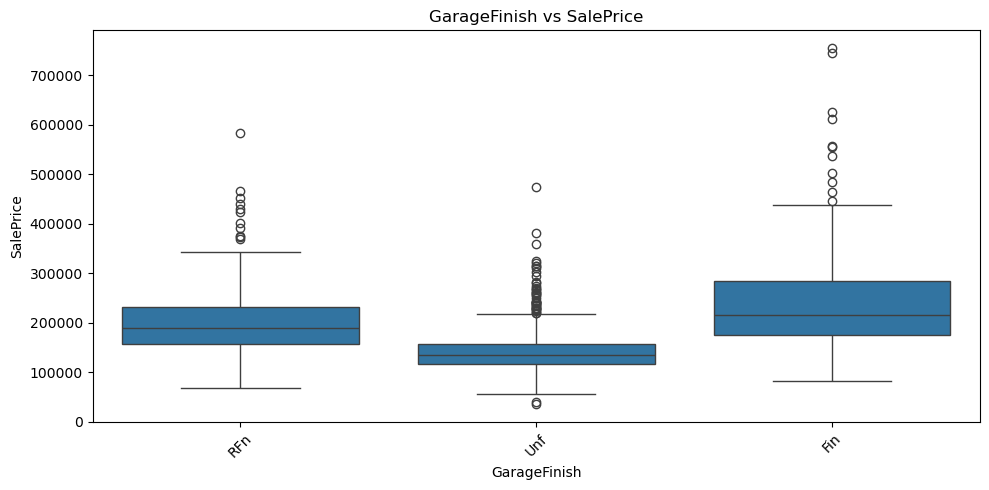

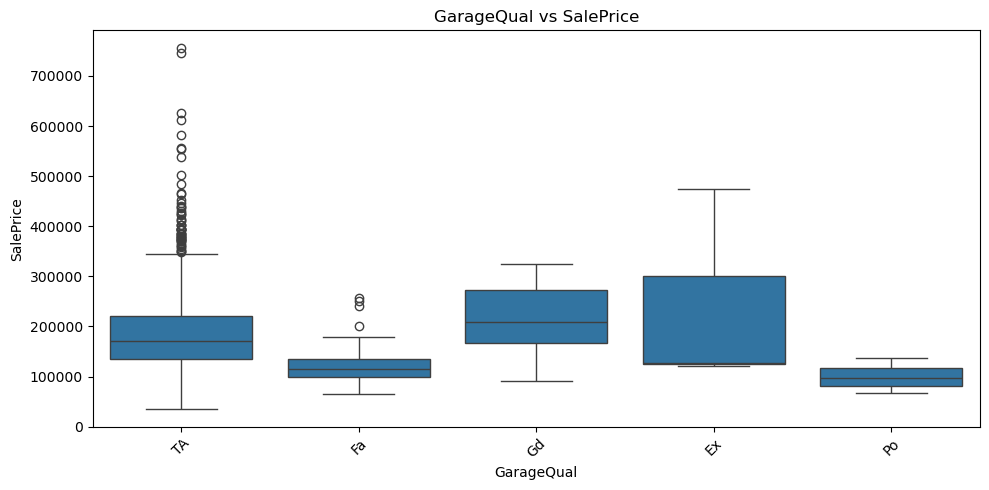

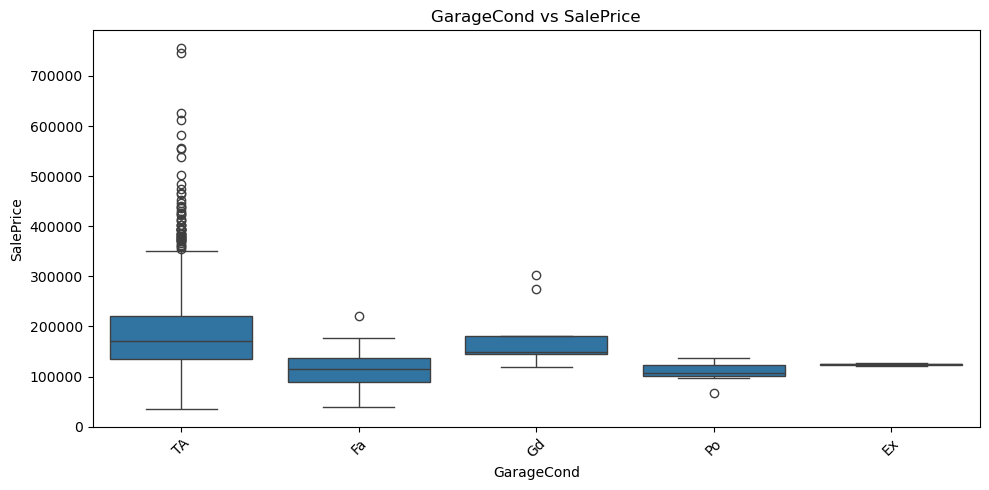

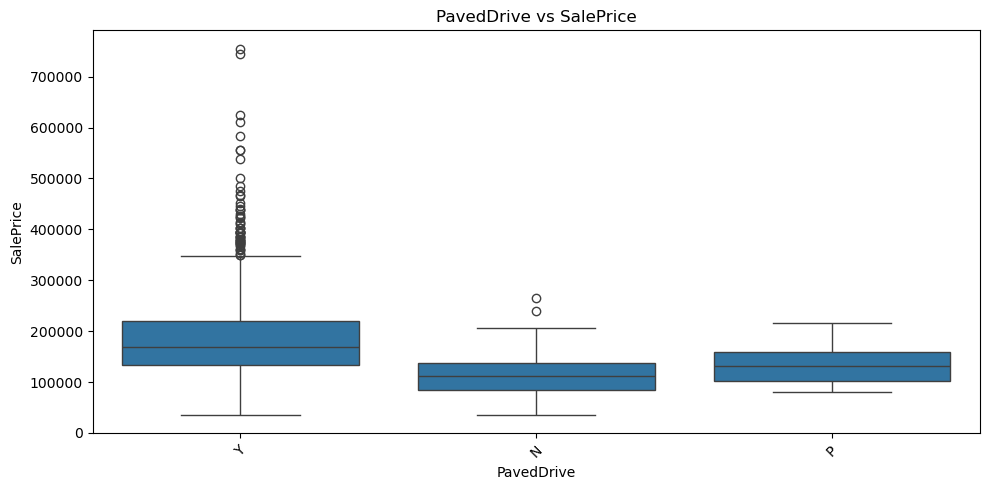

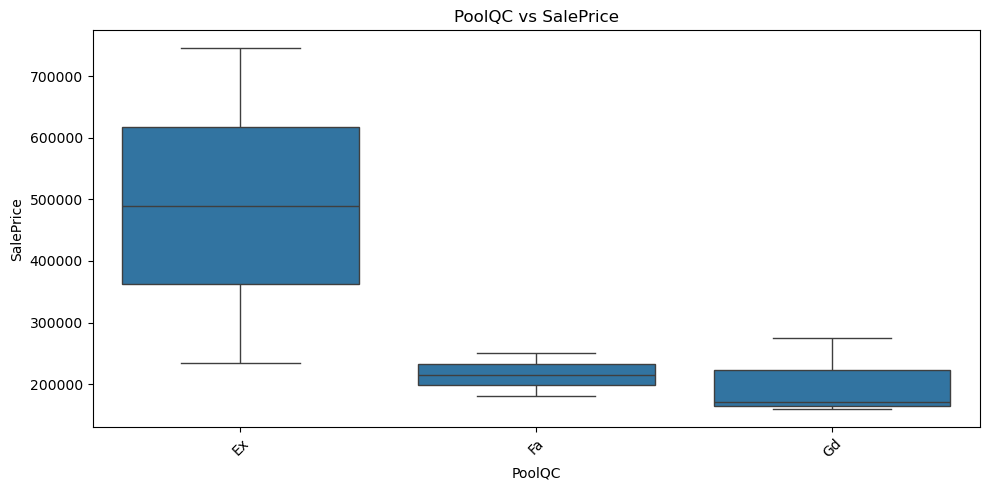

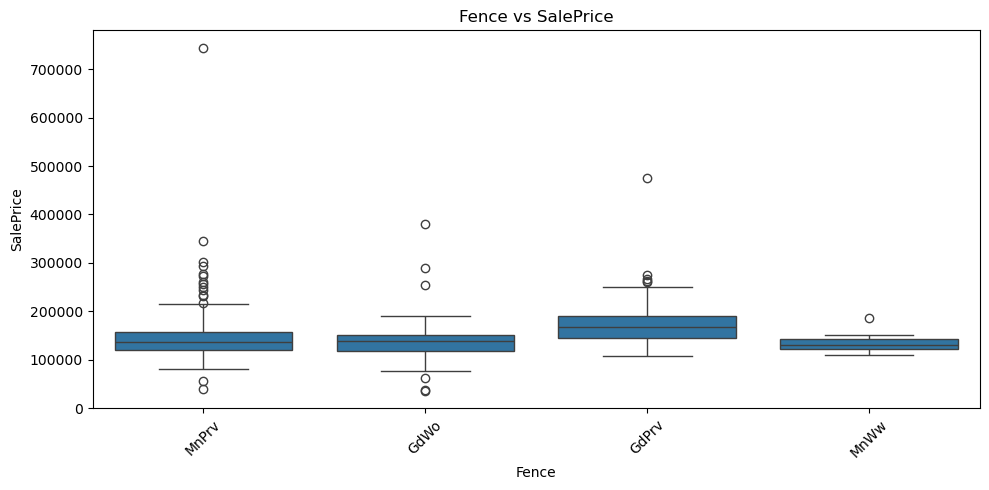

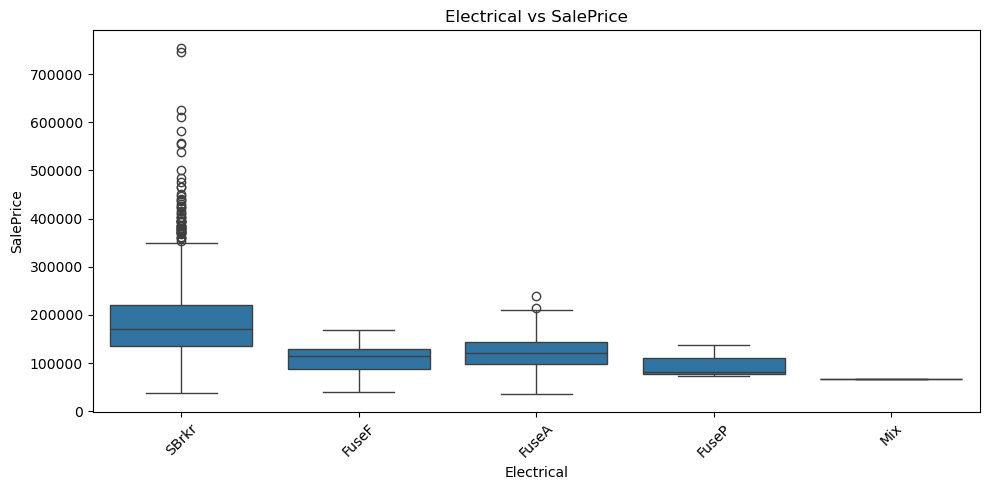

In [ ]:
for col in ordinal_vars:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=train,
        x=col,
        y="SalePrice"
    )

    plt.title(f"{col} vs SalePrice")
    plt.xlabel(col)
    plt.ylabel("SalePrice")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

## Nominal Variable

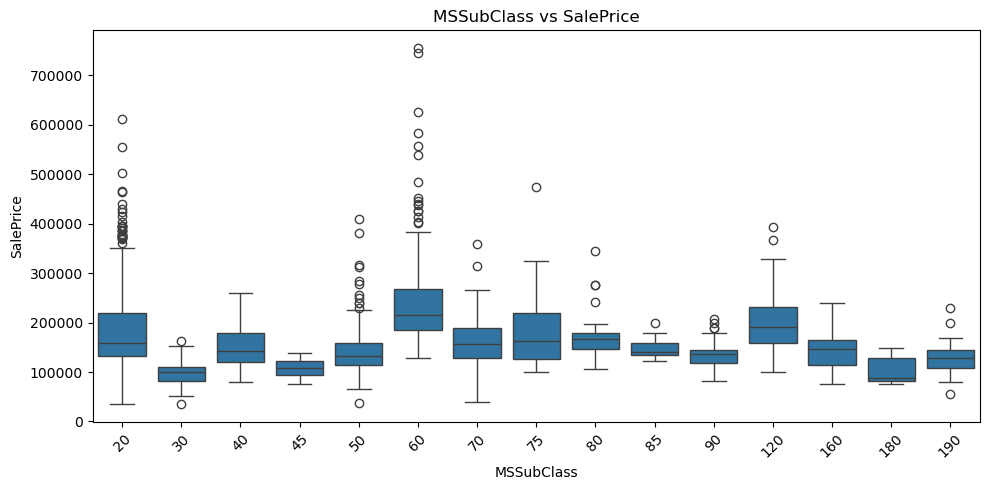

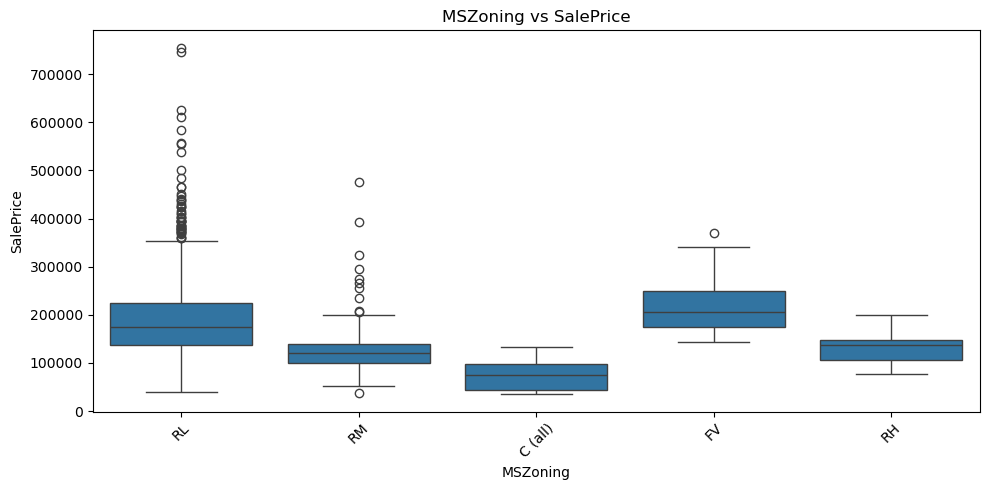

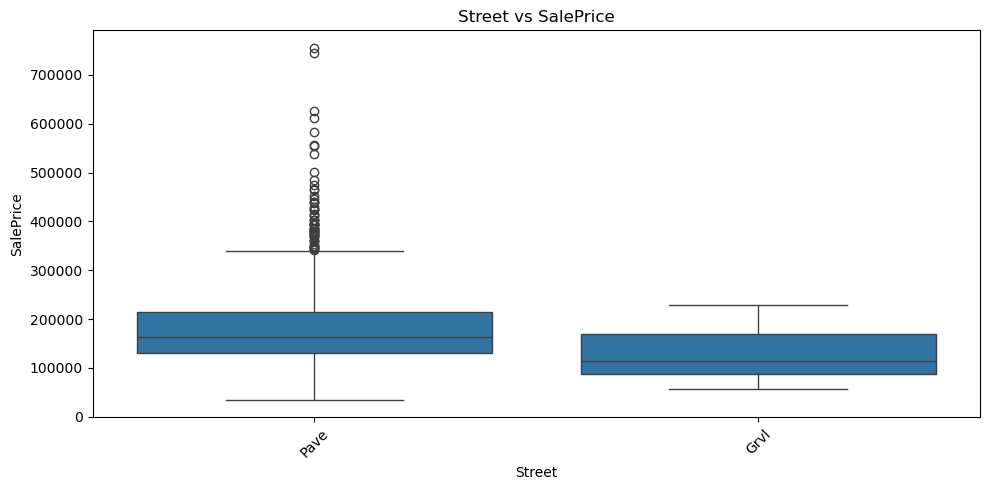

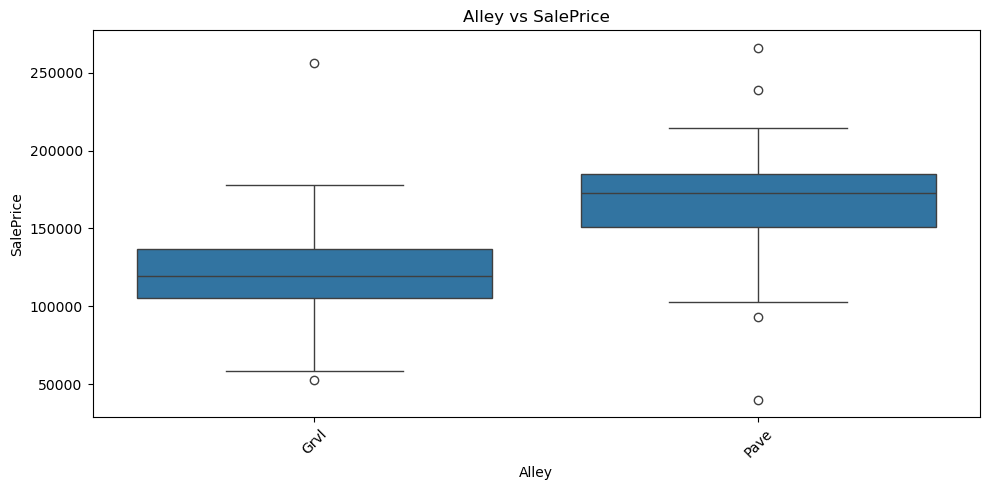

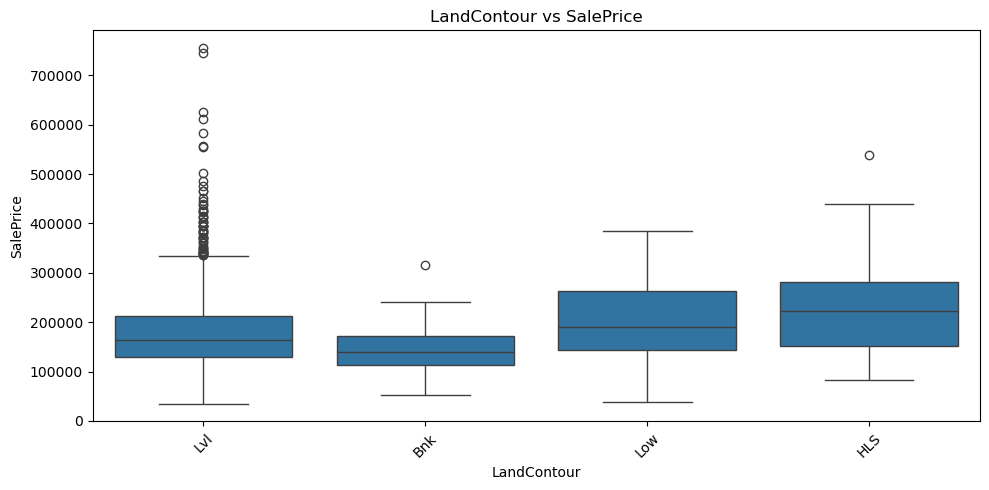

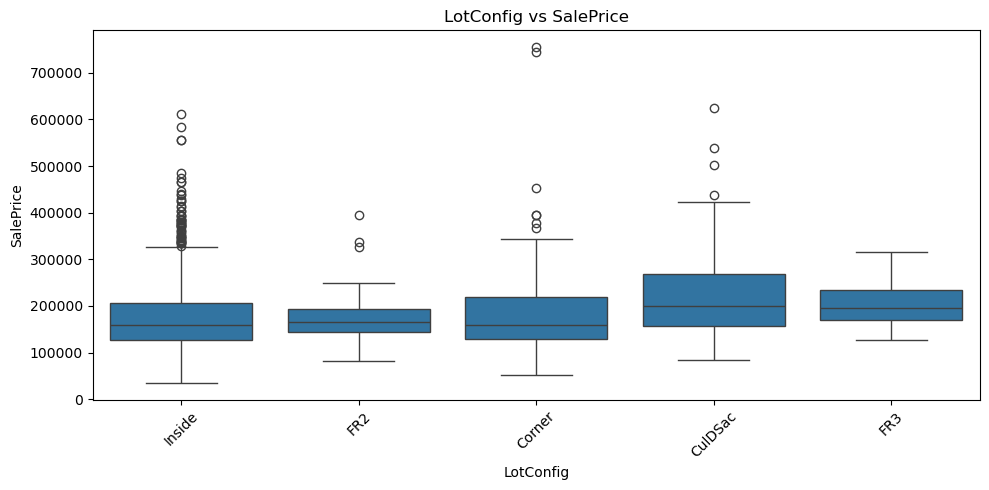

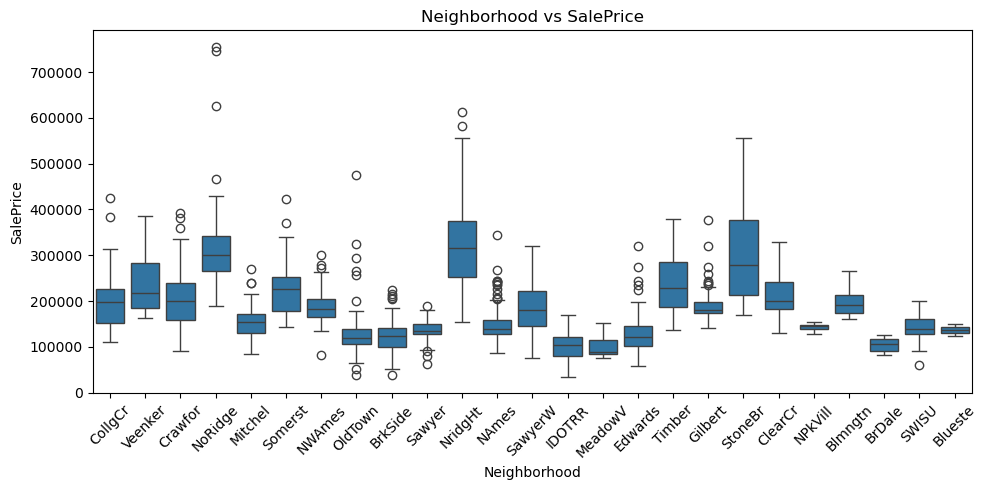

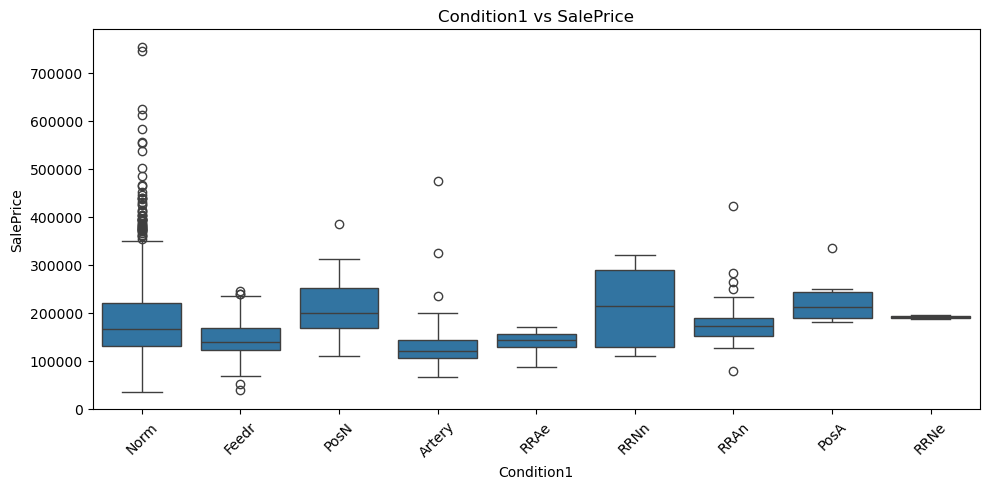

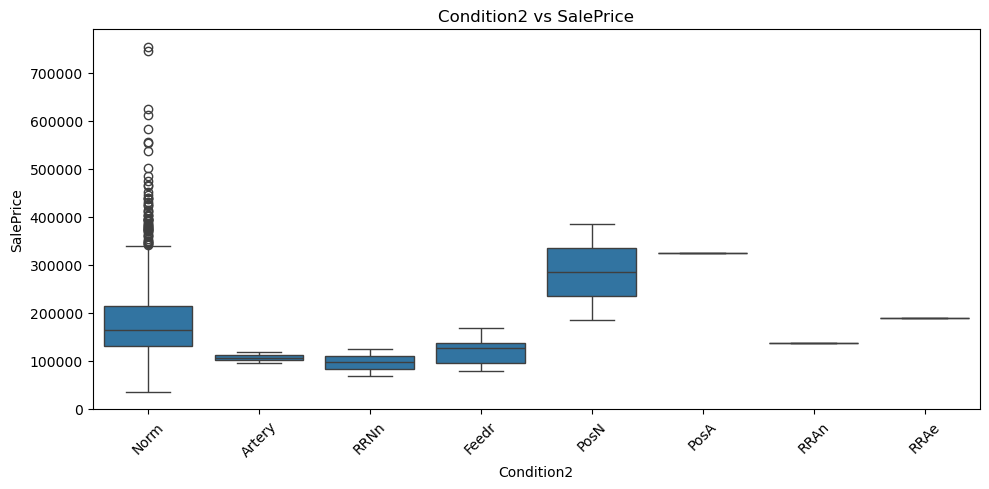

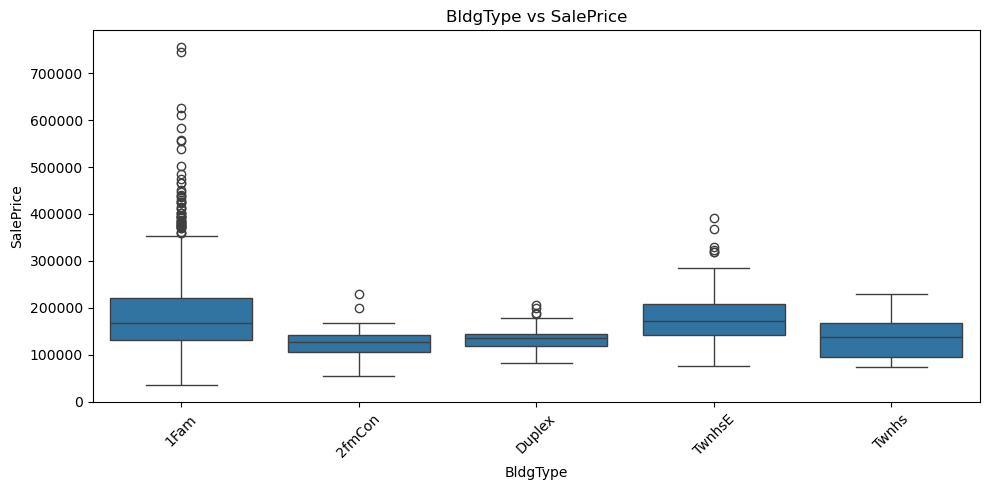

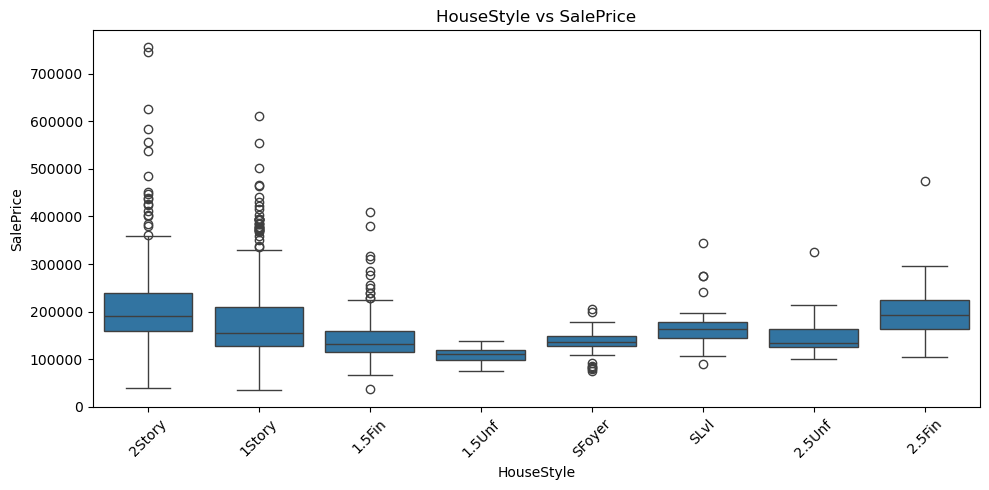

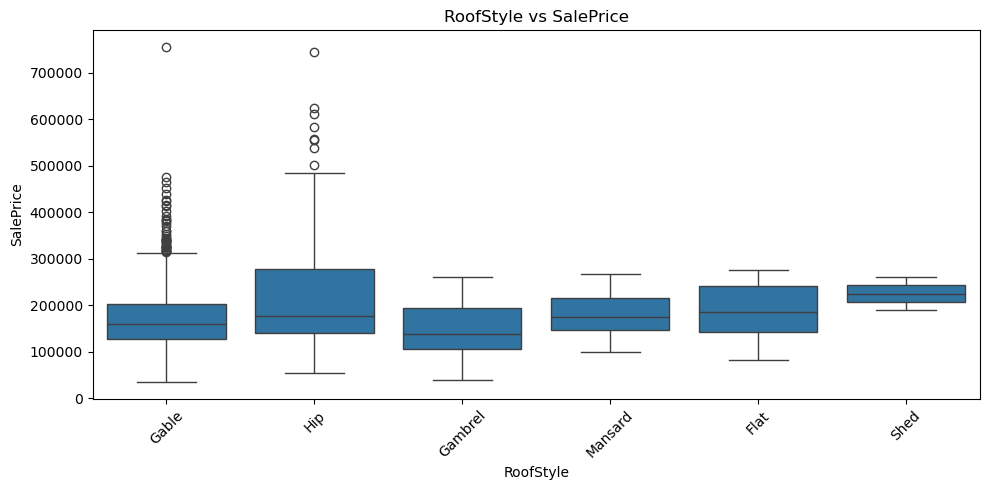

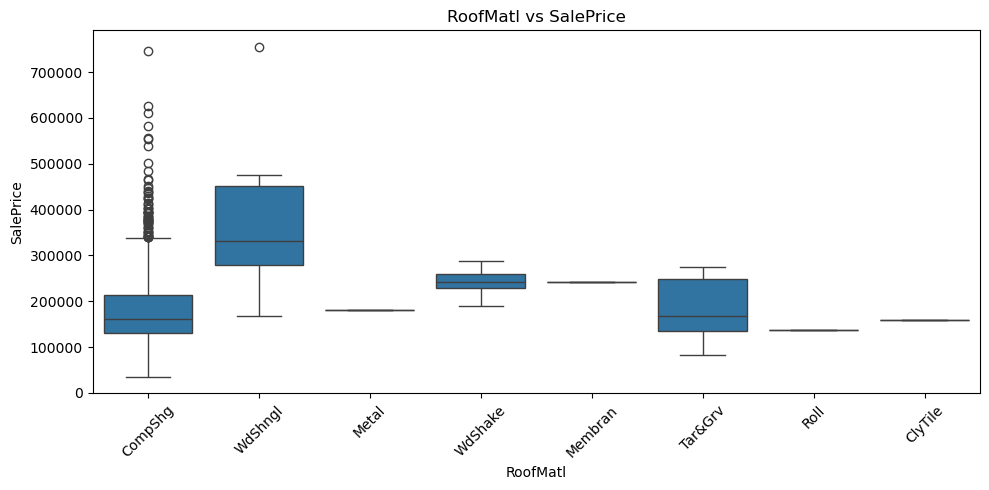

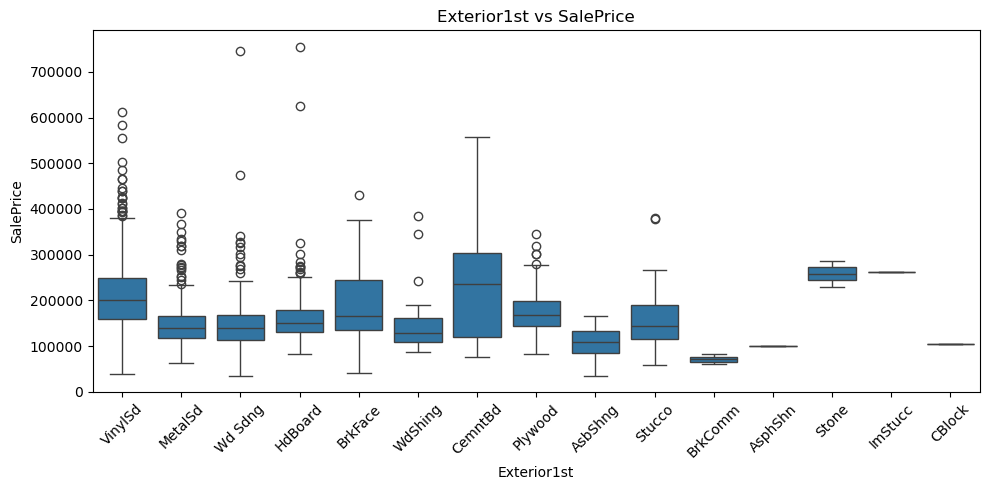

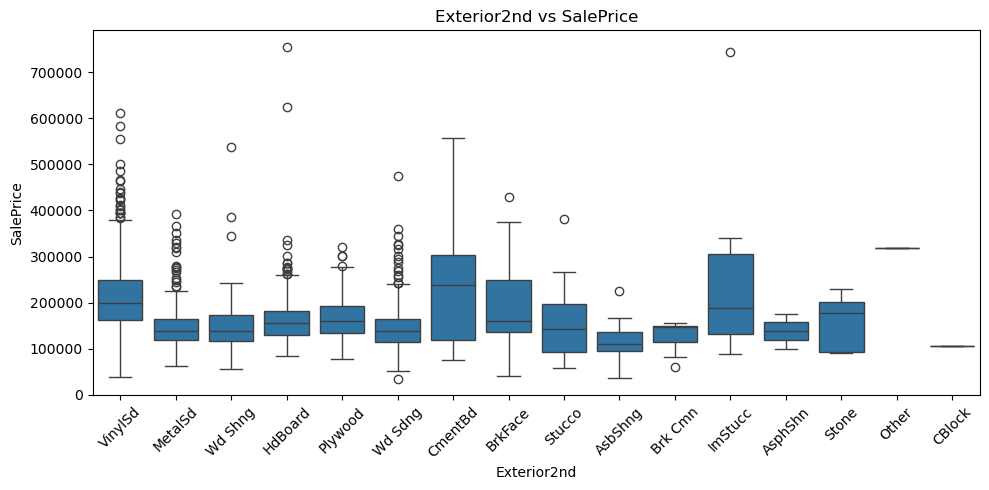

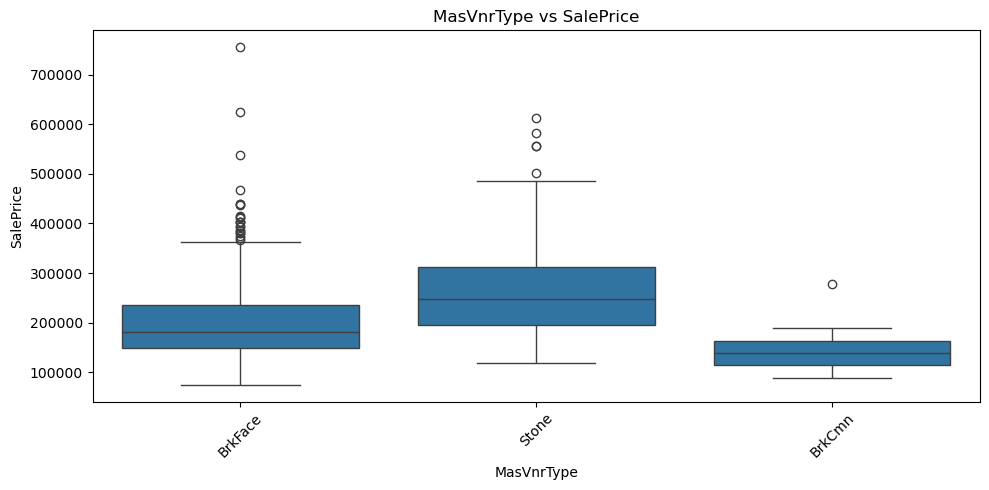

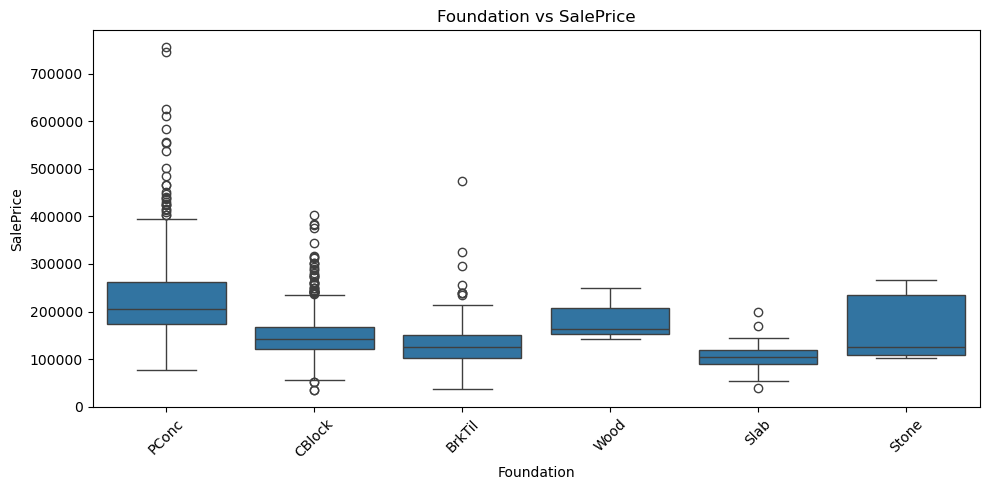

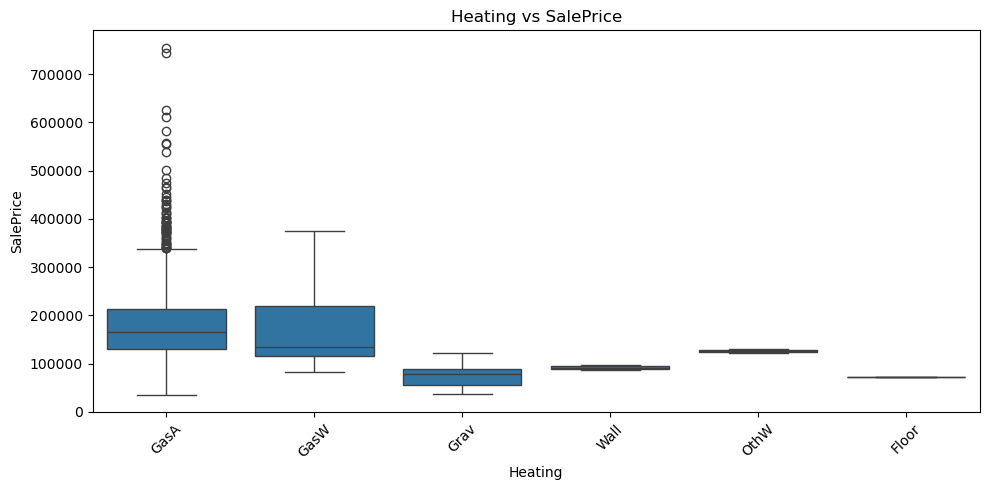

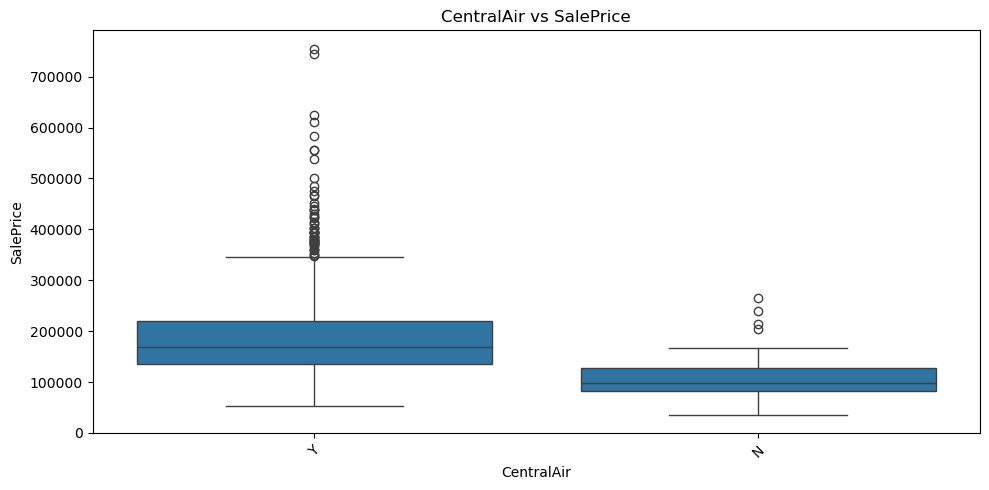

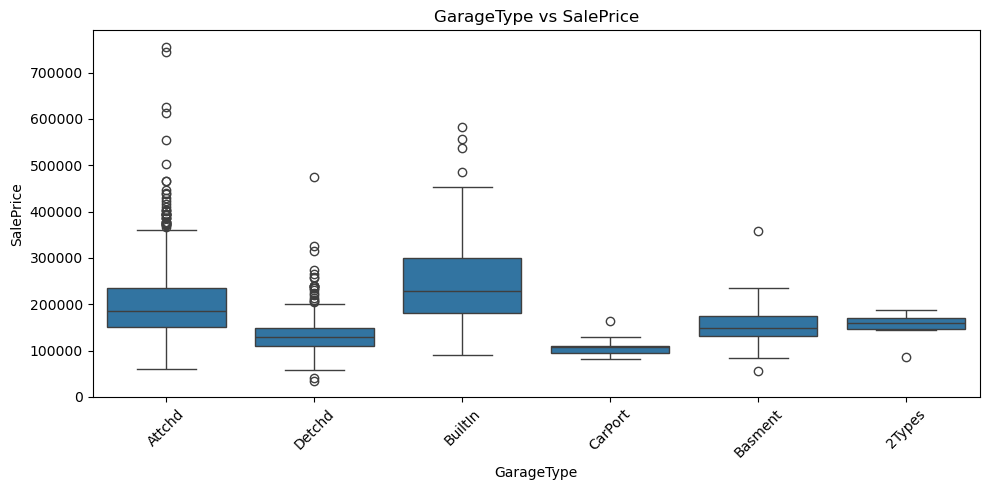

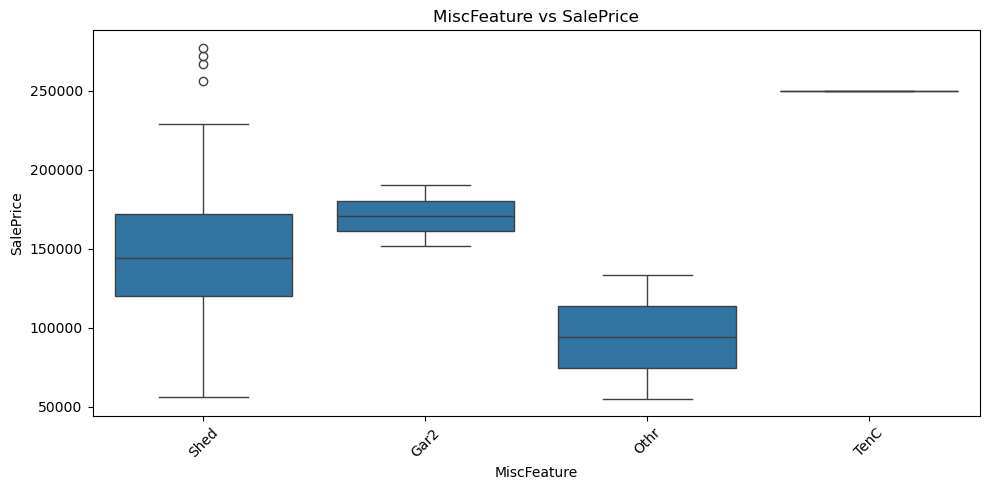

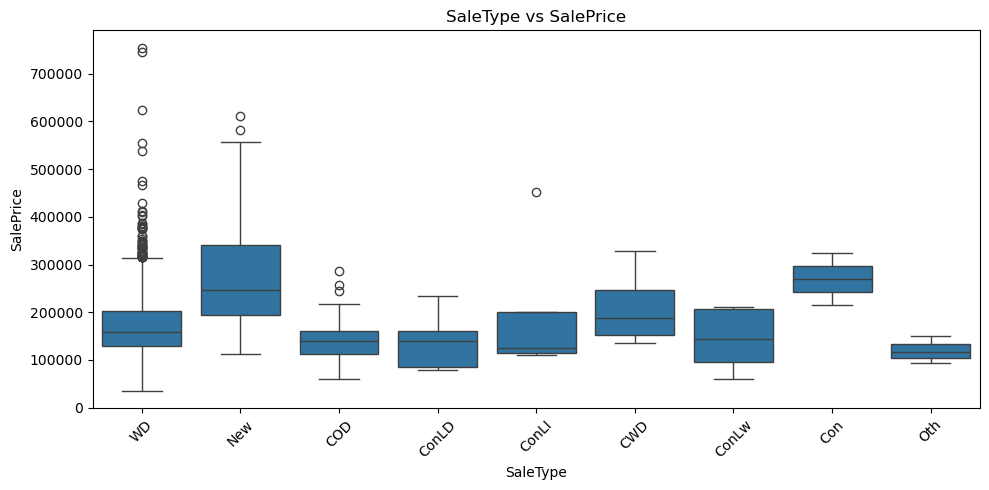

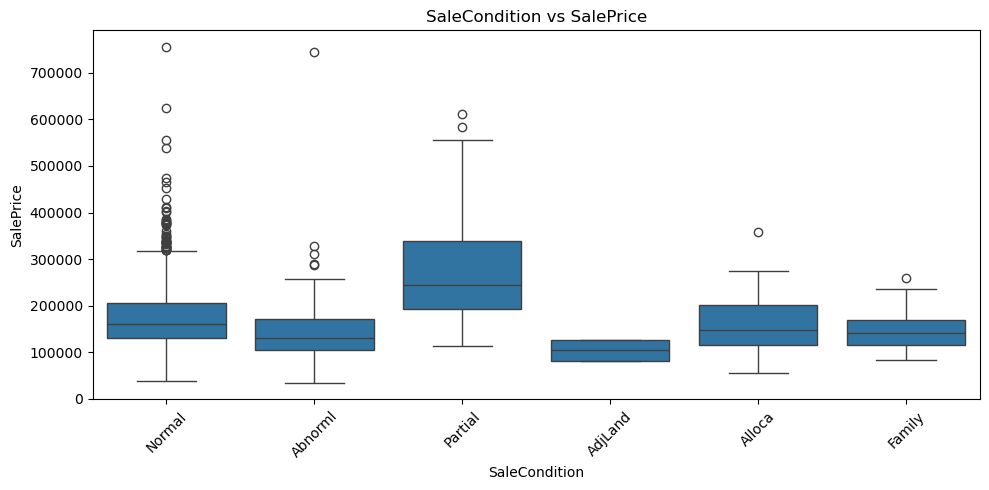

In [ ]:
for col in nominal_vars:

    plt.figure(figsize=(10, 5))

    sns.boxplot(
        data=train,
        x=col,
        y="SalePrice"
    )

    plt.title(f"{col} vs SalePrice")
    plt.xlabel(col)
    plt.ylabel("SalePrice")

    plt.xticks(rotation=45)

    plt.tight_layout()
    plt.show()

## Correlation

In [ ]:
numeric_data = train.select_dtypes(include="number")
correlation_matrix = numeric_data.corr()
correlation_matrix

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
Id,1.000000,0.011156,-0.010601,-0.033226,-0.028365,0.012609,-0.012713,-0.021998,-0.050298,-0.005024,...,-0.029643,-0.000477,0.002889,-0.046635,0.001330,0.057044,-0.006242,0.021172,0.000712,-0.021917
MSSubClass,0.011156,1.000000,-0.386347,-0.139781,0.032628,-0.059316,0.027850,0.040581,0.022936,-0.069836,...,-0.012579,-0.006100,-0.012037,-0.043825,-0.026030,0.008283,-0.007683,-0.013585,-0.021407,-0.084284
LotFrontage,-0.010601,-0.386347,1.000000,0.426095,0.251646,-0.059213,0.123349,0.088866,0.193458,0.233633,...,0.088521,0.151972,0.010700,0.070029,0.041383,0.206167,0.003368,0.011200,0.007450,0.351799
LotArea,-0.033226,-0.139781,0.426095,1.000000,0.105806,-0.005636,0.014228,0.013788,0.104160,0.214103,...,0.171698,0.084774,-0.018340,0.020423,0.043160,0.077672,0.038068,0.001205,-0.014261,0.263843
OverallQual,-0.028365,0.032628,0.251646,0.105806,1.000000,-0.091932,0.572323,0.550684,0.411876,0.239666,...,0.238923,0.308819,-0.113937,0.030371,0.064886,0.065166,-0.031406,0.070815,-0.027347,0.790982
OverallCond,0.012609,-0.059316,-0.059213,-0.005636,-0.091932,1.000000,-0.375983,0.073741,-0.128101,-0.046231,...,-0.003334,-0.032589,0.070356,0.025504,0.054811,-0.001985,0.068777,-0.003511,0.043950,-0.077856
YearBuilt,-0.012713,0.027850,0.123349,0.014228,0.572323,-0.375983,1.000000,0.592855,0.315707,0.249503,...,0.224880,0.188686,-0.387268,0.031355,-0.050364,0.004950,-0.034383,0.012398,-0.013618,0.522897
YearRemodAdd,-0.021998,0.040581,0.088866,0.013788,0.550684,0.073741,0.592855,1.000000,0.179618,0.128451,...,0.205726,0.226298,-0.193919,0.045286,-0.038740,0.005829,-0.010286,0.021490,0.035743,0.507101
MasVnrArea,-0.050298,0.022936,0.193458,0.104160,0.411876,-0.128101,0.315707,0.179618,1.000000,0.264736,...,0.159718,0.125703,-0.110204,0.018796,0.061466,0.011723,-0.029815,-0.005965,-0.008201,0.477493
BsmtFinSF1,-0.005024,-0.069836,0.233633,0.214103,0.239666,-0.046231,0.249503,0.128451,0.264736,1.000000,...,0.204306,0.111761,-0.102303,0.026451,0.062021,0.140491,0.003571,-0.015727,0.014359,0.386420


## Heatmap

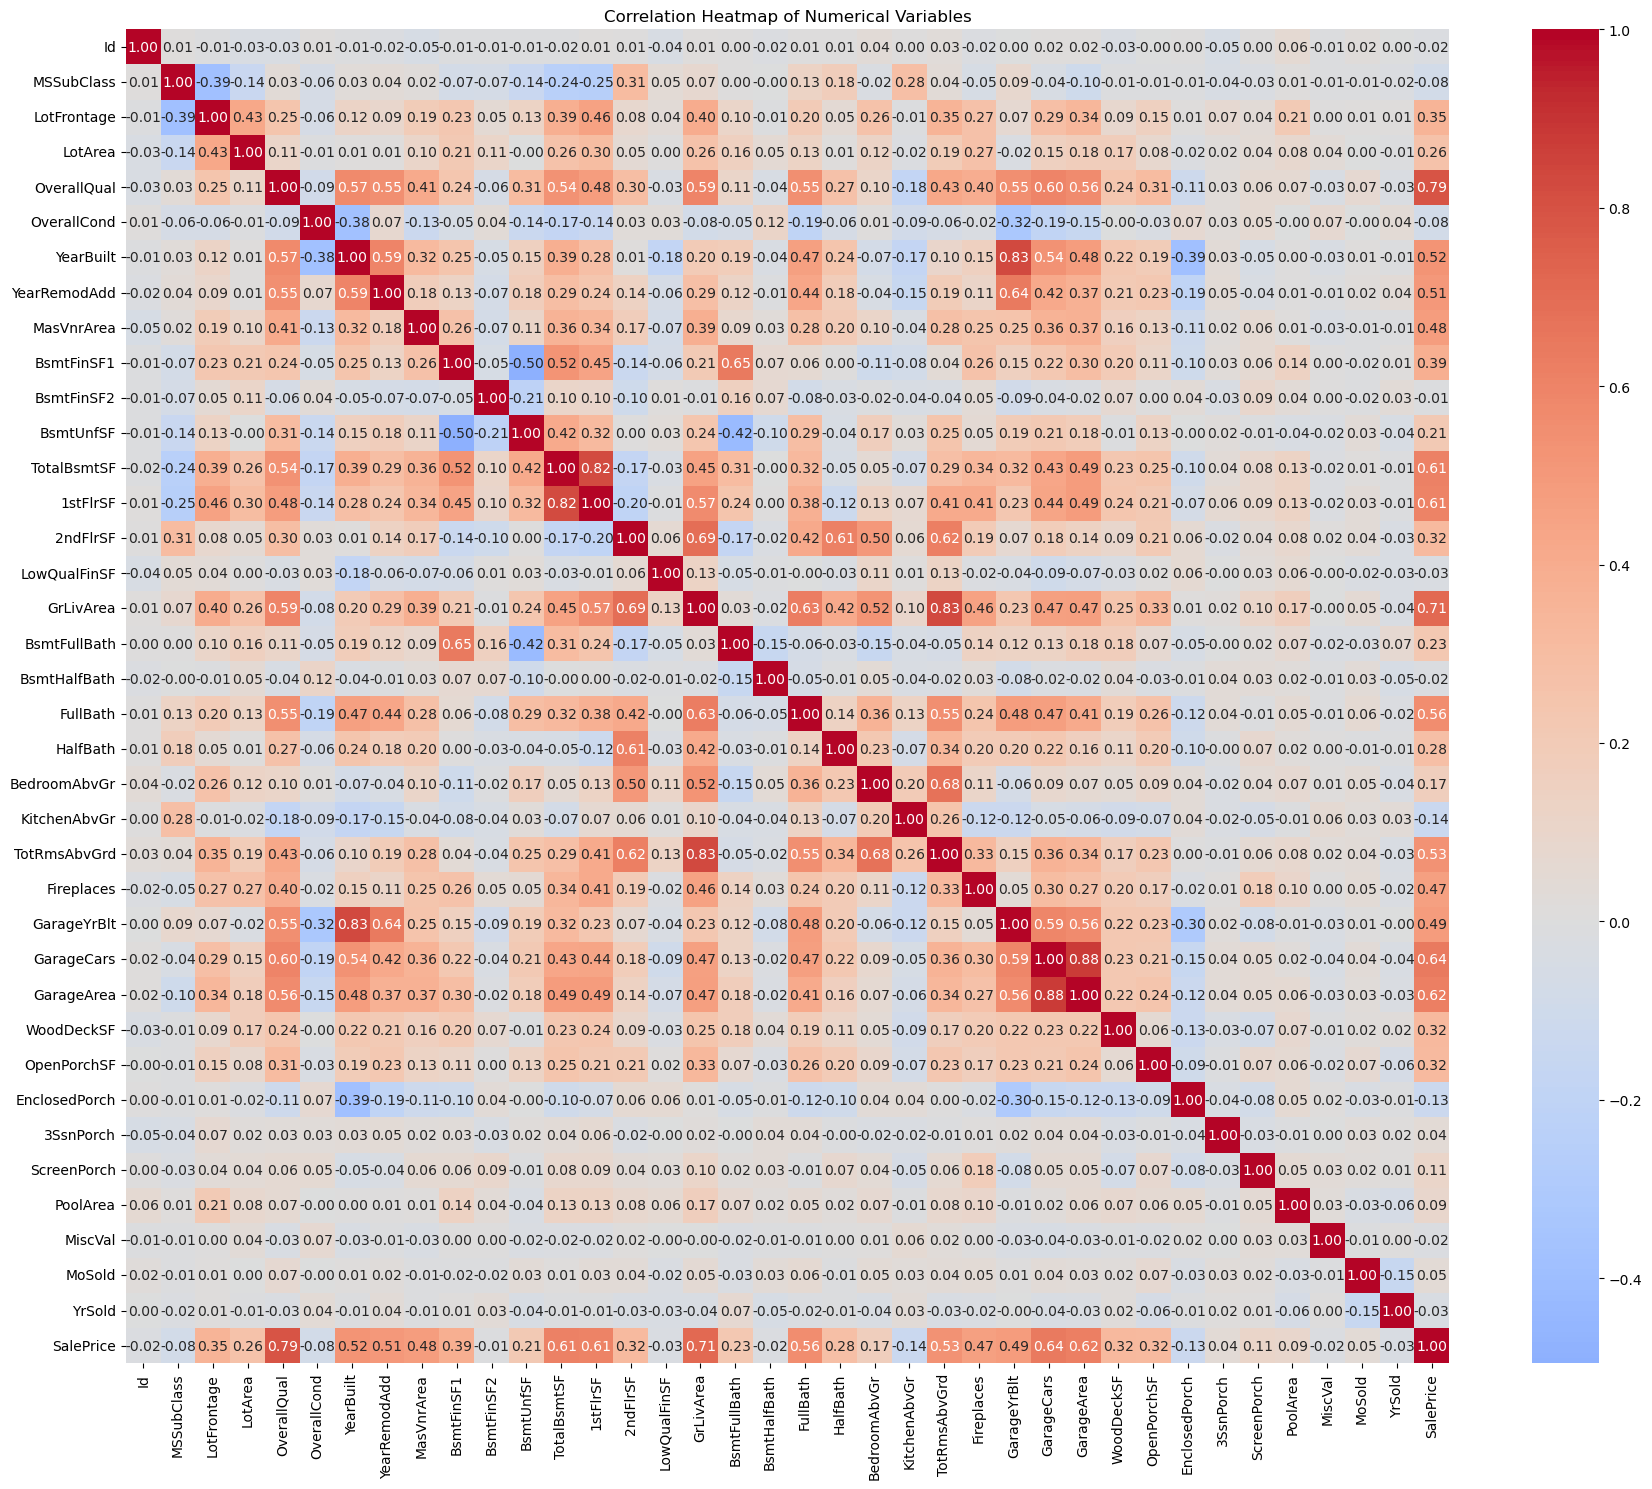

In [ ]:
plt.figure(figsize=(18, 15))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Heatmap of Numerical Variables")
plt.tight_layout()
plt.show()

# Xác định giá trị thiếu

## Số lượng và tỉ lệ missing từng biến

In [ ]:
missing_table = pd.DataFrame({
    "Missing Count": train.isnull().sum(),
    "Missing Percent": train.isnull().mean() * 100
})

missing_table = missing_table[
    missing_table["Missing Count"] > 0
].sort_values(
    by="Missing Count",
    ascending=False
)

missing_table

,Missing Count,Missing Percent
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


## Kiểm tra bất thường

In [ ]:
missing_per_row = train.isnull().sum(axis=1)

print(missing_per_row.describe())
train.loc[
    missing_per_row.sort_values(ascending=False).head(10).index
]

count    1460.000000
mean        5.362329
std         1.854792
min         1.000000
25%         4.000000
50%         5.000000
75%         6.000000
max        16.000000
dtype: float64


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
533,534,20,RL,50.0,5000,Pave,NaN,Reg,Low,AllPub,...,0,NaN,NaN,NaN,0,1,2007,WD,Normal,39300
1218,1219,50,RM,52.0,6240,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,80500
1011,1012,90,RL,75.0,9825,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,100000
39,40,90,RL,65.0,6040,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,AdjLand,82000
1179,1180,20,RL,77.0,8335,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2006,WD,Normal,93000
520,521,190,RL,60.0,10800,Pave,Grvl,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2008,WD,Normal,106250
705,706,190,RM,70.0,5600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,Othr,3500,7,2010,WD,Normal,55000
1035,1036,20,RL,NaN,11500,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2009,WD,Normal,84000
287,288,20,RL,NaN,8125,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2006,WD,Normal,88000
1143,1144,20,RL,NaN,9000,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,80000


## Kiểm tra giá trị âm bất hợp lý

In [ ]:
non_negative_vars = [
    "LotArea",
    "MasVnrArea",
    "BsmtFinSF1",
    "BsmtFinSF2",
    "BsmtUnfSF",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "LowQualFinSF",
    "GrLivArea",
    "GarageArea",
    "WoodDeckSF",
    "OpenPorchSF",
    "EnclosedPorch",
    "3SsnPorch",
    "ScreenPorch",
    "PoolArea",
    "MiscVal"
]

negative_values = {}

for col in non_negative_vars:
    count = (train[col] < 0).sum()

    if count > 0:
        negative_values[col] = count

print("Các biến có giá trị âm:")
print(negative_values)

Các biến có giá trị âm:
{}


## Kiểm tra bất thường biến Garage

In [ ]:
garage_anomaly = train[
    (train["GarageCars"] > 0) &
    (train["GarageArea"] == 0)
]

garage_anomaly

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Kiểm tra bất thường tầng hầm

In [ ]:
basement_anomaly = train[
    (train["TotalBsmtSF"] > 0) &
    (
        train["BsmtFinSF1"].fillna(0)
        + train["BsmtFinSF2"].fillna(0)
        + train["BsmtUnfSF"].fillna(0)
        > train["TotalBsmtSF"]
    )
]

basement_anomaly

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
